# 🕵️ The Podium Case File — a detective-style EDA of F1 1950–2024

**The case:** for every driver in every race, predict whether they finish on the podium (`positionOrder <= 3`) using only what is known *after qualifying and before lights out*.

**How this notebook works.** We don't run a checklist. We start at the scene (the raw files), and every clue we find raises the question that the next section investigates. Each section ends with a **🔎 Lead** — the open question that sends us to the next clue — and every finding is logged with `note(...)` into a case log that is printed at the end as a *findings → decisions* table (ready to paste into the report).

| # | Clue | Question it answers | Brief requirement |
|---|------|---------------------|-------------------|
| 0 | The scene | What files do we have, and what era does each one cover? | EDA (before cleaning) |
| 1 | The `\N` fingerprints | What does "missing" look like, and are the types real? | Sentinels, semantic typing |
| 2 | The paper trail | Do the keys hold? Do the tables reconcile? | PK / FK audit |
| 3 | The driver who was in two cars | Is `(raceId, driverId)` unique? | Grain fix + rule |
| 4 | Counting the podium | Is the target what we think it is? Why do base rates move? | Target audit, Indy 500 |
| 5 | Entered but never started | Who belongs in the modeling table? | Row population |
| 6 | Qualifying ≠ grid | How much qualifying data exists, and when does it differ from the grid? | Coverage drift, DE-Q1 setup |
| 7 | The prime suspect: grid | How predictive is the start position, and is it stable across eras? | Feature evidence |
| 8 | The impostors | Which columns are post-race information in disguise? | Leakage screen |
| 9 | The alibi check | Can we build form/standings features that only look backwards? | Leakage-safe form |
| 10 | Why cars stop | How do retirement causes group, and how did reliability change? | Status mapping, DE-Q3 setup |
| 11 | Home advantage? | Can nationality be joined to circuit country? | DE-Q2 setup |
| 12 | Identity drift | Do teams and drivers keep stable identities? | Feature caveats |
| 13 | The sprint question | Is the sprint pre-race information? | Leakage judgement |
| 14 | Different eras, different worlds | Does the proposed split see the same world? | Split justification |
| 15 | Before vs after | What did cleaning change? | EDA after cleaning |
| II | Cleaning pipeline | One function, a ledger, invariants, before/after | Cleaning |
| III | DE-Q1 · Q2 · Q3 | Answers with joins, grain, missingness, cutoff | Data-engineering questions |
| IV | Features · selection · split · preprocessing | Leakage-safe features, train-only evidence, order experiments | Feature selection & engineering |
| 🗂 | Case closed | Findings → decisions (all parts) | Report material |

> 🗃 **Merged evidence.** Cells marked 🗃 come from our first-pass EDA and were folded in where they strengthen a clue.

### A term used throughout: *grain*
**Grain = what one row represents.** In `races.csv` one row is one race; in `results.csv` a row is *approximately* one driver in one race; in `lap_times.csv` one driver's lap; in `pit_stops.csv` one pit stop. Our modeling grain must be **one driver entering one race**, so joining a per-lap table straight onto it would repeat each driver-race dozens of times. Knowing every table's grain comes before any join.

> **Run-all ready.** The data directory is found automatically (Kaggle input or a local `data/` folder). Raw CSVs are read as strings and never modified; every cleaned table is a copy.

## Setup

In [247]:
import re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score
from IPython.display import display, Markdown
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable, Table2x2

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.titleweight": "bold", "axes.titlesize": 12})

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

CASE_LOG = []
def note(clue, finding, decision):
    # Log a finding and the decision it drives; printed as a table at the end.
    CASE_LOG.append({"clue": clue, "finding": finding, "decision": decision})
    display(Markdown(f"> 📝 **Logged ({clue})** — {finding}  \n> ➜ *{decision}*"))

def auc_safe(y, score):
    # ROC-AUC on rows where both are present; reported as max(AUC, 1-AUC) is NOT done,
    # so a value < 0.5 means 'higher score -> less podium'.
    m = pd.notna(y) & pd.notna(score)
    y, score = np.asarray(y)[m], np.asarray(score)[m]
    if len(np.unique(y)) < 2: return np.nan
    return roc_auc_score(y, score)

def pct(x, d=1): return f"{100*x:.{d}f}%"

In [248]:
# Locate the dataset: Kaggle input mount first, then local folders.
def find_data_dir():
    for c in [Path("/kaggle/input/formula-1-world-championship-1950-2020"), Path("data"), Path("../data"), Path(".")]:
        if (c / "results.csv").exists():
            return c
    k = Path("/kaggle/input")
    if k.exists():
        hits = sorted(k.rglob("results.csv"))
        if hits: return hits[0].parent
    raise FileNotFoundError("results.csv not found. Attach the Kaggle dataset or put the CSVs in ./data/")

DATA_DIR = find_data_dir()
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "sprint_results", "seasons", "status"]

def read_raw(path):
    # Everything as text, no automatic NA handling: we want to SEE the raw sentinels.
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, dtype=str, keep_default_na=False, na_filter=False, encoding=enc)
        except UnicodeDecodeError:
            continue

raw = {t: read_raw(DATA_DIR / f"{t}.csv") for t in TABLES if (DATA_DIR / f"{t}.csv").exists()}
print("Data dir:", DATA_DIR.resolve())
print("Loaded:", len(raw), "of", len(TABLES), "tables.", "Missing:", [t for t in TABLES if t not in raw] or "none")

Data dir: C:\Users\ahmed\OneDrive\Desktop\Uni\Semester 9\ACL\project\AI-Tools-Lab-F1-Project\data
Loaded: 14 of 14 tables. Missing: none


---
## Clue 0 — The scene: what's in the evidence box?

Before touching anything, we inventory the files and ask a deceptively simple question: **which seasons does each table actually cover?** The brief treats this as one dataset "1950–2024", but a relational dataset is often stitched together from sources that start at different times. If some tables start late, every feature built from them will be missing for the early decades.

In [249]:
inv = pd.DataFrame([{"table": t, "rows": len(d), "cols": d.shape[1], "columns": ", ".join(d.columns)}
                    for t, d in raw.items()]).sort_values("rows", ascending=False)
display(inv.style.format({"rows": "{:,}"}).hide(axis="index"))

table,rows,cols,columns
lap_times,"589,081",6,"raceId, driverId, lap, position, time, milliseconds"
driver_standings,"34,863",7,"driverStandingsId, raceId, driverId, points, position, positionText, wins"
results,"26,759",18,"resultId, raceId, driverId, constructorId, number, grid, position, positionText, positionOrder, points, laps, time, milliseconds, fastestLap, rank, fastestLapTime, fastestLapSpeed, statusId"
constructor_standings,"13,391",7,"constructorStandingsId, raceId, constructorId, points, position, positionText, wins"
constructor_results,"12,625",5,"constructorResultsId, raceId, constructorId, points, status"
pit_stops,"11,371",7,"raceId, driverId, stop, lap, time, duration, milliseconds"
qualifying,"10,494",9,"qualifyId, raceId, driverId, constructorId, number, position, q1, q2, q3"
races,"1,125",18,"raceId, year, round, circuitId, name, date, time, url, fp1_date, fp1_time, fp2_date, fp2_time, fp3_date, fp3_time, quali_date, quali_time, sprint_date, sprint_time"
drivers,861,9,"driverId, driverRef, number, code, forename, surname, dob, nationality, url"
sprint_results,360,16,"resultId, raceId, driverId, constructorId, number, grid, position, positionText, positionOrder, points, laps, time, milliseconds, fastestLap, fastestLapTime, statusId"


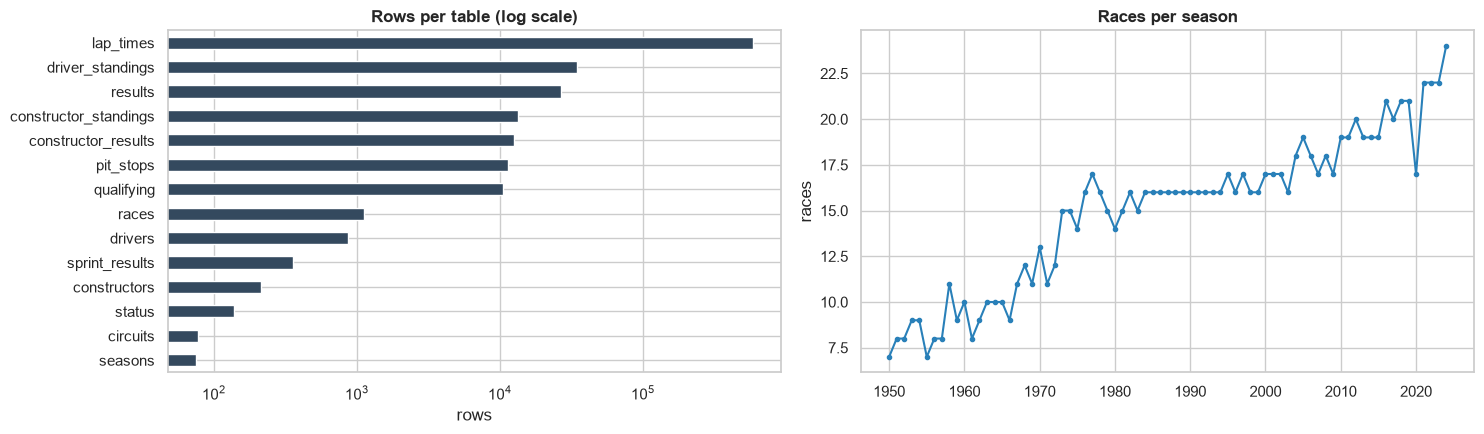

In [250]:
# 🗃 First-pass EDA: table sizes on one log axis, and how the calendar itself grew.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
inv.sort_values("rows").plot.barh(x="table", y="rows", ax=axes[0], logx=True, legend=False, color="#34495e")
axes[0].set_title("Rows per table (log scale)"); axes[0].set_xlabel("rows"); axes[0].set_ylabel("")
rpy = raw["races"].assign(year=lambda d: d.year.astype(int)).groupby("year").size()
axes[1].plot(rpy.index, rpy.values, marker="o", ms=3, color="#2980b9")
axes[1].set_title("Races per season"); axes[1].set_xlabel(""); axes[1].set_ylabel("races")
plt.tight_layout(); plt.show()

Two kinds of table are mixed here: **entity** tables (`drivers`, `constructors`, `circuits`, `status`) with one row per thing, and **event** tables (`results`, `lap_times`, `pit_stops`, standings) with one row per thing-per-race, or per lap. > **What's a *round*?** A season is a sequence of races; `round` is the race's **number within its season** (round 1 = season opener, round 22 = 22nd race that year). `(year, round)` therefore pins down one race and gives the order of races inside a season — which is exactly what "standings *before* this race" and "last 5 races" need.

Season length roughly tripled, so "season" and "round" are not interchangeable units of time: chronology has to come from `date`/`round`, which also makes a **time-based split** the natural choice.

,first season,last season,seasons present
races,1950,2024,75
driver_standings,1950,2024,75
results,1950,2024,75
constructor_standings,1958,2024,67
constructor_results,1958,2024,67
qualifying,1994,2024,31
lap_times,1996,2024,29
pit_stops,2011,2024,14
sprint_results,2021,2024,4


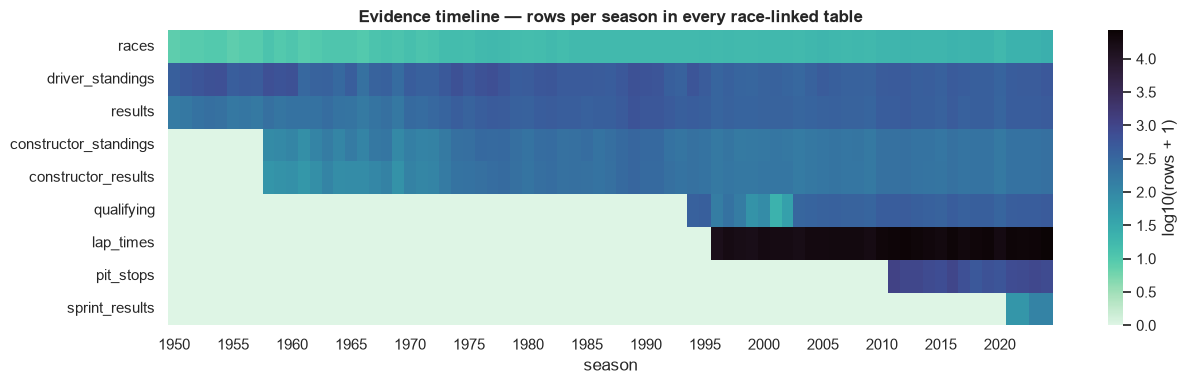

In [251]:
race_year = raw["races"][["raceId", "year"]].copy()
race_year["year"] = race_year["year"].astype(int)

cov_rows = []
for t, d in raw.items():
    if "raceId" in d.columns:
        yrs = d[["raceId"]].merge(race_year, on="raceId", how="left")["year"]
        cov_rows.append(yrs.value_counts().rename(t))
coverage = pd.concat(cov_rows, axis=1).sort_index().fillna(0)

span = pd.DataFrame({"first season": coverage.apply(lambda s: s[s > 0].index.min()),
                     "last season": coverage.apply(lambda s: s[s > 0].index.max()),
                     "seasons present": (coverage > 0).sum()}).sort_values("first season")
display(span)

fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(np.log10(coverage[span.index].T + 1), cmap="mako_r", cbar_kws={"label": "log10(rows + 1)"}, ax=ax)
ax.set_title("Evidence timeline — rows per season in every race-linked table")
ax.set_xlabel("season"); ax.set_ylabel("")
xt = [i for i, y in enumerate(coverage.index) if y % 5 == 0]
ax.set_xticks([i + .5 for i in xt]); ax.set_xticklabels([coverage.index[i] for i in xt], rotation=0)
plt.tight_layout(); plt.show()

**What to read off the timeline:** `results`, `races` and the standings tables span the full history, but the "rich" tables (`qualifying`, `lap_times`, `pit_stops`, `sprint_results`) switch on decades later. Note the first season of each — they are the boundaries of *historical coverage drift* the brief warns about.

Also check the right edge: if `races` extends past `results`, the calendar includes races that hadn't been run when the snapshot was taken (rows with no outcome — they can't be labelled).

In [252]:
races_without_results = set(raw["races"]["raceId"]) - set(raw["results"]["raceId"])
ry = race_year[race_year.raceId.isin(races_without_results)]
print(f"Races with no results rows: {len(races_without_results)}; seasons: {sorted(ry.year.unique().tolist())}")
note("0 · Scene",
     f"Tables start at different seasons: qualifying from {int(span.loc['qualifying','first season']) if 'qualifying' in span.index else 'n/a'}, "
     f"lap_times from {int(span.loc['lap_times','first season']) if 'lap_times' in span.index else 'n/a'}, "
     f"pit_stops from {int(span.loc['pit_stops','first season']) if 'pit_stops' in span.index else 'n/a'}; "
     f"{len(races_without_results)} calendar races have no results.",
     "Features from late-starting tables will be structurally missing for early seasons; races without results are dropped (no label).")

Races with no results rows: 0; seasons: []


> 📝 **Logged (0 · Scene)** — Tables start at different seasons: qualifying from 1994, lap_times from 1996, pit_stops from 2011; 0 calendar races have no results.  
> ➜ *Features from late-starting tables will be structurally missing for early seasons; races without results are dropped (no label).*

🔎 **Lead:** the files load, but everything is text. Before we can count anything, we need to know what "missing" looks like in this dataset.

---
## Clue 1 — The `\N` fingerprints: what does "missing" look like?

The Ergast export writes NULL as the literal two-character string `\N`. Pandas would happily keep it as text, which silently turns numeric columns into `object` and makes `.isna()` lie. We scan every column of every table for **three kinds of sentinel**: `\N`, empty strings, and spelled-out nulls.

Columns containing a sentinel: 30 of 120 | total \N cells: 160,076 | empty: 68 | spelled nulls: 0


,backslash_N,empty_str,spelled_null
table,,,
results,122887,0,0
constructor_results,12608,0,0
qualifying,11600,68,0
races,11349,0,0
drivers,1559,0,0
sprint_results,73,0,0
driver_standings,0,0,0
constructors,0,0,0
constructor_standings,0,0,0


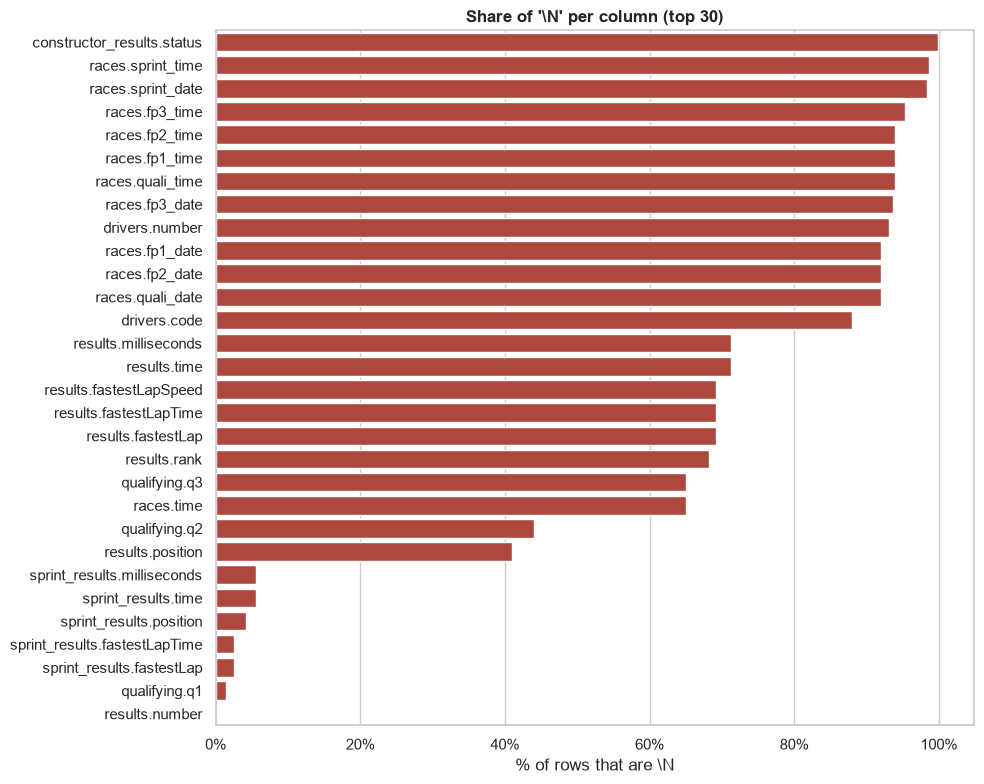

In [253]:
def sentinel_profile(d, name):
    rows = []
    for c in d.columns:
        s = d[c]
        rows.append({"table": name, "column": c, "n": len(s),
                     "backslash_N": int((s == "\\N").sum()),
                     "empty_str": int((s.str.strip() == "").sum()),
                     "spelled_null": int(s.str.lower().isin(["null", "nan", "na", "none"]).sum())})
    return pd.DataFrame(rows)

sent = pd.concat([sentinel_profile(d, t) for t, d in raw.items()], ignore_index=True)
sent["pct_N"] = 100 * sent.backslash_N / sent.n
hit = sent[(sent.backslash_N + sent.empty_str + sent.spelled_null) > 0].sort_values("pct_N", ascending=False)
print(f"Columns containing a sentinel: {len(hit)} of {len(sent)} | total \\N cells: {sent.backslash_N.sum():,} "
      f"| empty: {sent.empty_str.sum():,} | spelled nulls: {sent.spelled_null.sum():,}")
display(sent.groupby("table")[["backslash_N", "empty_str", "spelled_null"]].sum().sort_values("backslash_N", ascending=False))

top = hit.head(30).assign(label=lambda x: x.table + "." + x.column)
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=top, y="label", x="pct_N", color="#c0392b", ax=ax)
ax.set_title(r"Share of '\N' per column (top 30)"); ax.set_xlabel("% of rows that are \\N"); ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout(); plt.show()

Not all `\N` mean the same thing — this matters for how we treat them later:

* **Structural "not applicable"**: `results.position` is `\N` when the driver wasn't classified (that's *information*, see `positionText`); `qualifying.q2/q3` are `\N` for drivers knocked out earlier.
* **Not recorded in that era**: fastest-lap columns, `milliseconds`, `drivers.code/number` for historical drivers.
* **Truly unknown**: rare, but possible anywhere.

There is also a **disguised sentinel** that the scan above can't catch: the number `0`. Let's check where zeros show up in columns where zero is physically odd.

In [254]:
r_raw = raw["results"]
for col in ["grid", "laps", "number"]:
    if col in r_raw.columns:
        print(f"results.{col} == '0': {(r_raw[col] == '0').sum():,} rows ({pct((r_raw[col] == '0').mean())})")
print("circuits.alt == '0' or \\N:", ((raw['circuits']['alt'] == '0') | (raw['circuits']['alt'] == '\\N')).sum() if 'alt' in raw['circuits'] else 'n/a')

results.grid == '0': 1,638 rows (6.1%)
results.laps == '0': 2,532 rows (9.5%)
results.number == '0': 34 rows (0.1%)
circuits.alt == '0' or \N: 2


`grid == 0` is the interesting one: the intro doc says it means a **pit-lane start**, but it may also encode "never got a grid slot". We park it for Clue 5.

### Semantic typing — why convert types during *EDA*?
Because we can't explore what we can't compute. While every column is text, `grid` sorts as `"1" < "10" < "2"`, `\N` hides inside "numeric" columns, `"1:26.572"` can't be averaged and dates can't be ordered — every plot that follows would be wrong or impossible. So typing is a *prerequisite* for EDA, not a cleaning decision:

* it **doesn't change information**: `\N` → `NaN` and `"1:26.572"` → `86.572` are the same facts in a usable form;
* it happens on **copies** (`df`), the untouched text versions stay in `raw` — so "before" EDA is still possible (Clue 15 uses `raw`);
* the real *decisions* (which rows to drop, how to impute, how to collapse duplicates) come later and are logged explicitly.

In the report this sits under *Data cleaning → sentinels & semantic typing* (it's on the brief's checklist); in the notebook it lives here because every later clue depends on it.

Now we convert: `\N`/empty → `NaN`, numeric-looking columns → numbers, dates → `datetime`, and lap-time strings like `1:26.572` → **seconds**. We count every value that refuses to parse, rather than silently coercing it.

In [255]:
DATE_COLS = {"races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"], "drivers": ["dob"]}
DURATION_COLS = {"qualifying": ["q1", "q2", "q3"], "lap_times": ["time"], "pit_stops": ["duration"],
                 "results": ["fastestLapTime"], "sprint_results": ["fastestLapTime"]}
TEXT_COLS = {"time", "positionText", "code", "url", "name", "status"}  # keep as text even if numeric-looking

def to_seconds(x):
    # '1:26.572' -> 86.572 ; '16.5' -> 16.5 ; '1:02:03.4' -> 3723.4 ; unparseable -> NaN
    if pd.isna(x): return np.nan
    x = str(x).strip()
    if not x: return np.nan
    try:
        secs = 0.0
        for part in x.split(":"):
            secs = secs * 60 + float(part)
        return secs
    except ValueError:
        return np.nan

parse_failures = []
def type_table(t, d):
    d = d.apply(lambda s: s.str.strip())   # stray spaces, e.g. drivers.nationality has "Argentinian " once
    d = d.replace({"\\N": np.nan, "": np.nan}).copy()
    for c in d.columns:
        if c in DATE_COLS.get(t, []):
            parsed = pd.to_datetime(d[c], errors="coerce")
            bad = d[c].notna() & parsed.isna()
            if bad.any(): parse_failures.append((t, c, int(bad.sum()), d.loc[bad, c].head(3).tolist()))
            d[c] = parsed
        elif c in DURATION_COLS.get(t, []):
            parsed = d[c].map(to_seconds)
            bad = d[c].notna() & parsed.isna()
            if bad.any(): parse_failures.append((t, c, int(bad.sum()), d.loc[bad, c].head(3).tolist()))
            d[c + "_raw"] = d[c]
            d[c] = parsed
        elif c not in TEXT_COLS and not c.endswith("Ref"):
            num = pd.to_numeric(d[c], errors="coerce")
            if num.notna().sum() == d[c].notna().sum():  # every non-null value is numeric
                d[c] = num
    return d

df = {t: type_table(t, d) for t, d in raw.items()}
print("Parse failures (table, column, count, examples):", parse_failures or "none")

cmp = pd.DataFrame({"raw dtype": raw["results"].dtypes.astype(str), "typed dtype": df["results"][raw["results"].columns].dtypes.astype(str),
                    "nulls after typing": df["results"][raw["results"].columns].isna().sum()})
display(cmp)

Parse failures (table, column, count, examples): none


,raw dtype,typed dtype,nulls after typing
resultId,str,int64,0
raceId,str,int64,0
driverId,str,int64,0
constructorId,str,int64,0
number,str,float64,6
grid,str,int64,0
position,str,float64,10953
positionText,str,str,0
positionOrder,str,int64,0
points,str,float64,0


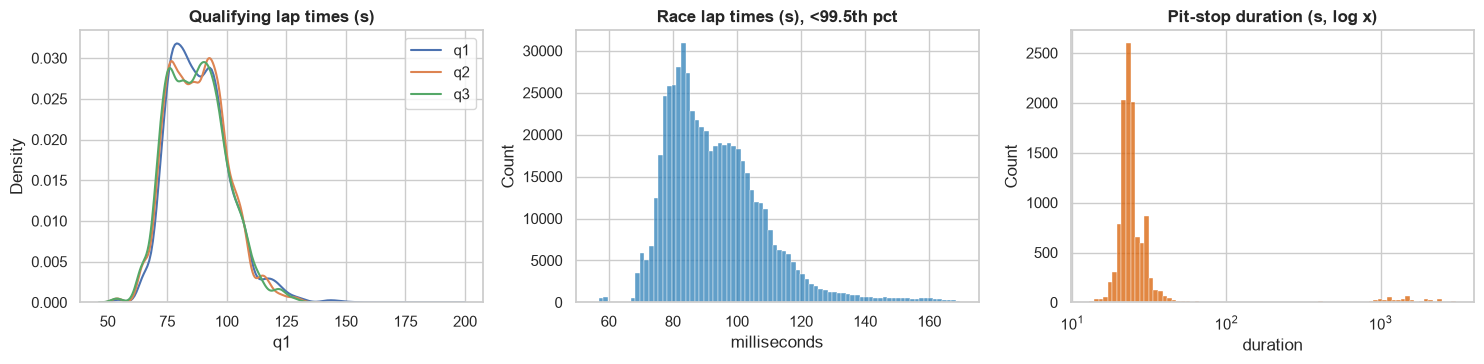

Pit stops longer than 60 s: 517 (4.5%) — raw strings like these needed the m:ss parser: ['16:44.718', '2:03.124', '1:29.401']


In [256]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
q = df["qualifying"]
for s in ["q1", "q2", "q3"]:
    sns.kdeplot(q[s].dropna(), ax=axes[0], label=s, clip=(40, 200))
axes[0].set_title("Qualifying lap times (s)"); axes[0].legend()
lt = df["lap_times"]["milliseconds"] / 1000
sns.histplot(lt[lt < lt.quantile(.995)], bins=80, ax=axes[1], color="#2c7fb8"); axes[1].set_title("Race lap times (s), <99.5th pct")
ps = df["pit_stops"]["duration"].dropna()
sns.histplot(ps, bins=80, log_scale=True, ax=axes[2], color="#d95f02"); axes[2].set_title("Pit-stop duration (s, log x)")
plt.tight_layout(); plt.show()
print(f"Pit stops longer than 60 s: {(ps > 60).sum():,} ({pct((ps > 60).mean())}) — raw strings like these needed the m:ss parser:",
      df['pit_stops'].loc[df['pit_stops']['duration'] > 60, 'duration_raw'].head(3).tolist())

In [257]:
note("1 · Sentinels",
     f"{sent.backslash_N.sum():,} '\\N' cells across {(sent.backslash_N > 0).sum()} columns; grid uses 0 as a second, disguised code; "
     f"long pit stops are written as m:ss.sss strings.",
     "Replace '\\N'/'' with NaN on copies; parse dates and m:ss durations to seconds; treat grid==0 separately (Clue 5).")

> 📝 **Logged (1 · Sentinels)** — 160,076 '\N' cells across 30 columns; grid uses 0 as a second, disguised code; long pit stops are written as m:ss.sss strings.  
> ➜ *Replace '\N'/'' with NaN on copies; parse dates and m:ss durations to seconds; treat grid==0 separately (Clue 5).*

🔎 **Lead:** with real types we can test the joins. The questions in the brief need multi-hop joins — so do the keys hold?

---
## Clue 2 — The paper trail: do the keys hold?

Two checks: every **primary key** is unique and non-null, and every **foreign key** points to a row that exists. We also check *natural keys* — the combinations that should be unique by meaning (e.g. one standings row per driver per race) even when the table has a surrogate id.

In [258]:
PK = {"circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"], "races": ["raceId"],
      "results": ["resultId"], "qualifying": ["qualifyId"], "status": ["statusId"], "seasons": ["year"],
      "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
      "constructor_results": ["constructorResultsId"], "lap_times": ["raceId", "driverId", "lap"],
      "pit_stops": ["raceId", "driverId", "stop"], "sprint_results": ["resultId"]}
NATURAL = {"races": ["year", "round"], "results": ["raceId", "driverId"], "qualifying": ["raceId", "driverId"],
           "driver_standings": ["raceId", "driverId"], "constructor_standings": ["raceId", "constructorId"],
           "constructor_results": ["raceId", "constructorId"], "sprint_results": ["raceId", "driverId"],
           "drivers": ["driverRef"], "constructors": ["constructorRef"], "circuits": ["circuitRef"]}

def key_check(kind, mapping):
    rows = []
    for t, cols in mapping.items():
        if t not in df or not set(cols) <= set(df[t].columns): continue
        d = df[t]
        rows.append({"kind": kind, "table": t, "key": "+".join(cols), "rows": len(d),
                     "null keys": int(d[cols].isna().any(axis=1).sum()),
                     "duplicate keys": int(d.duplicated(cols).sum())})
    return pd.DataFrame(rows)

keys = pd.concat([key_check("primary", PK), key_check("natural", NATURAL)], ignore_index=True)
display(keys.style.map(lambda v: "background-color:#f8d7da" if isinstance(v, (int, np.integer)) and v > 0 else "",
                       subset=["null keys", "duplicate keys"]).hide(axis="index"))

kind,table,key,rows,null keys,duplicate keys
primary,circuits,circuitId,77,0,0
primary,constructors,constructorId,212,0,0
primary,drivers,driverId,861,0,0
primary,races,raceId,1125,0,0
primary,results,resultId,26759,0,0
primary,qualifying,qualifyId,10494,0,0
primary,status,statusId,139,0,0
primary,seasons,year,75,0,0
primary,driver_standings,driverStandingsId,34863,0,0
primary,constructor_standings,constructorStandingsId,13391,0,0


In [259]:
FKS = [("races", "circuitId", "circuits", "circuitId"), ("races", "year", "seasons", "year")]
for child in ["results", "sprint_results", "qualifying"]:
    FKS += [(child, "raceId", "races", "raceId"), (child, "driverId", "drivers", "driverId"),
            (child, "constructorId", "constructors", "constructorId")]
FKS += [("results", "statusId", "status", "statusId"), ("sprint_results", "statusId", "status", "statusId"),
        ("driver_standings", "raceId", "races", "raceId"), ("driver_standings", "driverId", "drivers", "driverId"),
        ("constructor_standings", "raceId", "races", "raceId"), ("constructor_standings", "constructorId", "constructors", "constructorId"),
        ("constructor_results", "raceId", "races", "raceId"), ("constructor_results", "constructorId", "constructors", "constructorId"),
        ("lap_times", "raceId", "races", "raceId"), ("lap_times", "driverId", "drivers", "driverId"),
        ("pit_stops", "raceId", "races", "raceId"), ("pit_stops", "driverId", "drivers", "driverId")]

fk_rows = []
for c, ccol, p, pcol in FKS:
    if c not in df or p not in df: continue
    vals = df[c][ccol]
    orphans = vals.notna() & ~vals.isin(df[p][pcol])
    fk_rows.append({"fk": f"{c}.{ccol} → {p}.{pcol}", "rows": len(vals), "null": int(vals.isna().sum()),
                    "orphans": int(orphans.sum()), "orphan examples": vals[orphans].unique()[:5].tolist()})
fk = pd.DataFrame(fk_rows)
display(fk)
print("All FKs reconcile ✅" if fk.orphans.sum() == 0 else f"⚠️ {fk.orphans.sum():,} orphan references")

,fk,rows,null,orphans,orphan examples
0,races.circuitId → circuits.circuitId,1125,0,0,[]
1,races.year → seasons.year,1125,0,0,[]
2,results.raceId → races.raceId,26759,0,0,[]
3,results.driverId → drivers.driverId,26759,0,0,[]
4,results.constructorId → constructors.constructorId,26759,0,0,[]
5,sprint_results.raceId → races.raceId,360,0,0,[]
6,sprint_results.driverId → drivers.driverId,360,0,0,[]
7,sprint_results.constructorId → constructors.constructorId,360,0,0,[]
8,qualifying.raceId → races.raceId,10494,0,0,[]
9,qualifying.driverId → drivers.driverId,10494,0,0,[]


All FKs reconcile ✅


**Why a second check?** The FK test above only asks "does this `driverId` exist in `drivers`?" and "does this `raceId` exist in `races`?" — *separately*. A row can pass both and still be nonsense, e.g. a qualifying row for (race = Monaco 1998, driver = Hamilton): Hamilton exists, Monaco 1998 exists, but Hamilton didn't race there.

So here we test the **pair**: for each table, take every *(race, driver)* combination it mentions and ask whether `results` has that driver in that race. `not in results = 0` means every qualifying time, lap time, pit stop, standing and sprint belongs to someone who actually entered that race — so joining these tables onto our driver-race rows won't create orphans or phantom drivers.

In [260]:
res_pairs = set(zip(df["results"].raceId, df["results"].driverId))
cross = []
for t in ["qualifying", "lap_times", "pit_stops", "driver_standings", "sprint_results"]:
    pairs = set(zip(df[t].raceId, df[t].driverId))
    cross.append({"table": t, "distinct (race, driver) pairs": len(pairs),
                  "not in results": len(pairs - res_pairs)})
cross = pd.DataFrame(cross)
display(cross)
print("All tables agree with results at the (race, driver) level ✅" if cross["not in results"].sum() == 0
      else "⚠️ some (race, driver) pairs exist only outside results — inspect before joining")

,table,"distinct (race, driver) pairs",not in results
0,qualifying,10494,0
1,lap_times,11041,0
2,pit_stops,5575,0
3,driver_standings,34863,8664
4,sprint_results,360,0


⚠️ some (race, driver) pairs exist only outside results — inspect before joining


In [261]:
nat_dups = keys[(keys.kind == "natural") & (keys["duplicate keys"] > 0)]
note("2 · Keys",
     f"Primary-key problems: {int(keys[keys.kind=='primary'][['null keys','duplicate keys']].values.sum())}; FK orphans: {int(fk.orphans.sum())}. "
     f"Natural-key duplicates in: {', '.join(nat_dups.table + ' (' + nat_dups['duplicate keys'].astype(str) + ')') or 'none'}.",
     "Surrogate keys are trustworthy; the natural grain (raceId, driverId) is NOT unique and must be fixed explicitly (Clue 3).")

> 📝 **Logged (2 · Keys)** — Primary-key problems: 0; FK orphans: 0. Natural-key duplicates in: results (91).  
> ➜ *Surrogate keys are trustworthy; the natural grain (raceId, driverId) is NOT unique and must be fixed explicitly (Clue 3).*

🔎 **Lead:** `results` has a unique `resultId` but **not** a unique `(raceId, driverId)`. Our unit of analysis is exactly that pair. Who are these drivers who appear twice in one race?

---
## Clue 3 — The driver who was in two cars

> **The question:** the brief demands exactly **one row per (raceId, driverId)**, because each row is one prediction. Clue 2 found that `results` breaks this. **This clue builds the rule that turns `results` into that one-row-per-driver-race table** — the backbone (`mt`) every later clue uses.
>
> **Where it ends:** the function `collapse_shared_drives()` at the bottom of this clue. Steps: ① find the duplicates → ② understand why they exist → ③ list candidate rules → ④ measure what each rule does to the podium label → ⑤ choose and apply.

We assemble a readable master view of `results` (race, year, driver, constructor, status) and interrogate the duplicates.

Rows in duplicated (raceId, driverId) groups: 176 | groups: 85 | races affected: 42 | seasons: 1950–1978


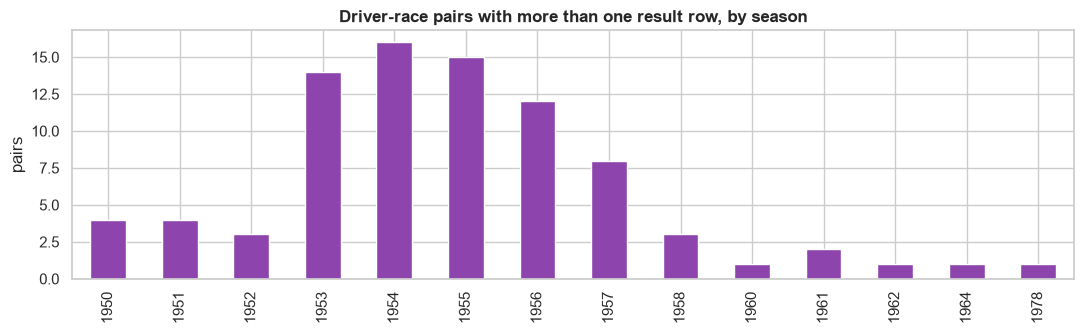

In [262]:
races = df["races"].copy()
drivers = df["drivers"].assign(driver=lambda d: d.forename + " " + d.surname)
constructors = df["constructors"].rename(columns={"name": "constructor", "nationality": "constructor_nat"})
circuits = df["circuits"].rename(columns={"name": "circuit", "country": "circuit_country"})
status = df["status"]

res = (df["results"]
       .merge(races[["raceId", "year", "round", "circuitId", "name", "date"]].rename(columns={"name": "race"}), on="raceId", how="left")
       .merge(drivers[["driverId", "driver", "nationality", "dob"]], on="driverId", how="left")
       .merge(constructors[["constructorId", "constructor"]], on="constructorId", how="left")
       .merge(status, on="statusId", how="left")
       .merge(circuits[["circuitId", "circuit", "circuit_country"]], on="circuitId", how="left"))
assert len(res) == len(df["results"]), "a lookup join multiplied rows"

dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask]
print(f"Rows in duplicated (raceId, driverId) groups: {dup_mask.sum():,} | groups: {dups.groupby(['raceId','driverId']).ngroups:,} "
      f"| races affected: {dups.raceId.nunique()} | seasons: {dups.year.min()}–{dups.year.max()}")

fig, ax = plt.subplots(figsize=(11, 3.5))
dups.drop_duplicates(["raceId", "driverId"]).year.value_counts().sort_index().plot.bar(ax=ax, color="#8e44ad")
ax.set_title("Driver-race pairs with more than one result row, by season"); ax.set_xlabel(""); ax.set_ylabel("pairs")
plt.tight_layout(); plt.show()

In [263]:
# 🗃 First-pass EDA: how many rows per duplicated pair, and are ALL duplicates shared drives from the 1950s?
mult = dups.groupby(["raceId", "driverId"]).size().value_counts().sort_index().rename_axis("rows per pair").rename("pairs")
display(mult.to_frame())
late = dups[dups.year > 1957]
print(f"Duplicated rows after 1957 (outside the shared-drive era): {len(late)}")
if len(late):
    display(late[["year", "race", "driver", "constructor", "number", "grid", "positionOrder", "laps", "status"]])

,pairs
rows per pair,
2,79
3,6


Duplicated rows after 1957 (outside the shared-drive era): 18


,year,race,driver,constructor,number,grid,positionOrder,laps,status
13188,1978,Italian Grand Prix,Harald Ertl,ATS,10.0,0,26,0,Did not qualify
13191,1978,Italian Grand Prix,Harald Ertl,Ensign,23.0,0,29,0,Did not prequalify
17362,1964,United States Grand Prix,Jim Clark,Lotus-Climax,1.0,1,7,102,Out of fuel
17740,1962,British Grand Prix,Keith Greene,Lotus-Climax,48.0,0,22,0,Withdrew
17743,1962,British Grand Prix,Keith Greene,Gilby,50.0,0,25,0,Withdrew
17961,1961,British Grand Prix,Stirling Moss,Ferguson,26.0,20,19,56,Disqualified
17963,1961,British Grand Prix,Stirling Moss,Lotus-Climax,28.0,5,21,44,Brakes
18062,1961,United States Grand Prix,Masten Gregory,Lotus-Climax,22.0,11,17,23,Gearbox
18082,1960,Argentine Grand Prix,Stirling Moss,Cooper-Climax,36.0,1,17,40,Suspension
18509,1958,Monaco Grand Prix,Ron Flockhart,Cooper,22.0,0,17,0,Did not qualify


**What the 18 post-1957 rows are** (9 driver-race pairs, 1958–1978), checked one by one:
* **3 pairs entered two cars and started neither**: Flockhart (Monaco 1958, DNQ twice), Greene (British GP 1962, withdrew twice), Ertl (Italy 1978, DNQ + DNPQ). The non-starter filter removes them anyway.
* **6 pairs are genuine mid-race car swaps**, still allowed until the mid-1960s: Brooks (France 1958), Shelby (Italy 1958), Moss (Argentina 1960, Britain 1961), Gregory (USA 1961), Clark (USA 1964). Same phenomenon as the 1950s shared drives, so the same rule applies.

No data-entry quirks, and none of these seasons is in the window the model trains on (1994+): they matter only for the EDA and the DE questions.

In [264]:
# Look at the worst race in detail: same driver, different car number / constructor / grid.
worst = dups.raceId.value_counts().index[0] if len(dups) else None
if worst is not None:
    cols = ["year", "race", "driver", "constructor", "number", "grid", "positionOrder", "positionText", "points", "laps", "status"]
    display(res[(res.raceId == worst) & dup_mask].sort_values(["driver", "positionOrder"])[cols])

,year,race,driver,constructor,number,grid,positionOrder,positionText,points,laps,status
20219,1954,Indianapolis 500,Andy Linden,Kurtis Kraft,45.0,27,11,11,0.0,200,Finished
20231,1954,Indianapolis 500,Andy Linden,Nichels,43.0,4,24,R,0.0,165,Retired
19255,1954,Indianapolis 500,Andy Linden,Schroeder,74.0,23,25,R,0.0,165,Suspension
20225,1954,Indianapolis 500,Bob Scott,Stevens,27.0,31,18,18,0.0,193,+7 Laps
20233,1954,Indianapolis 500,Bob Scott,Schroeder,74.0,23,25,R,0.0,165,Suspension
20215,1954,Indianapolis 500,Duane Carter,Kurtis Kraft,34.0,11,4,4,1.5,200,Finished
19245,1954,Indianapolis 500,Duane Carter,Kurtis Kraft,16.0,8,15,15,0.0,196,+4 Laps
20226,1954,Indianapolis 500,George Fonder,Kurtis Kraft,71.0,33,19,19,0.0,193,+7 Laps
20236,1954,Indianapolis 500,George Fonder,Schroeder,33.0,26,31,R,0.0,101,Brakes
20216,1954,Indianapolis 500,Jerry Hoyt,Kurtis Kraft,5.0,32,8,8,0.0,200,Finished


**Reading the evidence.** Each duplicate row is a *car* the driver drove: one started from the grid; the other was taken over mid-race (often recognisable by `grid` = 0, or by the same car `number` appearing for two drivers). Points were split between drivers who shared a car.

So `results` is really at **(race, car, driver-stint)** grain, not (race, driver). We need a rule. Candidate rules, and what each does to the **target label**:

| Rule | Keeps | Pro | Con |
|---|---|---|---|
| A. best `positionOrder` | the best-placed car | label = "was credited with a podium" | picks the row using the outcome |
| B. started car (`grid` > 0; tie → most laps, then lowest `resultId`) | the car they started in | features describe the pre-race situation | may miss a podium earned in the taken-over car |
| C. first `resultId` | first listed | trivial | arbitrary |
| D. most `laps` 🗃 | the car driven longest | "principal" race of the driver | uses a post-race column to pick the row |

Let's measure how often they disagree instead of arguing in the abstract.

In [265]:
if len(dups):
    key = ["raceId", "driverId"]
    d = dups.assign(started=dups.grid.fillna(0) > 0)
    A = d.sort_values("positionOrder").drop_duplicates(key).set_index(key)
    B = d.sort_values(["started", "laps", "resultId"], ascending=[False, False, True]).drop_duplicates(key).set_index(key)
    Cr = d.sort_values("resultId").drop_duplicates(key).set_index(key)
    Dm = d.sort_values(["laps", "resultId"], ascending=[False, True]).drop_duplicates(key).set_index(key)
    any_podium = d.groupby(key).positionOrder.min().le(3)
    rule_cmp = pd.DataFrame({
        "podium labels": [int((X.positionOrder <= 3).sum()) for X in (A, B, Cr, Dm)],
        "disagree with 'credited podium'": [int(((X.positionOrder <= 3) != any_podium.reindex(X.index)).sum()) for X in (A, B, Cr, Dm)],
        "kept row has grid > 0": [int((X.grid.fillna(0) > 0).sum()) for X in (A, B, Cr, Dm)],
    }, index=["A · best positionOrder", "B · started car (tie → most laps)", "C · first resultId", "D · most laps"])
    rule_cmp["groups"] = len(any_podium)
    display(rule_cmp)
    started_counts = d.groupby(key).started.sum().value_counts().sort_index()
    print("Number of rows with grid > 0 per duplicated pair:", started_counts.to_dict(),
          "→ if many pairs have 2+, the tie-break inside rule B (most laps) is doing real work; say so in the report.")

,podium labels,disagree with 'credited podium',kept row has grid > 0,groups
A · best positionOrder,22,0,82,85
B · started car (tie → most laps),22,0,82,85
C · first resultId,6,16,82,85
D · most laps,22,0,82,85


Number of rows with grid > 0 per duplicated pair: {0: 3, 2: 76, 3: 6} → if many pairs have 2+, the tie-break inside rule B (most laps) is doing real work; say so in the report.


### ✅ The solution (step ⑤)
**Decision (hybrid):** keep **one row per (raceId, driverId)** whose *features* come from the car the driver **started in** (rule B — that is the pre-race situation we would actually observe), and define the *target* as **"credited with a podium in any of their cars"** (`min(positionOrder) <= 3`, rule A's label). This keeps the features honest and the label faithful to the official record. We also keep `n_result_rows` as an audit column.

If your team prefers a single-row rule, B is the most defensible for a pre-race model; quote the disagreement count from the table above as its cost.

**Limitation of "started car".** A car taken over mid-race keeps the grid slot of the driver who started it, so in most pairs *every* row has `grid` > 0 (see the printout above) and the tie-break (most laps, a post-race column) picks the row. Example: Moss, Argentina 1960, started from pole in car #36, retired, then took over car #38 (grid 8) and finished 3rd. The kept row is #38, so his features say grid 8. The **label** is unaffected (podium in any car), and all such rows are from 1950–64, outside the training window, so we document this rather than engineer around it.

In [266]:
def collapse_shared_drives(r):
    # One row per (raceId, driverId): features from the started car, label from the best car.
    key = ["raceId", "driverId"]
    r = r.assign(started=r.grid.fillna(0) > 0)
    agg = r.groupby(key).agg(n_result_rows=("resultId", "size"),
                             best_positionOrder=("positionOrder", "min"),
                             total_points=("points", "sum"))
    primary = r.sort_values(["started", "laps", "resultId"], ascending=[False, False, True]).drop_duplicates(key)
    out = primary.merge(agg, on=key, how="left", validate="1:1")
    out["podium"] = (out.best_positionOrder <= 3).astype(int)
    return out

mt = collapse_shared_drives(res)
assert not mt.duplicated(["raceId", "driverId"]).any()
print(f"results rows: {len(res):,} → driver-race rows: {len(mt):,} (removed {len(res) - len(mt):,})")
note("3 · Grain",
     f"{dup_mask.sum():,} results rows sit in {dups.groupby(['raceId','driverId']).ngroups if len(dups) else 0} duplicated (raceId, driverId) groups, "
     f"{(dups.year <= 1957).sum()} of the rows fall in 1950–57 (shared drives), {(dups.year > 1957).sum()} later (1958–78: 3 double non-starts + 6 car swaps, inspected individually).",
     "Collapse to one row per pair: features from the started car (grid>0; tie → most laps, then lowest resultId), target = podium in any car; keep n_result_rows.")

results rows: 26,759 → driver-race rows: 26,668 (removed 91)


> 📝 **Logged (3 · Grain)** — 176 results rows sit in 85 duplicated (raceId, driverId) groups, 158 of the rows fall in 1950–57 (shared drives), 18 later (inspect individually).  
> ➜ *Collapse to one row per pair: features from the started car (grid>0; tie → most laps, then lowest resultId), target = podium in any car; keep n_result_rows.*

🔎 **Lead:** if shared drives create extra rows, they might also create *extra podium rows*. Does every race have exactly three podium finishers?

---
## Clue 4 — Counting the podium

Three sanity checks on the target: (1) is `positionOrder` a clean ranking inside each race, (2) does each race have exactly 3 podium drivers, (3) how does the base rate move over time and why?

In [267]:
po_dup = res.duplicated(["raceId", "positionOrder"]).sum()
print(f"Duplicate positionOrder values inside a race: {po_dup}")
gaps = res.groupby("raceId").positionOrder.agg(lambda s: s.max() - s.nunique())
print(f"Races where positionOrder skips numbers: {(gaps > 0).sum()}")

pod_rows = res[res.positionOrder <= 3].groupby("raceId").size()
pod_drivers = mt.groupby("raceId").podium.sum()
check = pd.DataFrame({"podium rows (raw)": pod_rows, "podium drivers (deduped)": pod_drivers}).fillna(0).astype(int)
odd = check[(check["podium rows (raw)"] != 3) | (check["podium drivers (deduped)"] != 3)]
print(f"Races where the podium count is not 3: {len(odd)}")
display(odd.join(races.set_index("raceId")[["year", "name"]]).head(15))

Duplicate positionOrder values inside a race: 123
Races where positionOrder skips numbers: 0
Races where the podium count is not 3: 18


,podium rows (raw),podium drivers (deduped),year,name
raceId,,,,
746,4,4,1960,Argentine Grand Prix
780,4,4,1957,British Grand Prix
784,4,4,1956,Argentine Grand Prix
785,4,4,1956,Monaco Grand Prix
787,4,4,1956,Belgian Grand Prix
789,4,4,1956,British Grand Prix
791,4,4,1956,Italian Grand Prix
792,7,5,1955,Argentine Grand Prix
793,4,4,1955,Monaco Grand Prix


A race can legitimately have **more than 3 podium drivers** (two drivers credited for one shared car) and the deduped count can be **fewer than 3** if one podium belongs to a dropped row only (shouldn't happen with our rule — if it does, investigate). Now the base rate:

C:\Users\ahmed\AppData\Local\Temp\ipykernel_19316\131424391.py:23: UserWarning: Glyph 9312 (\N{CIRCLED DIGIT ONE}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\ahmed\AppData\Local\Temp\ipykernel_19316\131424391.py:23: UserWarning: Glyph 9313 (\N{CIRCLED DIGIT TWO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
c:\Users\ahmed\OneDrive\Desktop\Uni\Semester 9\ACL\project\AI-Tools-Lab-F1-Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9312 (\N{CIRCLED DIGIT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\ahmed\OneDrive\Desktop\Uni\Semester 9\ACL\project\AI-Tools-Lab-F1-Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9313 (\N{CIRCLED DIGIT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


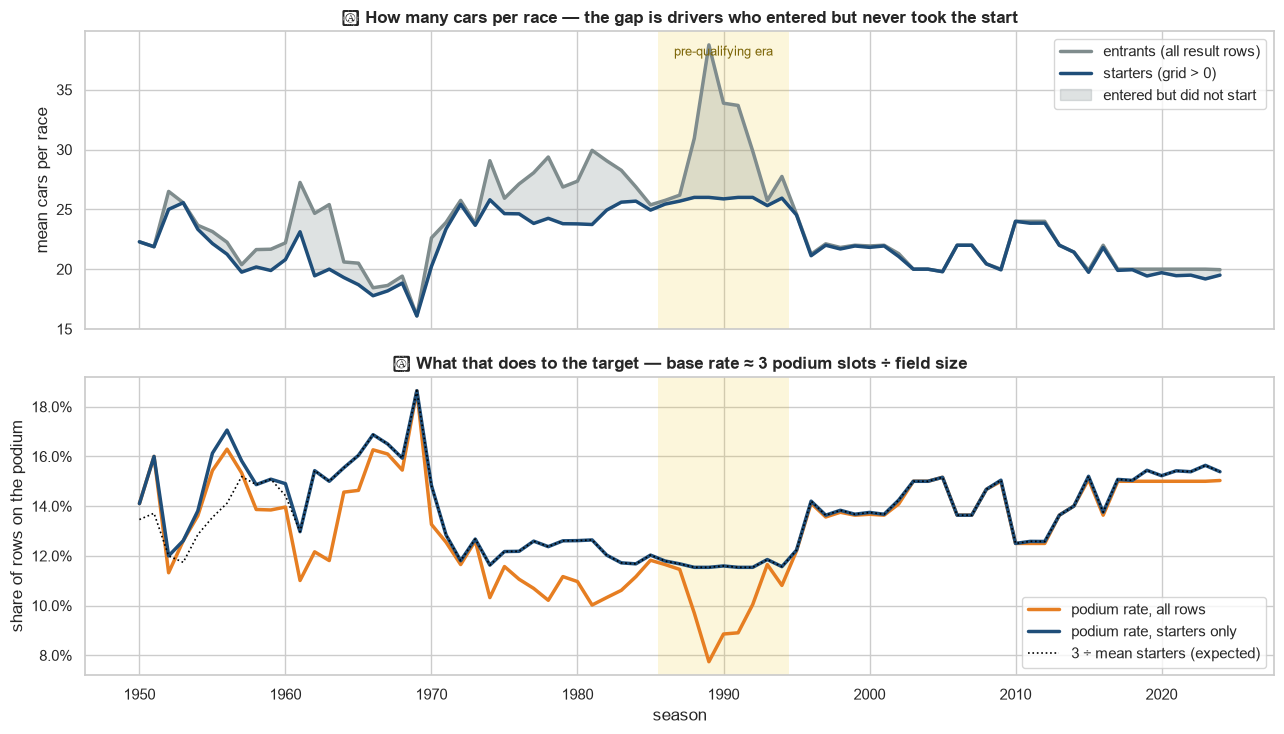

Overall podium rate: all rows 12.7%, starters only 13.6%


In [268]:
per_race = mt.groupby("raceId").agg(year=("year", "first"), race=("race", "first"),
                                    entrants=("driverId", "size"), starters=("started", "sum"), podiums=("podium", "sum"))
per_year = per_race.groupby("year")[["entrants", "starters"]].mean()
per_year["podium rate (all rows)"] = mt.groupby("year").podium.mean()
per_year["podium rate (starters)"] = mt[mt.started].groupby("year").podium.mean()

per_year["expected 3 / starters"] = 3 / per_year["starters"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
for ax in (ax1, ax2):  # shade the pre-qualifying era where many entrants never started
    ax.axvspan(1985.5, 1994.5, color="#f1c40f", alpha=.15, lw=0)
ax1.plot(per_year.index, per_year.entrants, color="#7f8c8d", lw=2.5, label="entrants (all result rows)")
ax1.plot(per_year.index, per_year.starters, color="#1f4e79", lw=2.5, label="starters (grid > 0)")
ax1.fill_between(per_year.index, per_year.starters, per_year.entrants, color="#7f8c8d", alpha=.25, label="entered but did not start")
ax1.set_ylabel("mean cars per race"); ax1.legend(loc="upper right", frameon=True)
ax1.set_title("① How many cars per race — the gap is drivers who entered but never took the start")
ax1.text(1990, ax1.get_ylim()[1] * .97, "pre-qualifying era", ha="center", va="top", fontsize=9, color="#7d6608")
ax2.plot(per_year.index, per_year["podium rate (all rows)"], color="#e67e22", lw=2.5, label="podium rate, all rows")
ax2.plot(per_year.index, per_year["podium rate (starters)"], color="#1f4e79", lw=2.5, label="podium rate, starters only")
ax2.plot(per_year.index, per_year["expected 3 / starters"], color="black", lw=1.2, ls=":", label="3 ÷ mean starters (expected)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax2.set_ylabel("share of rows on the podium")
ax2.set_title("② What that does to the target — base rate ≈ 3 podium slots ÷ field size")
ax2.legend(loc="lower right", frameon=True); ax2.set_xlabel("season")
plt.tight_layout(); plt.show()
print(f"Overall podium rate: all rows {pct(mt.podium.mean())}, starters only {pct(mt[mt.started].podium.mean())}")

**How to read this chart**

* **Panel ① (cars per race).** Grey = everyone with a row in `results`; dark blue = drivers who actually started (`grid > 0`). The shaded grey band between them is drivers who *entered* but never started (did not qualify / pre-qualify, withdrew). It is widest in the **yellow-shaded late-1980s/early-1990s**, when far more cars turned up than the grid could hold.
* **Panel ② (podium base rate).** There are always ~3 podium places, so the share of rows that are podiums is roughly **3 ÷ field size** (black dotted line). Orange (all rows) dips exactly where panel ① shows lots of non-starters, because those rows can never be podiums. Dark blue (starters only) stays close to the expected line.
* **Takeaway.** Most of the drift in the target over time is a **population effect** (who has a row), not a change in how racing works. This is why Clue 5 restricts the modeling table to starters, and why the base rate must be reported per split.

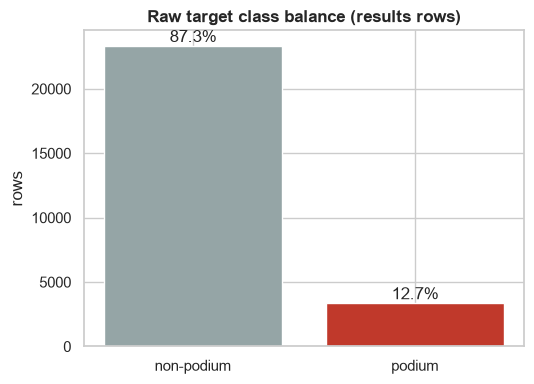

In [269]:
# 🗃 First-pass EDA: the raw class balance in one picture (before any cleaning).
raw_pod = (pd.to_numeric(raw["results"]["positionOrder"]) <= 3)
fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(["non-podium", "podium"], raw_pod.value_counts().reindex([False, True]).values, color=["#95a5a6", "#c0392b"])
for b, v in zip(bars, raw_pod.value_counts(normalize=True).reindex([False, True]).values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), pct(v), ha="center", va="bottom")
ax.set_title("Raw target class balance (results rows)"); ax.set_ylabel("rows")
plt.tight_layout(); plt.show()

The gap between *entrants* and *starters* in the late 1980s–early 1990s is the pre-qualifying era: many rows never had a chance. And one race per season in 1950–1960 looks nothing like the others…

In [270]:
is_indy = mt.race.str.contains("Indianapolis 500", case=False, na=False)
indy_drivers = set(mt.loc[is_indy, "driverId"])
other_drivers = set(mt.loc[~is_indy, "driverId"])
only_indy = indy_drivers - other_drivers
print(f"Indianapolis 500 rows: {is_indy.sum():,} in {mt.loc[is_indy, 'raceId'].nunique()} races "
      f"({mt.loc[is_indy, 'year'].min()}–{mt.loc[is_indy, 'year'].max()})")
print(f"Drivers who raced at Indy: {len(indy_drivers)}; of them never raced any other championship round: {len(only_indy)} "
      f"({pct(len(only_indy) / max(len(indy_drivers), 1))})")
print("Note: the Indianapolis *circuit* also hosted the US GP (2000s) — filter by race NAME, not circuitId.")
display(mt[mt.year <= 1960].assign(indy=is_indy).groupby("indy").agg(rows=("podium", "size"), mean_field=("raceId", lambda s: s.value_counts().mean()),
                                                                      share_US_drivers=("nationality", lambda s: (s == "American").mean())))

Indianapolis 500 rows: 381 in 11 races (1950–1960)
Drivers who raced at Indy: 107; of them never raced any other championship round: 103 (96.3%)
Note: the Indianapolis *circuit* also hosted the US GP (2000s) — filter by race NAME, not circuitId.


,rows,mean_field,share_US_drivers
indy,,,
False,1763,21.240964,0.089053
True,381,34.636364,0.997375


In [271]:
note("4 · Target",
     f"Podium base rate is {pct(mt.podium.mean())} of driver-race rows overall but moves with field size (≈3/entrants); "
     f"{len(odd)} races don't have exactly 3 podium rows/drivers; the Indy 500 (1950–60) is a separate field "
     f"({pct(len(only_indy) / max(len(indy_drivers), 1))} of its drivers never raced elsewhere).",
     "Target = credited podium (deduped). Exclude Indianapolis 500 races by name. Report base rate per split; prefer PR-AUC as a rare-class metric.")

> 📝 **Logged (4 · Target)** — Podium base rate is 12.7% of driver-race rows overall but moves with field size (≈3/entrants); 18 races don't have exactly 3 podium rows/drivers; the Indy 500 (1950–60) is a separate field (96.3% of its drivers never raced elsewhere).  
> ➜ *Target = credited podium (deduped). Exclude Indianapolis 500 races by name. Report base rate per split; prefer PR-AUC as a rare-class metric.*

🔎 **Lead:** "entrants" and "starters" are not the same population. Rows with `grid = 0` include people who never took the start. Who exactly are they?

---
## Clue 5 — Entered, but never started

To separate them we need the `status` column grouped into meaning. We build the mapping once here (it's reused for retirements in Clue 10), keeping an explicit **ambiguous** bucket instead of hiding judgement calls.

In [272]:
FINISH_RE = re.compile(r"^(Finished|\+\s?\d+\s+Laps?|Lapped)$", re.I)
NON_START = {"did not qualify", "did not prequalify", "withdrew", "107% rule", "did not start", "not restarted",
             "excluded from qualifying", "driver unwell"}  # unwell before the start -> no start
DSQ = {"disqualified", "excluded", "underweight"}   # underweight = regulation decision, not a failure
ACCIDENT_RE = re.compile(r"accident|collision|spun|crash|fatal|injur|injury|illness|physical|eye injury|driver|safety concerns", re.I)
AMBIGUOUS = {"tyre", "puncture", "retired", "damage", "fuel", "out of fuel", "wing", "front wing", "rear wing",
             "stalled", "not classified", "debris", "seat", "safety belt", "refuelling",
             "broken wing", "tyre puncture", "fire", "safety"}   # last four: reviewed from the "other" bucket (could be contact or failure)
MECH_RE = re.compile(r"engine|gearbox|transmission|clutch|hydraulic|electric|electronic|suspension|brake|differential|"
                     r"overheat|mechanical|wheel|fuel (system|pressure|pump|leak|rig|pipe)|undertray|launch control|injection|oil|water|power unit|\bers\b|"
                     r"turbo|exhaust|driveshaft|halfshaft|throttle|steering|battery|radiator|spark|ignition|vibration|"
                     r"pneumatic|cooling|power loss|alternator|distributor|magneto|axle|chassis|crankshaft|cv joint|"
                     r"supercharger|track rod|heat shield|technical|drivetrain|gear|handling|valve|piston|pump|"
                     r"camshaft|fan|cooling system|kers|energy store", re.I)

def classify_status(s):
    if pd.isna(s): return "unknown"
    t = s.strip()
    tl = t.lower()
    if FINISH_RE.match(t): return "finished"
    if tl in NON_START: return "non_start"
    if tl in DSQ: return "disqualified"
    if tl in AMBIGUOUS: return "ambiguous"
    if ACCIDENT_RE.search(t): return "accident_driver"
    if MECH_RE.search(t): return "mechanical"
    return "other"

status_map = status.assign(status_cat=status.status.map(classify_status))
counts = res.status.value_counts()
status_map["results_rows"] = status_map.status.map(counts).fillna(0).astype(int)
display(status_map.groupby("status_cat").agg(statuses=("status", "size"), rows=("results_rows", "sum")).sort_values("rows", ascending=False))
for cat in ["ambiguous", "other"]:
    s = status_map[status_map.status_cat == cat].sort_values("results_rows", ascending=False)
    print(f"\n[{cat}] — review these by hand:", ", ".join(f"{a} ({b})" for a, b in zip(s.status, s.results_rows)))
status_map.to_csv(OUT / "status_mapping.csv", index=False)
mt = mt.merge(status_map[["statusId", "status_cat"]], on="statusId", how="left")

,statuses,rows
status_cat,,
finished,34,15161
mechanical,63,6459
accident_driver,12,2832
non_start,6,1624
ambiguous,16,504
disqualified,2,155
other,6,24



[ambiguous] — review these by hand: Not classified (172), Retired (107), Out of fuel (100), Tyre (55), Puncture (41), Rear wing (10), Front wing (5), Fuel (4), Damage (2), Stalled (2), Refuelling (1), Launch control (1), Underweight (1), Safety belt (1), Seat (1), Debris (1)

[other] — review these by hand: Broken wing (11), Undertray (4), Fuel pipe (3), Fire (3), Safety (2), Tyre puncture (1)


Every status that falls in `ambiguous`/`other` is listed above. **Review decisions** (the `other` bucket is now empty on purpose):
* → **mechanical**: *Fuel pipe*, *Undertray* (4 cases, all 2022–24: floor failures in the ground-effect era), *Launch control* (electronics). Each is a component failing.
* → **disqualified**: *Underweight*, a regulation decision, which the brief excludes from mechanical.
* → **ambiguous**: *Broken wing*, *Tyre puncture*, *Fire*, *Safety*. Each can be a failure or the result of contact, same as *Front/Rear wing* and *Puncture*.
* **Kept ambiguous**: *Retired* (no cause recorded; 50 cases in 2014–24), *Not classified* (running at the end but too few laps), *Out of fuel* (usually a team miscalculation, not a component), *Tyre*, *Stalled*. These can't be settled from the data, which is why DE-Q3 has a sensitivity check that counts them as mechanical.

The mapping is saved to `outputs/status_mapping.csv` for the report.

grid0,grid = 0,grid > 0,All
status_cat,,,
accident_driver,37,2781,2818
ambiguous,4,498,502
disqualified,12,143,155
finished,56,15096,15152
mechanical,18,6378,6396
non_start,1507,114,1621
other,1,23,24
All,1635,25033,26668


grid=0 rows: 1,635 | of these, status says non-start: 1,507 | raced at least one lap (pit-lane or late start): 72 | podium rate of those: 0.0%


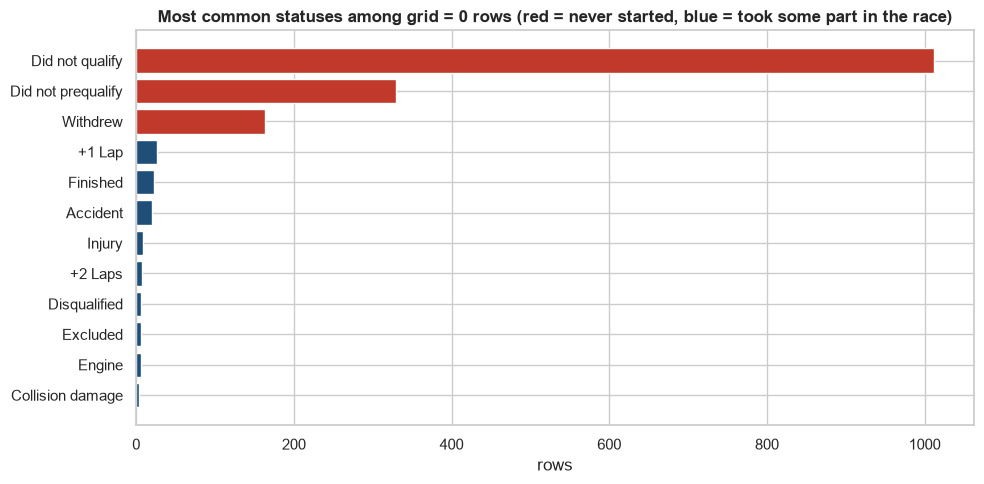

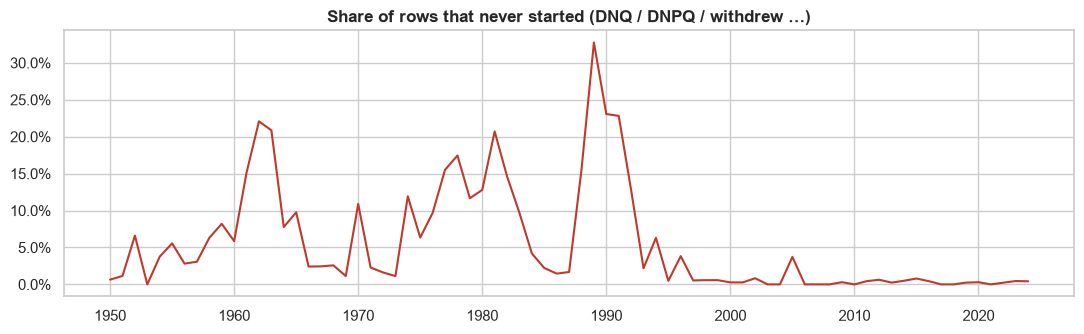

In [273]:
mt["grid0"] = mt.grid.fillna(0) == 0
has_q = set(zip(df["qualifying"].raceId, df["qualifying"].driverId))
mt["has_quali"] = [p in has_q for p in zip(mt.raceId, mt.driverId)]

ct = pd.crosstab(mt.status_cat, mt.grid0.map({True: "grid = 0", False: "grid > 0"}), margins=True)
display(ct)

g0 = mt[mt.grid0]
pit_lane_like = g0[(g0.status_cat != "non_start") & (g0.laps.fillna(0) > 0)]
print(f"grid=0 rows: {len(g0):,} | of these, status says non-start: {(g0.status_cat == 'non_start').sum():,} "
      f"| raced at least one lap (pit-lane or late start): {len(pit_lane_like):,} | podium rate of those: {pct(pit_lane_like.podium.mean()) if len(pit_lane_like) else 'n/a'}")

# 🗃 First-pass EDA: what grid = 0 actually is, status by status
top_g0 = g0.status.value_counts().head(12).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_g0.index, top_g0.values, color=["#c0392b" if classify_status(s) == "non_start" else "#1f4e79" for s in top_g0.index])
ax.set_title("Most common statuses among grid = 0 rows (red = never started, blue = took some part in the race)"); ax.set_xlabel("rows")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5))
mt.assign(non_start=mt.status_cat == "non_start").groupby("year").non_start.mean().plot(ax=ax, color="#c0392b")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title("Share of rows that never started (DNQ / DNPQ / withdrew …)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

`grid = 0` mixes **two populations**: non-starters (DNQ, DNPQ, withdrew) — who by definition can never podium and would inflate the negative class with "free" easy examples — and **genuine pit-lane starters**, who are real race participants.

> ⚠️ Using `status` or `laps` to *define the population* is not feature leakage (they never enter X), but be honest about it: in production you'd know who is on the starting list. Non-qualification is known before the race; DNS-on-the-formation-lap is not, and the status mapping can't always tell them apart.

In [274]:
mt["in_population"] = (mt.status_cat != "non_start") & ~mt.race.str.contains("Indianapolis 500", case=False, na=False)
mt["grid_clean"] = mt.grid.where(mt.grid > 0)          # NaN = pit-lane start
mt["pit_lane_start"] = (mt.grid0 & mt.in_population).astype(int)
note("5 · Population",
     f"{(mt.status_cat == 'non_start').sum():,} rows never started (concentrated in the pre-qualifying era); grid=0 also contains "
     f"{len(pit_lane_like):,} genuine pit-lane/late starters.",
     "Modeling rows = starters only (status not in non_start) and not Indy 500. Encode grid=0 for starters as pit_lane_start=1 with grid set to back of field, not 0.")

> 📝 **Logged (5 · Population)** — 1,621 rows never started (concentrated in the pre-qualifying era); grid=0 also contains 72 genuine pit-lane/late starters.  
> ➜ *Modeling rows = starters only (status not in non_start) and not Indy 500. Encode grid=0 for starters as pit_lane_start=1 with grid set to back of field, not 0.*

🔎 **Lead:** the grid comes from qualifying, adjusted by penalties. Clue 0 showed qualifying data starts late. How late, how complete, and how often does grid ≠ qualifying?

---
## Clue 6 — Qualifying ≠ grid (and qualifying ≠ always there)

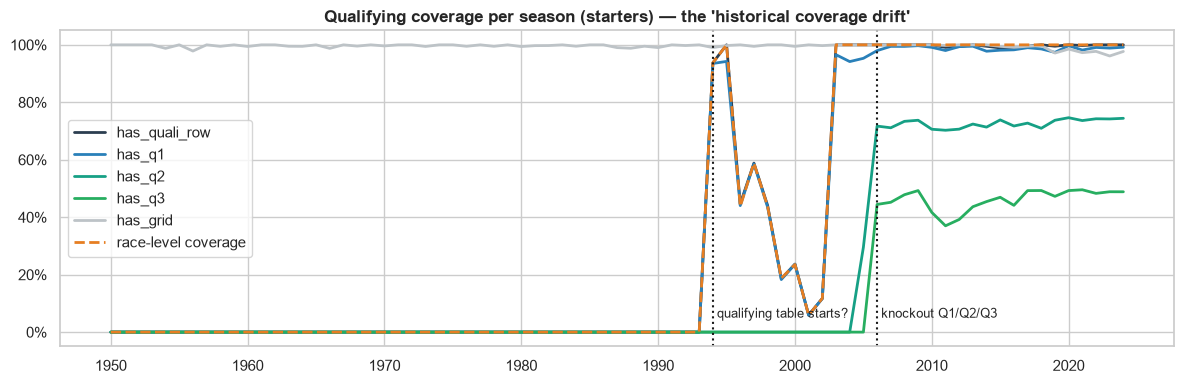

First season with >50% qualifying coverage: 1994


In [275]:
qcols = df["qualifying"][["raceId", "driverId", "position", "q1", "q2", "q3"]].rename(columns={"position": "quali_pos"})
qcols = qcols.drop_duplicates(["raceId", "driverId"])
mt = mt.drop(columns=[c for c in ["quali_pos", "q1", "q2", "q3"] if c in mt.columns]).merge(qcols, on=["raceId", "driverId"], how="left")
pop = mt[mt.in_population]

race_level = (df["qualifying"].merge(races[["raceId", "year"]], on="raceId").groupby("year").raceId.nunique()
              / races[races.raceId.isin(df["results"].raceId)].groupby("year").raceId.nunique()).rename("race-level coverage")
cov = pop.groupby("year").agg(has_quali_row=("quali_pos", lambda s: s.notna().mean()),
                              has_q1=("q1", lambda s: s.notna().mean()),
                              has_q2=("q2", lambda s: s.notna().mean()),
                              has_q3=("q3", lambda s: s.notna().mean()),
                              has_grid=("grid_clean", lambda s: s.notna().mean()))
fig, ax = plt.subplots(figsize=(12, 4))
cov = cov.join(race_level).fillna({"race-level coverage": 0})
cov.plot(ax=ax, color=["#2c3e50", "#2980b9", "#16a085", "#27ae60", "#bdc3c7", "#e67e22"], lw=2,
         style=["-", "-", "-", "-", "-", "--"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlabel("")
ax.set_title("Qualifying coverage per season (starters) — the 'historical coverage drift'")
for y, lab in [(1994, "qualifying table starts?"), (2006, "knockout Q1/Q2/Q3")]:
    if cov.index.min() <= y <= cov.index.max(): ax.axvline(y, ls=":", c="k"); ax.text(y + .3, .05, lab, fontsize=9)
plt.tight_layout(); plt.show()
first_q = cov.index[cov.has_quali_row > .5].min()
print(f"First season with >50% qualifying coverage: {first_q}")

🗃 **A trap from the first-pass EDA.** It is tempting to read "Q2/Q3 are 100% missing before 2006" as "F1 had one qualifying session". The data only say that **older formats are stored in `q1`**; `q1/q2/q3` become meaningful with the 2006 knockout format. After 2006, Q2/Q3 missingness is **structural and informative**: a driver knocked out in Q1 never sets a Q2 time. So instead of imputing those times, encode *how far the driver got*.

In [276]:
# 🗃 'Session reached' (knockout era only): missing Q2/Q3 as information, not noise
ko = pop[(pop.year >= 2006) & pop.quali_pos.notna()].copy()
ko["session_reached"] = np.select([ko.q3.notna(), ko.q2.notna()], ["Q3", "Q2"], "Q1 only")
sr_tab = ko.groupby("session_reached").agg(rows=("podium", "size"), podium_rate=("podium", "mean")).reindex(["Q3", "Q2", "Q1 only"])
display(sr_tab.style.format({"podium_rate": "{:.1%}", "rows": "{:,}"}))

,rows,podium_rate
session_reached,,
Q3,"3,624",29.5%
Q2,"2,103",1.7%
Q1 only,"2,143",0.9%


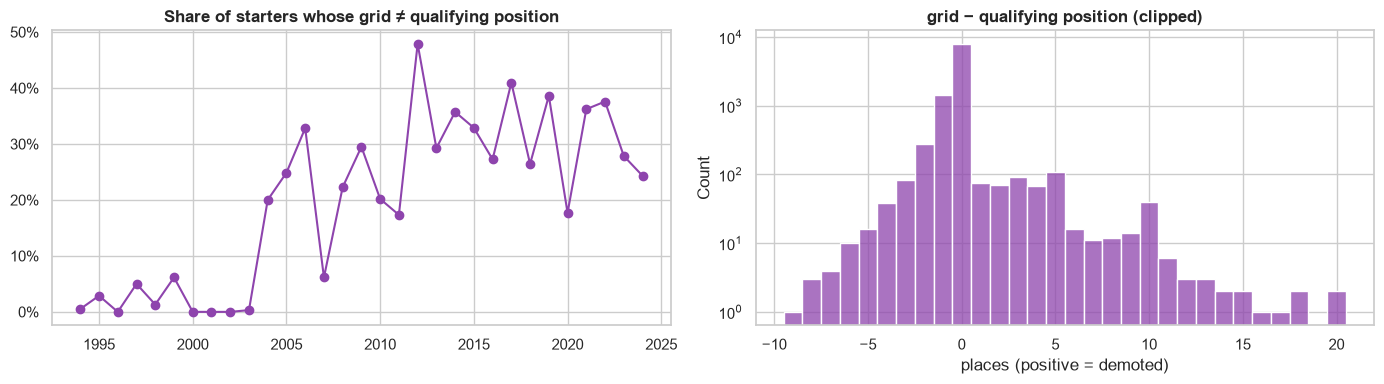

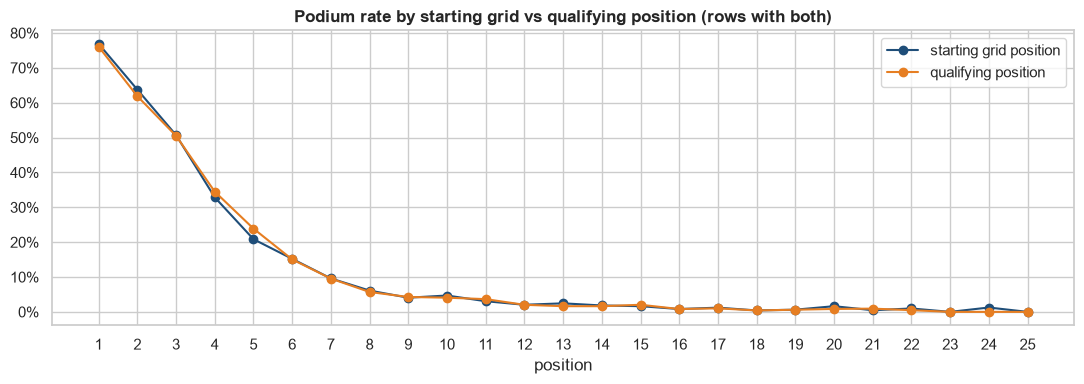

Starters with quali data: 10,454; grid differs: 23.9%; pit-lane starters among them: 78


In [277]:
both = pop[pop.quali_pos.notna()].copy()
both["grid_minus_quali"] = both.grid_clean - both.quali_pos
diff_rate = both.groupby("year").apply(lambda d: (d.grid_minus_quali.fillna(99) != 0).mean())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
diff_rate.plot(ax=axes[0], marker="o", color="#8e44ad")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].set_title("Share of starters whose grid ≠ qualifying position"); axes[0].set_xlabel("")
sns.histplot(both.grid_minus_quali.dropna().clip(-10, 20), bins=31, discrete=True, ax=axes[1], color="#8e44ad")
axes[1].set_yscale("log"); axes[1].set_title("grid − qualifying position (clipped)"); axes[1].set_xlabel("places (positive = demoted)")
plt.tight_layout(); plt.show()
# 🗃 First-pass EDA: same rows, podium rate by grid vs by qualifying position
pe = pd.concat([both[both.grid_clean.between(1, 25)].groupby("grid_clean").podium.mean().rename("starting grid position"),
                both[both.quali_pos.between(1, 25)].groupby("quali_pos").podium.mean().rename("qualifying position")], axis=1)
fig, ax = plt.subplots(figsize=(11, 4))
pe.plot(ax=ax, marker="o", color=["#1f4e79", "#e67e22"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xticks(range(1, 26)); ax.set_xlabel("position")
ax.set_title("Podium rate by starting grid vs qualifying position (rows with both)")
plt.tight_layout(); plt.show()
print(f"Starters with quali data: {len(both):,}; grid differs: {pct((both.grid_minus_quali.fillna(99) != 0).mean())}; "
      f"pit-lane starters among them: {both.grid_clean.isna().sum():,}")

Penalties mostly push drivers **back** (positive differences); small negative differences are drivers *promoted* when someone ahead is penalised. This is why DE-Q1 must say "front-row *start*" (grid 1–2) vs "front-row *qualifier*" (quali 1–2) explicitly.

Lap times also need care: `q3` exists only for the top-10, so "best lap" mixes sessions. A comparable pace signal is the **gap to the fastest time in the same session** — let's see whether it carries signal beyond the position.

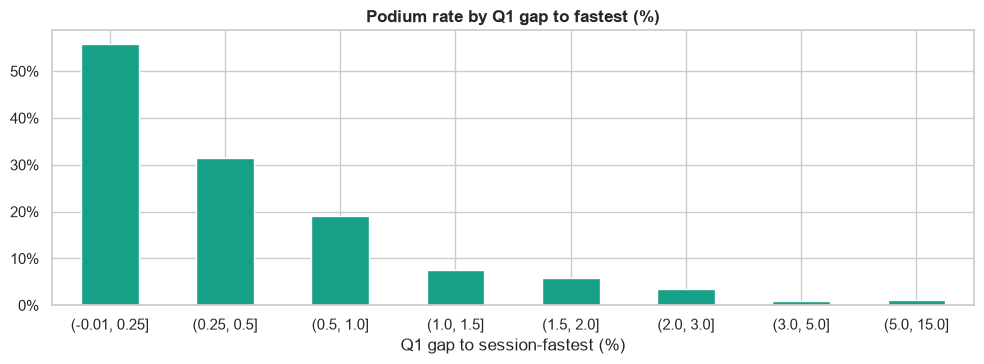

AUC quali position (lower=better): 0.912 | AUC Q1 gap %: 0.827 | AUC best-session gap %: 0.888


In [278]:
qq = both[["raceId", "driverId", "q1", "q2", "q3", "quali_pos", "podium", "year"]].copy()
qq["best_q"] = qq[["q1", "q2", "q3"]].min(axis=1)
qq["q1_gap_pct"] = 100 * (qq.q1 / qq.groupby("raceId").q1.transform("min") - 1)
qq["best_gap_pct"] = 100 * (qq.best_q / qq.groupby("raceId").best_q.transform("min") - 1)
qq = qq[qq.q1_gap_pct.between(0, 15)]  # drop absurd gaps (wet sessions, timing glitches) for the plot
qq["gap_bin"] = pd.cut(qq.q1_gap_pct, [-.01, .25, .5, 1, 1.5, 2, 3, 5, 15])
fig, ax = plt.subplots(figsize=(10, 3.8))
qq.groupby("gap_bin", observed=True).podium.mean().plot.bar(ax=ax, color="#16a085")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title("Podium rate by Q1 gap to fastest (%)"); ax.set_xlabel("Q1 gap to session-fastest (%)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("AUC quali position (lower=better):", round(auc_safe(qq.podium, -qq.quali_pos), 3),
      "| AUC Q1 gap %:", round(auc_safe(qq.podium, -qq.q1_gap_pct), 3),
      "| AUC best-session gap %:", round(auc_safe(qq.podium, -qq.best_gap_pct), 3))

In [279]:
note("6 · Qualifying",
     f"Qualifying rows exist for >50% of starters only from {first_q}; q1/q2/q3 structure only from the knockout era. "
     f"Grid differs from qualifying for {pct((both.grid_minus_quali.fillna(99) != 0).mean())} of starters with both.",
     "Use grid as the always-available start feature; add qualifying features (position, gap-to-fastest %) with a has_quali indicator, "
     "or restrict training to seasons with coverage — compare both in the preprocessing experiments.")

> 📝 **Logged (6 · Qualifying)** — Qualifying rows exist for >50% of starters only from 1994; q1/q2/q3 structure only from the knockout era. Grid differs from qualifying for 23.9% of starters with both.  
> ➜ *Use grid as the always-available start feature; add qualifying features (position, gap-to-fastest %) with a has_quali indicator, or restrict training to seasons with coverage — compare both in the preprocessing experiments.*

🔎 **Lead:** grid exists for every starter in every era. Is it really the prime suspect — and does its power change across eras?

---
## Clue 7 — The prime suspect: grid position

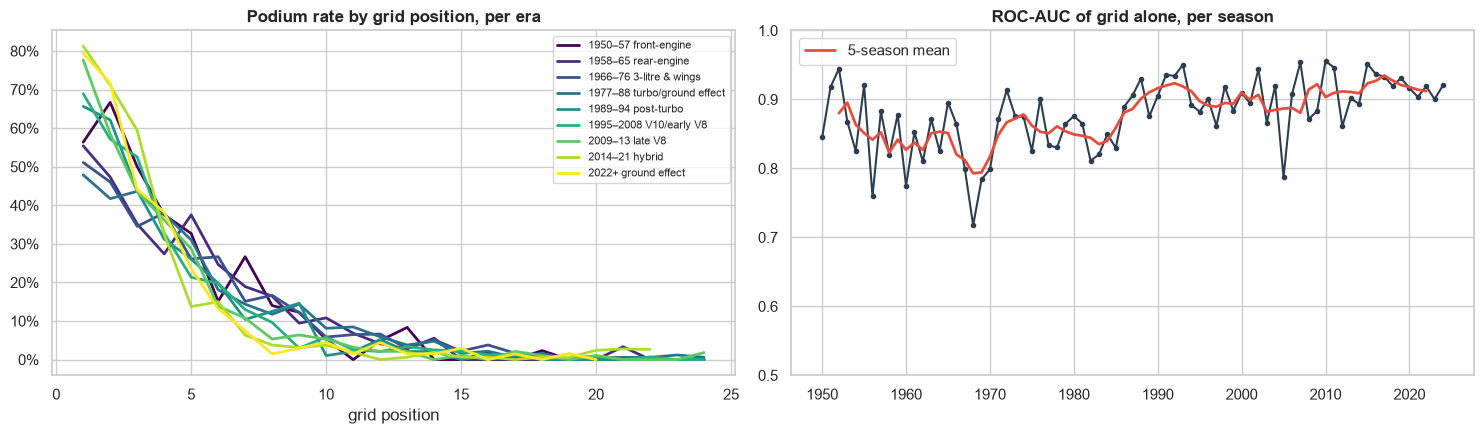

Pole → podium: 64.5% overall | by era:


,pole→podium
era,
1950–57 front-engine,56.4%
1958–65 rear-engine,55.4%
1966–76 3-litre & wings,51.1%
1977–88 turbo/ground effect,47.9%
1989–94 post-turbo,65.6%
1995–2008 V10/early V8,68.9%
2009–13 late V8,77.7%
2014–21 hybrid,81.2%
2022+ ground effect,79.4%


In [280]:
ERAS = [(1950, 1957, "1950–57 front-engine"), (1958, 1965, "1958–65 rear-engine"), (1966, 1976, "1966–76 3-litre & wings"),
        (1977, 1988, "1977–88 turbo/ground effect"), (1989, 1994, "1989–94 post-turbo"), (1995, 2008, "1995–2008 V10/early V8"),
        (2009, 2013, "2009–13 late V8"), (2014, 2021, "2014–21 hybrid"), (2022, 2100, "2022+ ground effect")]
def era_of(y):
    for a, b, lab in ERAS:
        if a <= y <= b: return lab
mt["era"] = mt.year.map(era_of)

pop = mt[mt.in_population].copy()
pop["grid_filled"] = pop.grid_clean.fillna(pop.groupby("raceId").driverId.transform("size"))  # pit lane -> back of field

g = pop[pop.grid_filled <= 24].groupby(["era", "grid_filled"]).podium.mean().unstack(0)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
g[[e for _, _, e in ERAS if e in g.columns]].plot(ax=axes[0], cmap="viridis", lw=2)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].set_xlabel("grid position"); axes[0].set_title("Podium rate by grid position, per era")
axes[0].legend(fontsize=8)

auc_year = pop.groupby("year").apply(lambda d: auc_safe(d.podium, -d.grid_filled))
auc_year.plot(ax=axes[1], color="#2c3e50", marker=".")
auc_year.rolling(5, center=True).mean().plot(ax=axes[1], color="#e74c3c", lw=2, label="5-season mean")
axes[1].set_title("ROC-AUC of grid alone, per season"); axes[1].set_xlabel(""); axes[1].set_ylim(.5, 1); axes[1].legend()
plt.tight_layout(); plt.show()

pole = pop[pop.grid_filled == 1]
print(f"Pole → podium: {pct(pole.podium.mean())} overall | by era:")
display(pole.groupby("era").podium.mean().reindex([e for _, _, e in ERAS]).dropna().map(pct).to_frame("pole→podium"))

In [281]:
note("7 · Grid",
     f"Grid alone reaches ROC-AUC ≈ {auc_safe(pop.podium, -pop.grid_filled):.3f}; pole converts to podium {pct(pole.podium.mean())} of the time, "
     f"with clear era variation (reliability, DRS, field size).",
     "Grid is the baseline feature and the 'simplest reasonable model' to beat; add era/season context or restrict the training window.")

> 📝 **Logged (7 · Grid)** — Grid alone reaches ROC-AUC ≈ 0.886; pole converts to podium 64.5% of the time, with clear era variation (reliability, DRS, field size).  
> ➜ *Grid is the baseline feature and the 'simplest reasonable model' to beat; add era/season context or restrict the training window.*

🔎 **Lead:** single features this strong make it tempting to throw in *every* column. But some columns are outcomes wearing a feature's clothes. Time to unmask them.

---
## Clue 8 — The impostors: a leakage screen

**Method:** compute the ROC-AUC of every numeric column in `results` (plus standings) *against the podium label*. Anything near 1.0 isn't a great feature — it's a confession. Then check timing: is the value known **before lights out**?

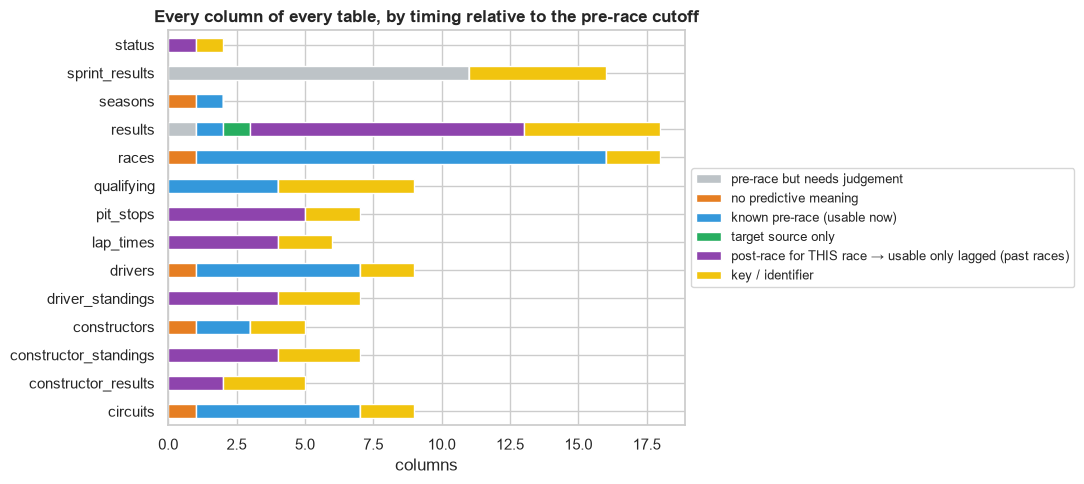

,table,column,verdict,why
0,results,number,⚠️ pre-race but needs judgement,"car number — known, but not a meaningful quantity"
1,sprint_results,number,⚠️ pre-race but needs judgement,"happens before Sunday, but exists only from 2021 (Clue 13)"
2,sprint_results,grid,⚠️ pre-race but needs judgement,"happens before Sunday, but exists only from 2021 (Clue 13)"
3,sprint_results,position,⚠️ pre-race but needs judgement,"happens before Sunday, but exists only from 2021 (Clue 13)"
4,sprint_results,positionText,⚠️ pre-race but needs judgement,"happens before Sunday, but exists only from 2021 (Clue 13)"
5,sprint_results,positionOrder,⚠️ pre-race but needs judgement,"happens before Sunday, but exists only from 2021 (Clue 13)"
6,sprint_results,points,⚠️ pre-race but needs judgement,"happens before Sunday, but exists only from 2021 (Clue 13)"
7,sprint_results,laps,⚠️ pre-race but needs judgement,"happens before Sunday, but exists only from 2021 (Clue 13)"
8,sprint_results,time,⚠️ pre-race but needs judgement,"happens before Sunday, but exists only from 2021 (Clue 13)"
9,sprint_results,milliseconds,⚠️ pre-race but needs judgement,"happens before Sunday, but exists only from 2021 (Clue 13)"


In [282]:
# Classify EVERY column of EVERY table by when it becomes known relative to the cutoff (after qualifying, before lights out).
KEY = "🔑 key / identifier"
OK = "✅ known pre-race (usable now)"
SPARSE = "⚠️ pre-race but needs judgement"
LAG = "🔁 post-race for THIS race → usable only lagged (past races)"
TARGET = "🎯 target source only"
NOPE = "⛔ no predictive meaning"

def column_timing(t, c):
    if c.endswith("Id") or c.endswith("Ref") or c in {"qualifyId", "resultId"}: return KEY, "join key"
    if c == "url": return NOPE, "Wikipedia link"
    if t in {"circuits", "constructors", "drivers", "seasons"}:
        hints = {"dob": "→ driver age at race", "nationality": "→ home-race flag (drivers) / team nationality",
                 "country": "→ home-race flag", "lat": "circuit geography", "lng": "circuit geography", "alt": "circuit altitude, often missing",
                 "number": "permanent number, modern era only", "code": "3-letter code, modern era only"}
        return OK, "static attribute " + hints.get(c, "")
    if t == "status": return LAG, "label for how a race ended — describes outcomes"
    if t == "races":
        return OK, "calendar/schedule fixed before the race" + (" → chronology" if c in {"year", "round", "date"} else "")
    if t == "qualifying":
        return (KEY, "join key") if c == "number" else (OK, "set in qualifying, before the cutoff")
    if t == "sprint_results": return SPARSE, "happens before Sunday, but exists only from 2021 (Clue 13)"
    if t in {"driver_standings", "constructor_standings"}: return LAG, "table AFTER this race — use standings before it (merge_asof)"
    if t == "constructor_results": return LAG, "team points in this race"
    if t in {"lap_times", "pit_stops"}: return LAG, "recorded during the race — only as history (e.g. past pit-stop speed)"
    if t == "results":
        if c == "positionOrder": return TARGET, "defines podium"
        if c == "grid": return OK, "starting grid, fixed before lights out"
        if c == "number": return SPARSE, "car number — known, but not a meaningful quantity"
        return LAG, "outcome of this race — previous races' values are legal form features"
    return SPARSE, "unclassified — decide by hand"

audit = pd.DataFrame([{"table": t, "column": c, "verdict": column_timing(t, c)[0], "why": column_timing(t, c)[1]}
                      for t, d in raw.items() for c in d.columns])
audit.to_csv(OUT / "column_timing_audit.csv", index=False)
summary = pd.crosstab(audit.table, audit.verdict)
summary.columns = [re.sub(r"^[^A-Za-z]+", "", c) for c in summary.columns]  # plot fonts lack emoji
fig, ax = plt.subplots(figsize=(11, 5))
summary.plot.barh(stacked=True, ax=ax, color=["#bdc3c7", "#e67e22", "#3498db", "#27ae60", "#8e44ad", "#f1c40f"][:summary.shape[1]])
ax.set_title("Every column of every table, by timing relative to the pre-race cutoff"); ax.set_xlabel("columns"); ax.set_ylabel("")
ax.legend(loc="center left", bbox_to_anchor=(1, .5), fontsize=9)
plt.tight_layout(); plt.show()
with pd.option_context("display.max_rows", 200):
    display(audit.sort_values(["verdict", "table"]).reset_index(drop=True))

**How to read the audit.** ✅ columns can be features as-is. 🔁 columns describe *this* race's outcome — forbidden as they are, but their **past values** are the raw material for form features (Clue 9). The full table is saved as `outputs/column_timing_audit.csv` for the report. The univariate AUC screen below then *confirms* the timing classification empirically for `results`: if a column marked 🔁 separates podiums almost perfectly, that's the leak showing itself.

,role at the pre-race cutoff
resultId,row identifier — not a measurement
raceId,race key — joins/order
driverId,driver key — identity/history
constructorId,team key — identity/history
number,"car number — known pre-race, usefulness doubtful"
grid,starting grid — known pre-race ✅ candidate feature
position,official finish — post-race ⛔
positionText,finish/status code — post-race ⛔
positionOrder,final order — TARGET source only
points,points this race — post-race ⛔


Past-race values of the ⛔ columns ARE legal once shifted (race t-1 is known before race t) — that is Clue 9.


column,coverage,AUC,|AUC-0.5|,known pre-race?
positionOrder,100%,0.000,0.500,NO — post-race
position,63%,0.000,0.500,NO — post-race
points,100%,0.964,0.464,NO — post-race
grid,100%,0.120,0.380,yes
rank,34%,0.126,0.374,NO — post-race
statusId,100%,0.126,0.374,NO — post-race
laps,100%,0.716,0.216,NO — post-race
number,100%,0.341,0.159,yes
fastestLapSpeed,33%,0.568,0.068,NO — post-race
milliseconds,31%,0.562,0.062,NO — post-race


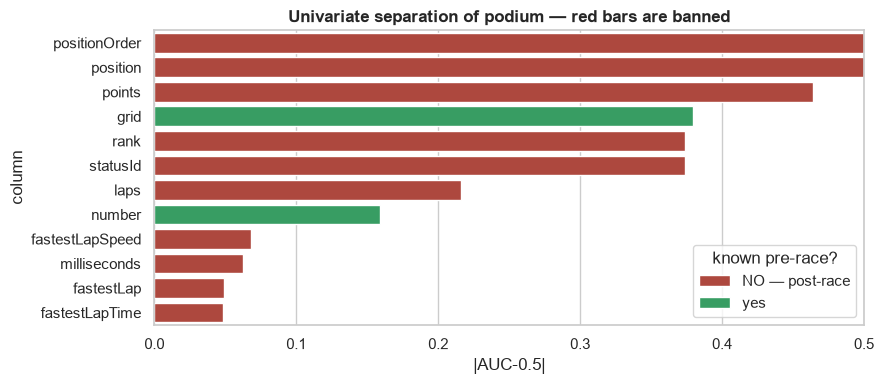

In [283]:
# 🗃 First-pass EDA: classify every results column by MEANING and TIMING before looking at any numbers
results_roles = {
    "resultId": "row identifier — not a measurement", "raceId": "race key — joins/order", "driverId": "driver key — identity/history",
    "constructorId": "team key — identity/history", "number": "car number — known pre-race, usefulness doubtful",
    "grid": "starting grid — known pre-race ✅ candidate feature", "position": "official finish — post-race ⛔",
    "positionText": "finish/status code — post-race ⛔", "positionOrder": "final order — TARGET source only",
    "points": "points this race — post-race ⛔", "laps": "laps completed — post-race ⛔", "time": "race time/gap — post-race ⛔",
    "milliseconds": "race time — post-race ⛔", "fastestLap": "fastest-lap lap — post-race ⛔", "rank": "fastest-lap rank — post-race ⛔",
    "fastestLapTime": "fastest-lap time — post-race ⛔", "fastestLapSpeed": "fastest-lap speed — post-race ⛔",
    "statusId": "how the race ended — post-race ⛔"}
display(pd.Series(results_roles, name="role at the pre-race cutoff").to_frame())
print("Past-race values of the ⛔ columns ARE legal once shifted (race t-1 is known before race t) — that is Clue 9.")

PRE_RACE = {"grid", "number", "constructorId", "driverId"}
cand = ["grid", "number", "points", "laps", "milliseconds", "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed",
        "position", "positionOrder", "statusId"]
rows = []
for c in cand:
    if c not in pop.columns: continue
    x = pd.to_numeric(pop[c], errors="coerce")
    a = auc_safe(pop.podium, x)
    rows.append({"column": c, "coverage": x.notna().mean(), "AUC": a, "|AUC-0.5|": abs(a - .5) if pd.notna(a) else np.nan,
                 "known pre-race?": "yes" if c in PRE_RACE else "NO — post-race"})
screen = pd.DataFrame(rows).sort_values("|AUC-0.5|", ascending=False)
display(screen.style.format({"coverage": "{:.0%}", "AUC": "{:.3f}", "|AUC-0.5|": "{:.3f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=screen, x="|AUC-0.5|", y="column", hue="known pre-race?", dodge=False,
            palette={"yes": "#27ae60", "NO — post-race": "#c0392b"}, ax=ax)
ax.set_title("Univariate separation of podium — red bars are banned"); ax.set_xlim(0, .5)
plt.tight_layout(); plt.show()

The obvious impostors are in `results` itself (points, laps, time, fastest lap, status). The **subtle** impostor is the standings tables: `driver_standings` for race *r* is the table **after** race *r* — it already contains this race's points. Same-race standings look like a great "form" feature. Let's prove it's a leak by comparing it with the standings **going into** the race.

In [284]:
ds = df["driver_standings"].merge(races[["raceId", "year", "round"]], on="raceId")
base = pop[["raceId", "driverId", "year", "round", "podium"]].copy()

same = base.merge(ds[["raceId", "driverId", "position", "points"]], on=["raceId", "driverId"], how="left")
prev = pd.merge_asof(base.sort_values("round"),
                     ds[["year", "driverId", "round", "position", "points", "wins"]].sort_values("round")
                       .rename(columns={"position": "prev_standing_pos", "points": "prev_standing_pts", "wins": "prev_wins"}),
                     on="round", by=["year", "driverId"], allow_exact_matches=False, direction="backward")

leak_cmp = pd.DataFrame({
    "AUC same-race standing position (post-race)": [auc_safe(same.podium, -same.position)],
    "AUC standing position BEFORE race (leak-safe)": [auc_safe(prev.podium, -prev.prev_standing_pos)],
    "AUC same-race points (post-race)": [auc_safe(same.podium, same.points)],
    "AUC points BEFORE race (leak-safe)": [auc_safe(prev.podium, prev.prev_standing_pts)],
}).T.rename(columns={0: "ROC-AUC"})
display(leak_cmp.style.format("{:.3f}"))
r1 = prev[prev["round"] == 1]
print(f"Leak-safe standings are missing for round 1 by construction: {pct(r1.prev_standing_pos.isna().mean())} of round-1 rows "
      f"(and {pct(prev.prev_standing_pos.isna().mean())} of all rows).")

,ROC-AUC
AUC same-race standing position (post-race),0.924
AUC standing position BEFORE race (leak-safe),0.841
AUC same-race points (post-race),0.847
AUC points BEFORE race (leak-safe),0.783


Leak-safe standings are missing for round 1 by construction: 100.0% of round-1 rows (and 11.8% of all rows).


In [285]:
note("8 · Leakage",
     "points, laps, milliseconds, fastest-lap fields, status, position(Order) are post-race (AUC near 1 or explained by the outcome). "
     f"Same-race standings AUC {leak_cmp.iloc[0,0]:.3f} vs before-race {leak_cmp.iloc[1,0]:.3f} — the gap is pure leakage.",
     "Ban all post-race columns. Standings features use merge_asof on round with allow_exact_matches=False (standings before this race); "
     "round-1 values are missing by design → indicator + fill.")

> 📝 **Logged (8 · Leakage)** — points, laps, milliseconds, fastest-lap fields, status, position(Order) are post-race (AUC near 1 or explained by the outcome). Same-race standings AUC 0.924 vs before-race 0.841 — the gap is pure leakage.  
> ➜ *Ban all post-race columns. Standings features use merge_asof on round with allow_exact_matches=False (standings before this race); round-1 values are missing by design → indicator + fill.*

🔎 **Lead:** the honest version of "form" must only look backwards. Let's build it and *prove* its alibi.

---
## Clue 9 — The alibi check: leakage-safe form features

Form = recent results **strictly before** the current race date. Recipe: sort by date, compute per-entity history, then `shift(1)` *before* rolling, so the current race never contributes. Two entities matter (the intro doc: car performance dominates): **constructor** and **driver**.

In [286]:
W = 5
mt = mt.sort_values(["date", "raceId"]).reset_index(drop=True)
hist = mt[mt.in_population].copy()

# Driver form: podium rate and mean finish over last W starts, plus career podiums so far
gd = hist.groupby("driverId")
hist["drv_form_podium"] = gd.podium.transform(lambda s: s.shift(1).rolling(W, min_periods=1).mean())
hist["drv_form_finish"] = gd.positionOrder.transform(lambda s: s.shift(1).rolling(W, min_periods=1).mean())
hist["drv_career_podiums"] = gd.podium.transform(lambda s: s.shift(1).cumsum())
hist["drv_starts_before"] = gd.cumcount()

# Constructor form: computed on a constructor-race table (any car on the podium?), then joined back
cr = (hist.groupby(["constructorId", "raceId"], as_index=False)
          .agg(date=("date", "first"), c_podium=("podium", "max"), c_best=("positionOrder", "min"))
          .sort_values(["date", "raceId"]))
gc = cr.groupby("constructorId")
cr["con_form_podium"] = gc.c_podium.transform(lambda s: s.shift(1).rolling(W, min_periods=1).mean())
cr["con_form_best"] = gc.c_best.transform(lambda s: s.shift(1).rolling(W, min_periods=1).mean())
hist = hist.merge(cr[["constructorId", "raceId", "con_form_podium", "con_form_best"]], on=["constructorId", "raceId"], how="left")
print("Form features built for", f"{len(hist):,}", "rows.")

Form features built for 24,666 rows.


**The alibi test.** For random rows, recompute the driver's form by hand from races with an *earlier date only*, and require an exact match. If the current race leaked in, this fails.

In [287]:
sample = hist[hist.drv_starts_before >= W].sample(min(200, (hist.drv_starts_before >= W).sum()), random_state=1)
mism = 0
for _, row in sample.iterrows():
    past = hist[(hist.driverId == row.driverId) & (hist.date < row.date)].sort_values(["date", "raceId"]).tail(W)
    if not np.isclose(past.podium.mean(), row.drv_form_podium): mism += 1
print(f"Alibi check on {len(sample)} random rows: {mism} mismatches", "✅" if mism == 0 else "❌ leakage or tie-ordering issue")

Alibi check on 200 random rows: 0 mismatches ✅


feature,coverage,AUC (sign-adjusted)
quali_pos,42%,0.908
grid_filled,100%,0.886
prev_standing_pos,88%,0.841
q1_gap_pct,42%,0.827
con_form_podium,99%,0.823
con_form_best,99%,0.821
drv_form_podium,97%,0.815
drv_form_finish,97%,0.800
prev_standing_pts,88%,0.783
drv_career_podiums,97%,0.776


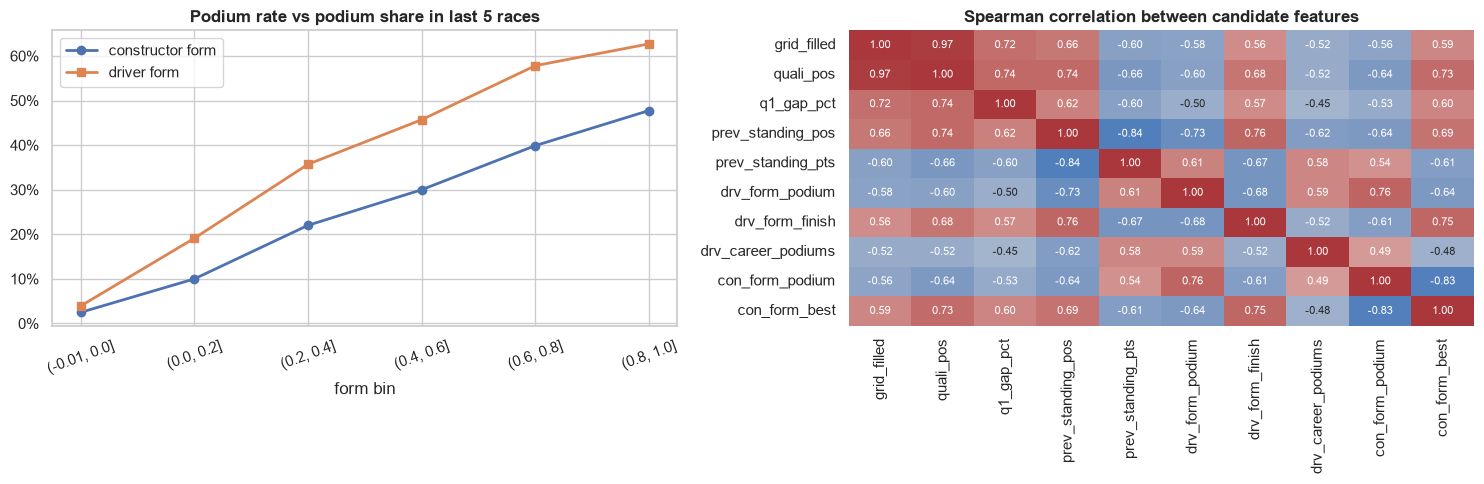

In [288]:
hist = hist.merge(prev[["raceId", "driverId", "prev_standing_pos", "prev_standing_pts", "prev_wins"]], on=["raceId", "driverId"], how="left")
hist["grid_filled"] = hist.grid_clean.fillna(hist.groupby("raceId").driverId.transform("size"))
hist = hist.merge(qq[["raceId", "driverId", "q1_gap_pct"]], on=["raceId", "driverId"], how="left")

FEATS = {"grid_filled": -1, "quali_pos": -1, "q1_gap_pct": -1, "prev_standing_pos": -1, "prev_standing_pts": 1,
         "drv_form_podium": 1, "drv_form_finish": -1, "drv_career_podiums": 1, "con_form_podium": 1, "con_form_best": -1}
ev = pd.DataFrame([{"feature": f, "coverage": hist[f].notna().mean(), "AUC (sign-adjusted)": auc_safe(hist.podium, s * hist[f])}
                   for f, s in FEATS.items()]).sort_values("AUC (sign-adjusted)", ascending=False)
display(ev.style.format({"coverage": "{:.0%}", "AUC (sign-adjusted)": "{:.3f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
b = hist.assign(con_bin=pd.cut(hist.con_form_podium, [-.01, 0, .2, .4, .6, .8, 1]),
                drv_bin=pd.cut(hist.drv_form_podium, [-.01, 0, .2, .4, .6, .8, 1]))
b.groupby("con_bin", observed=True).podium.mean().plot(ax=axes[0], marker="o", label="constructor form", lw=2)
b.groupby("drv_bin", observed=True).podium.mean().plot(ax=axes[0], marker="s", label="driver form", lw=2)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].set_title(f"Podium rate vs podium share in last {W} races")
axes[0].set_xlabel("form bin"); axes[0].legend(); axes[0].tick_params(axis="x", rotation=20)
corr = hist[list(FEATS)].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1], cbar=False, annot_kws={"size": 8})
axes[1].set_title("Spearman correlation between candidate features")
plt.tight_layout(); plt.show()

Read the correlation matrix as a **redundancy map**: highly correlated features (e.g. grid vs qualifying position, form vs prior standings) will split importance between them in SHAP/permutation importance — something to remember when interpreting XAI and designing the ablation groups (grid · qualifying · standings · form).

In [289]:
note("9 · Form",
     f"Backward-looking form passes the alibi test ({mism} mismatches). Best leak-safe signals after grid: "
     + ", ".join(f"{r.feature} ({r['AUC (sign-adjusted)']:.2f})" for _, r in ev.head(4).iterrows()) + ".",
     "Use shift(1)-then-roll form features on driver and constructor; ablation groups = grid / qualifying / standings / driver form / constructor form.")

> 📝 **Logged (9 · Form)** — Backward-looking form passes the alibi test (0 mismatches). Best leak-safe signals after grid: quali_pos (0.91), grid_filled (0.89), prev_standing_pos (0.84), q1_gap_pct (0.83).  
> ➜ *Use shift(1)-then-roll form features on driver and constructor; ablation groups = grid / qualifying / standings / driver form / constructor form.*

🔎 **Lead:** a podium needs a car that *finishes*. Reliability changed enormously over 75 years — how, and does the status mapping hold up?

---
## Clue 10 — Why cars stop

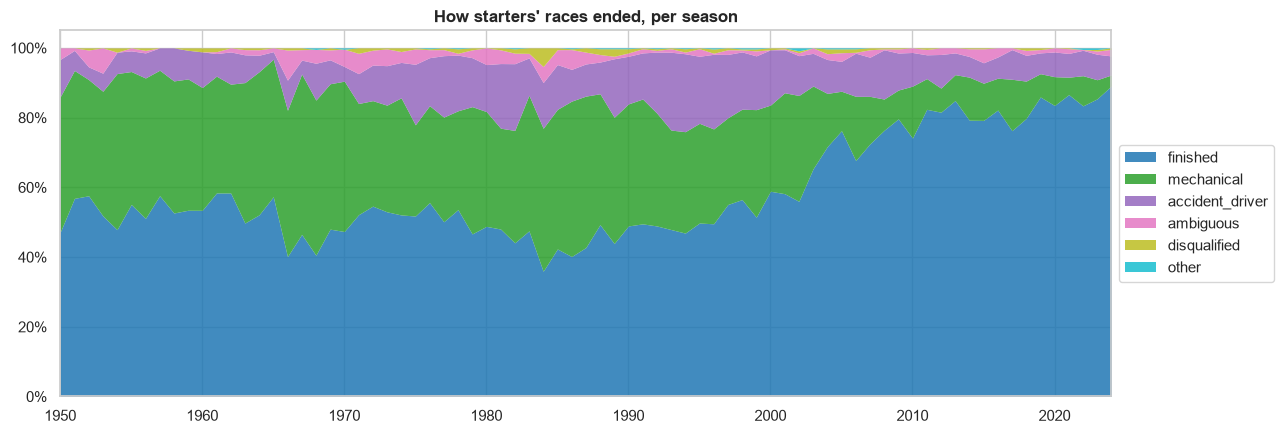

Finish rate 1950s: 53.1% → 2020s: 85.6%


In [290]:
starters = mt[mt.in_population].copy()
share = pd.crosstab(starters.year, starters.status_cat, normalize="index")
order = [c for c in ["finished", "mechanical", "accident_driver", "ambiguous", "disqualified", "other", "unknown"] if c in share.columns]
fig, ax = plt.subplots(figsize=(13, 4.5))
share[order].plot.area(ax=ax, cmap="tab10", alpha=.85, lw=0)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlabel(""); ax.set_xlim(share.index.min(), share.index.max())
ax.set_title("How starters' races ended, per season"); ax.legend(loc="center left", bbox_to_anchor=(1, .5))
plt.tight_layout(); plt.show()
print(f"Finish rate 1950s: {pct(share.loc[1950:1959, 'finished'].mean())} → 2020s: {pct(share.loc[2020:, 'finished'].mean())}")

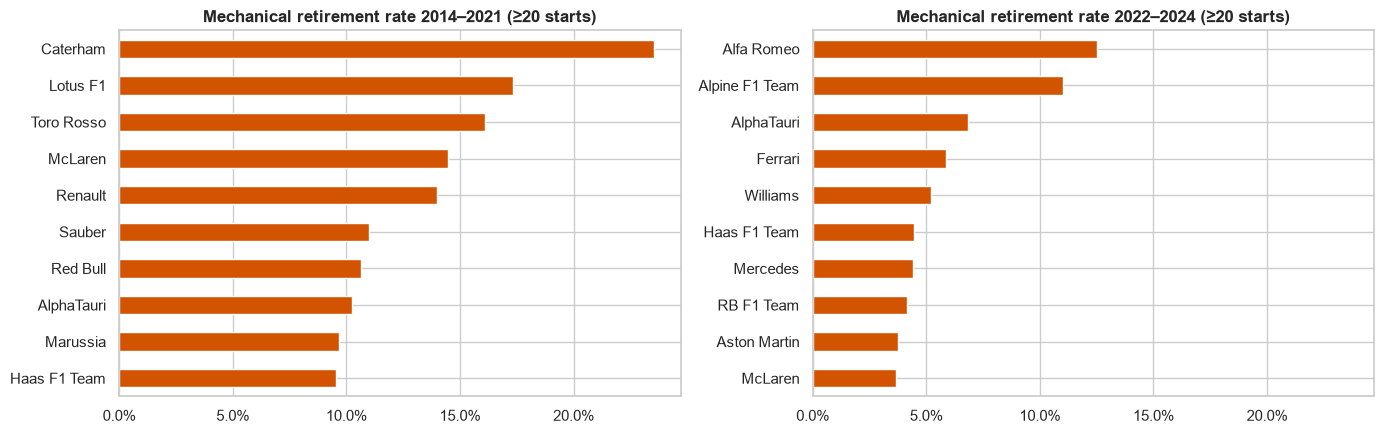

In [291]:
# Preview of DE-Q3. A "start" = one car taking the start of one race (a team with 2 cars × 22 races = 44 starts).
# Teams below 20 starts in the period are dropped: with 3 starts, one failure already reads as 33% — noise, not reliability.
def mech_rate(lo, hi, min_starts=20):
    d = starters[starters.year.between(lo, hi)]
    t = d.groupby("constructor").agg(starts=("status_cat", "size"), mech=("status_cat", lambda s: (s == "mechanical").sum()))
    t = t[t.starts >= min_starts]
    t["mech_rate"] = t.mech / t.starts
    return t.sort_values("mech_rate", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, (lo, hi) in zip(axes, [(2014, 2021), (2022, 2024)]):
    t = mech_rate(lo, hi).head(10)
    if len(t):
        t.mech_rate.sort_values().plot.barh(ax=ax, color="#d35400")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title(f"Mechanical retirement rate {lo}–{hi} (≥20 starts)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Why "≥ 20 starts"?** A *start* is one car beginning one race. Rates computed from a handful of starts are dominated by luck: a one-off entrant with 2 starts and 1 engine failure has a "50% mechanical rate". The 20-start floor (≈ half a season for a two-car team) keeps only teams with enough evidence; for the final DE-Q3 answer, report the starts next to each rate and consider a confidence interval.

In [292]:
amb_rows = (starters.status_cat == "ambiguous").sum()
note("10 · Reliability",
     f"Finish rate rose from {pct(share.loc[1950:1959, 'finished'].mean())} (1950s) to {pct(share.loc[2020:, 'finished'].mean())} (2020s); "
     f"{amb_rows:,} starter rows have ambiguous statuses (tyre, puncture, 'Retired', damage, fuel…).",
     "Status mapping saved to outputs/status_mapping.csv; document ambiguous calls; constructor reliability (past races only) is a candidate feature.")

> 📝 **Logged (10 · Reliability)** — Finish rate rose from 53.1% (1950s) to 85.6% (2020s); 494 starter rows have ambiguous statuses (tyre, puncture, 'Retired', damage, fuel…).  
> ➜ *Status mapping saved to outputs/status_mapping.csv; document ambiguous calls; constructor reliability (past races only) is a candidate feature.*

🔎 **Lead:** DE-Q2 asks about home races. That needs a join the schema doesn't provide: driver *nationality* ("British") to circuit *country* ("UK").

---
## Clue 11 — Home advantage? (the missing join)

In [293]:
NAT2COUNTRY = {
    "British": "UK", "American": "USA", "German": "Germany", "East German": "Germany", "Italian": "Italy", "French": "France",
    "Brazilian": "Brazil", "Spanish": "Spain", "Finnish": "Finland", "Australian": "Australia", "Austrian": "Austria",
    "Dutch": "Netherlands", "Belgian": "Belgium", "Swiss": "Switzerland", "Swedish": "Sweden", "Canadian": "Canada",
    "Mexican": "Mexico", "Japanese": "Japan", "Argentine": "Argentina", "Argentinian": "Argentina", "South African": "South Africa",
    "Monegasque": "Monaco", "Portuguese": "Portugal", "Hungarian": "Hungary", "Russian": "Russia", "Chinese": "China",
    "Indian": "India", "Malaysian": "Malaysia", "Turkish": "Turkey", "Moroccan": "Morocco", "Saudi": "Saudi Arabia",
    "Emirati": "UAE", "Korean": "Korea", "Azerbaijani": "Azerbaijan", "Qatari": "Qatar", "Bahraini": "Bahrain",
    "Singaporean": "Singapore", "Danish": "Denmark", "New Zealander": "New Zealand", "Polish": "Poland", "Irish": "Ireland",
    "Venezuelan": "Venezuela", "Colombian": "Colombia", "Thai": "Thailand", "Chilean": "Chile", "Uruguayan": "Uruguay",
    "Rhodesian": "Rhodesia", "Czech": "Czech Republic", "Liechtensteiner": "Liechtenstein", "Indonesian": "Indonesia",
    "American-Italian": "USA", "Argentine-Italian": "Argentina",
}
COUNTRY_ALIASES = {"United States": "USA", "United Kingdom": "UK", "Great Britain": "UK", "United Arab Emirates": "UAE",
                   "South Korea": "Korea", "Russian Federation": "Russia"}

circ_countries = set(circuits.circuit_country.dropna().replace(COUNTRY_ALIASES))
nats = mt.nationality.value_counts()
unmapped_nat = [n for n in nats.index if n not in NAT2COUNTRY]
print("Circuit countries in data:", sorted(circ_countries))
print("\nNationalities with NO mapping (rows):", {n: int(nats[n]) for n in unmapped_nat} or "none")
mapped_to_nowhere = sorted({NAT2COUNTRY[n] for n in nats.index if n in NAT2COUNTRY} - circ_countries)
print("\nMapped countries that never hosted a race (always 'away', fine):", mapped_to_nowhere)

Circuit countries in data: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA']

Nationalities with NO mapping (rows): {'Argentinian ': 9}

Mapped countries that never hosted a race (always 'away', fine): ['Chile', 'Colombia', 'Czech Republic', 'Denmark', 'Finland', 'Indonesia', 'Ireland', 'Liechtenstein', 'New Zealand', 'Poland', 'Rhodesia', 'Thailand', 'Uruguay', 'Venezuela']


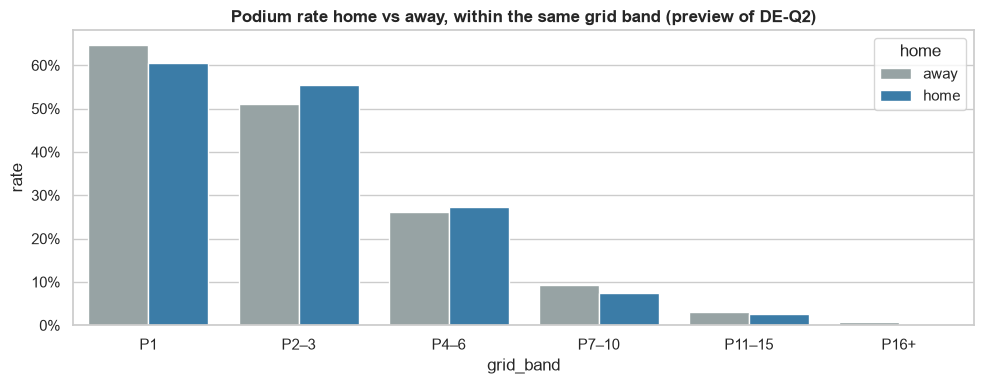

rate                 n       
home           away      home    away   home
grid_band                                   
P1         0.647915  0.604938  1031.0   81.0
P2–3       0.510875  0.554054  2069.0  148.0
P4–6       0.261767  0.272321  3102.0  224.0
P7–10      0.093857  0.074627  4102.0  335.0
P11–15     0.030113  0.026506  5114.0  415.0
P16+       0.007251  0.002717  7309.0  736.0

Home rows: 1,939 (7.9%); raw home vs away podium rate: 11.9% vs 13.8%


In [294]:
pop = mt[mt.in_population].copy()
pop["driver_country"] = pop.nationality.map(NAT2COUNTRY)
pop["race_country"] = pop.circuit_country.replace(COUNTRY_ALIASES)
pop["home"] = (pop.driver_country == pop.race_country).astype(int)
pop["grid_filled"] = pop.grid_clean.fillna(pop.groupby("raceId").driverId.transform("size"))
pop["grid_band"] = pd.cut(pop.grid_filled, [0, 1, 3, 6, 10, 15, 100], labels=["P1", "P2–3", "P4–6", "P7–10", "P11–15", "P16+"])

hb = pop.groupby(["grid_band", "home"], observed=True).agg(rate=("podium", "mean"), n=("podium", "size")).reset_index()
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=hb, x="grid_band", y="rate", hue=hb.home.map({0: "away", 1: "home"}), ax=ax, palette=["#95a5a6", "#2980b9"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title("Podium rate home vs away, within the same grid band (preview of DE-Q2)")
plt.tight_layout(); plt.show()
display(hb.pivot(index="grid_band", columns="home", values=["rate", "n"]).rename(columns={0: "away", 1: "home"}))
print(f"Home rows: {pop.home.sum():,} ({pct(pop.home.mean())}); raw home vs away podium rate: "
      f"{pct(pop[pop.home==1].podium.mean())} vs {pct(pop[pop.home==0].podium.mean())}")

The bars compare home vs away **within** each grid band by eye. The formal test, with every number explained, is **DE-Q2 in Part III**, run on the cleaned table.

In [295]:
note("11 · Home",
     f"No direct key between nationality and circuit country; a hand mapping covers all but {len(unmapped_nat)} nationalities. "
     "Raw home-vs-away rates are confounded by grid position.",
     "Compare home vs away within grid bands; formal test in DE-Q2. `home` is a candidate feature.")

> 📝 **Logged (11 · Home)** — No direct key between nationality and circuit country; a hand mapping covers all but 1 nationalities. Raw home-vs-away rates are confounded by grid position.  
> ➜ *Compare home vs away within grid bands; formal test in DE-Q2. `home` is a candidate feature.*

🔎 **Lead:** form features follow `driverId` and `constructorId`. But drivers and teams come and go every season — how many rows have no history to build form from?

---
## Clue 12 — Who's new here? Driver and team turnover

> **The question:** form features (Clue 9) summarise a driver's or team's *past*. That only works if they **have** a past. How many rows belong to newcomers with little or no history — and does that change by era?

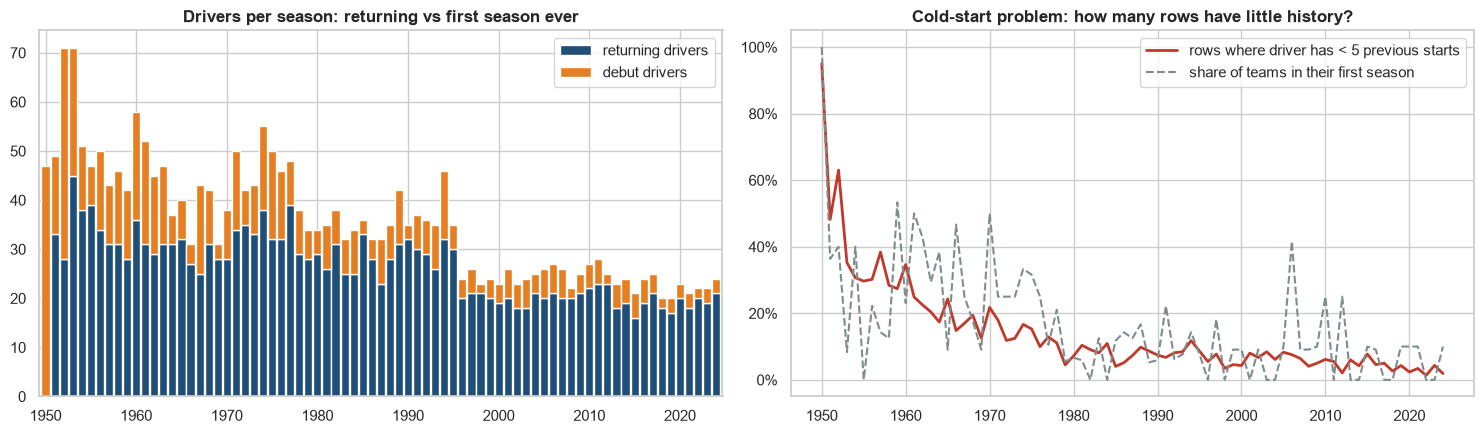

Driver-seasons that are debuts: 25.8% | rows with <5 previous starts: 10.4% | driver-seasons with a mid-season team change: 9.4%
Constructors: 210; with ≤5 races ever: 81 (privateers / one-offs → cold-start form)


,first,last,races
constructor,,,
Ligier,1976,1996,330
Minardi,1985,2005,345
Red Bull,2005,2024,394
Team Lotus,1958,1994,395
Renault,1977,2020,403
Sauber,1993,2024,419
Tyrrell,1970,1998,433
Williams,1975,2024,843
McLaren,1968,2024,929


In [296]:
P = mt[mt.in_population]
dy = P[["year", "driverId"]].drop_duplicates()
dy["debut"] = dy.year == dy.driverId.map(P.groupby("driverId").year.min())
cy = P[["year", "constructorId"]].drop_duplicates()
cy["debut"] = cy.year == cy.constructorId.map(P.groupby("constructorId").year.min())
switch = P.groupby(["year", "driverId"]).constructorId.nunique()

turn = pd.DataFrame({"returning drivers": dy[~dy.debut].groupby("year").size(), "debut drivers": dy[dy.debut].groupby("year").size()}).fillna(0)
cold = hist.assign(cold=hist.drv_starts_before < 5).groupby("year").cold.mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
turn.plot.bar(stacked=True, ax=axes[0], color=["#1f4e79", "#e67e22"], width=.9)
axes[0].set_title("Drivers per season: returning vs first season ever"); axes[0].set_xlabel("")
axes[0].set_xticks([i for i, y in enumerate(turn.index) if y % 10 == 0]); axes[0].set_xticklabels([y for y in turn.index if y % 10 == 0], rotation=0)
cold.plot(ax=axes[1], color="#c0392b", lw=2, label="rows where driver has < 5 previous starts")
cy.groupby("year").debut.mean().plot(ax=axes[1], color="#7f8c8d", lw=1.5, ls="--", label="share of teams in their first season")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].set_title("Cold-start problem: how many rows have little history?")
axes[1].legend(); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
print(f"Driver-seasons that are debuts: {pct(dy.debut.mean())} | rows with <5 previous starts: {pct((hist.drv_starts_before < 5).mean())} "
      f"| driver-seasons with a mid-season team change: {pct((switch > 1).mean())}")

con_life = mt.groupby("constructor").agg(first=("year", "min"), last=("year", "max"), races=("raceId", "nunique")).sort_values("races")
print(f"Constructors: {len(con_life)}; with ≤5 races ever: {(con_life.races <= 5).sum()} (privateers / one-offs → cold-start form)")
display(con_life.tail(10))

In [297]:
note("12 · Identity",
     f"{pct(dy.debut.mean())} of driver-seasons are debuts; {pct((hist.drv_starts_before < 5).mean())} of rows have <5 previous starts; "
     f"{(con_life.races <= 5).sum()} constructors have ≤5 races ever; renames create new constructorIds.",
     "Form features need min_periods and a 'starts_before' counter; cold-start rows get NaN + indicator, not 0. Accept that renames reset history.")

> 📝 **Logged (12 · Identity)** — 25.8% of driver-seasons are debuts; 10.4% of rows have <5 previous starts; 81 constructors have ≤5 races ever; renames create new constructorIds.  
> ➜ *Form features need min_periods and a 'starts_before' counter; cold-start rows get NaN + indicator, not 0. Accept that renames reset history.*

🔎 **Lead:** since 2021 some weekends have a Saturday sprint — which runs *before* the main race. Is it allowed information?

---
## Clue 13 — The sprint question

> **The question:** on sprint weekends there is a short race on **Saturday**, *before* the main race on Sunday that we predict. Its result is therefore already known at our cutoff. **Should we use "how the driver did in the sprint" as a feature?** Two sub-questions decide it: ① is it legal (known before lights out)? ② is there enough of it to learn from?

In [298]:
sr = df["sprint_results"].merge(races[["raceId", "year"]], on="raceId")
print("Sprint rows per season:", sr.groupby("year").raceId.nunique().rename("sprint weekends").to_dict())
j = sr[["raceId", "driverId", "positionOrder", "year"]].rename(columns={"positionOrder": "sprint_pos"}).merge(
    mt[["raceId", "driverId", "grid_clean", "podium"]], on=["raceId", "driverId"])
sp = j.groupby("year").apply(lambda d: pd.Series({"spearman(sprint pos, main grid)": stats.spearmanr(d.sprint_pos, d.grid_clean, nan_policy="omit")[0],
                                                  "AUC sprint pos → podium": auc_safe(d.podium, -d.sprint_pos), "rows": len(d)}))
display(sp.style.format({"spearman(sprint pos, main grid)": "{:.2f}", "AUC sprint pos → podium": "{:.3f}", "rows": "{:.0f}"}))

Sprint rows per season: {2021: 3, 2022: 3, 2023: 6, 2024: 6}


,"spearman(sprint pos, main grid)",AUC sprint pos → podium,rows
year,,,
2021,0.89,0.954,60
2022,0.99,0.948,60
2023,0.62,0.866,120
2024,0.54,0.827,120


**Answer:** ① yes, it's legal. ② no — it's too sparse.

In 2021–22 the sprint *set* the Sunday grid, so the sprint result is almost the grid itself; from 2023 it is a separate event. The sprint happens before the race, so it is **not leakage** at our cutoff — but it exists for only a handful of races in the val/test seasons and never in training (≤2019). A feature that's absent from the entire training set can't be learned.

In [299]:
note("13 · Sprint",
     f"Sprint results exist only from {sr.year.min()} ({sr.raceId.nunique()} weekends in total); Spearman(sprint pos, main grid) by season: "
     + ", ".join(f"{int(y)}: {v:.2f}" for y, v in sp["spearman(sprint pos, main grid)"].items()) + ".",
     "Treat sprint as legal pre-race info but exclude it from features (absent in training split); mention as a limitation/extension.")

> 📝 **Logged (13 · Sprint)** — Sprint results exist only from 2021 (18 weekends in total); Spearman(sprint pos, main grid) by season: 2021: 0.89, 2022: 0.99, 2023: 0.62, 2024: 0.54.  
> ➜ *Treat sprint as legal pre-race info but exclude it from features (absent in training split); mention as a limitation/extension.*

🔎 **Lead:** the brief's split is train ≤2019, validation 2020–21, test ≥2022. Every clue so far says the sport changed. Does each split see the same world?

---
## Clue 14 — Different eras, different worlds: auditing the split

> **The question:** the brief fixes the split as train ≤ 2019, validation 2020–21, test ≥ 2022. A model learns patterns from train and is graded on test — that only works if both periods **look alike**. Every clue so far says F1 changed (field size, reliability, qualifying data). So: **how different is the training world from the test world, and what should we do about it?**
>
> We compare the splits on what the model would actually see: base rate, field size, qualifying coverage, feature distributions and how predictive grid is.

,rows,races,seasons,podium_rate,mean_field,quali_coverage,grid_AUC
split,,,,,,,
train ≤2019,"22,533",1007,70,13.5%,22.4,37%,0.883
val 2020–21,779,39,2,15.0%,20.0,100%,0.909
test ≥2022,"1,354",68,3,15.1%,19.9,100%,0.914


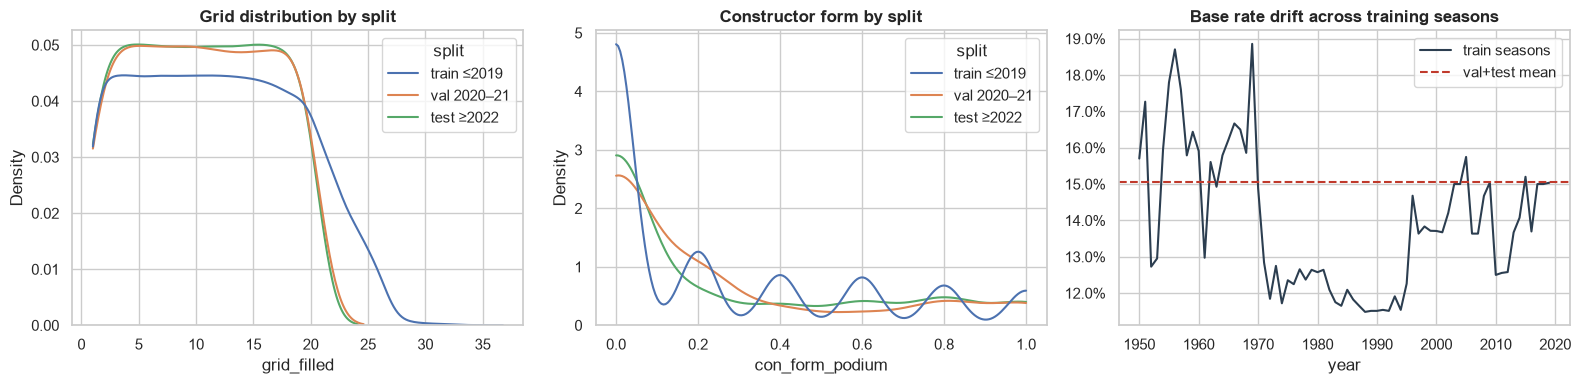

In [300]:
H = hist.copy()
H["split"] = np.select([H.year <= 2019, H.year <= 2021], ["train ≤2019", "val 2020–21"], "test ≥2022")
order_s = ["train ≤2019", "val 2020–21", "test ≥2022"]
split_tab = H.groupby("split").agg(rows=("podium", "size"), races=("raceId", "nunique"), seasons=("year", "nunique"),
                                   podium_rate=("podium", "mean"), mean_field=("raceId", lambda s: s.value_counts().mean()),
                                   quali_coverage=("quali_pos", lambda s: s.notna().mean()),
                                   grid_AUC=("podium", lambda s: auc_safe(s, -H.loc[s.index, "grid_filled"]))).reindex(order_s)
display(split_tab.style.format({"podium_rate": "{:.1%}", "mean_field": "{:.1f}", "quali_coverage": "{:.0%}", "grid_AUC": "{:.3f}", "rows": "{:,}"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.kdeplot(data=H, x="grid_filled", hue="split", hue_order=order_s, common_norm=False, ax=axes[0], clip=(1, 40))
axes[0].set_title("Grid distribution by split")
sns.kdeplot(data=H, x="con_form_podium", hue="split", hue_order=order_s, common_norm=False, ax=axes[1], clip=(0, 1))
axes[1].set_title("Constructor form by split")
H[H.split == "train ≤2019"].groupby("year").podium.mean().plot(ax=axes[2], color="#2c3e50", label="train seasons")
axes[2].axhline(H[H.split != "train ≤2019"].podium.mean(), color="#c0392b", ls="--", label="val+test mean")
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[2].set_title("Base rate drift across training seasons"); axes[2].legend()
plt.tight_layout(); plt.show()

The training split mixes 70 seasons with different field sizes, reliability and data coverage, while validation/test are uniform ~20-car modern fields. Two experiments are worth running in the modeling phase (they double as the brief's "preprocessing-order experiments"):

1. **Full history** with missingness indicators vs **modern window only** (e.g. seasons with qualifying coverage) — does more old data help or hurt on 2022+?
2. **Fit imputers/scalers on train only** (correct) vs on all data (leaky) — shows why order matters.

In [301]:
note("14 · Split",
     f"Train base rate {split_tab.loc['train ≤2019','podium_rate']:.1%} vs val {split_tab.loc['val 2020–21','podium_rate']:.1%} / test {split_tab.loc['test ≥2022','podium_rate']:.1%}; "
     f"qualifying coverage {split_tab.loc['train ≤2019','quali_coverage']:.0%} vs {split_tab.loc['test ≥2022','quali_coverage']:.0%}.",
     "Keep the chronological split (no future leakage across seasons); compare full-history vs modern-window training; fit all preprocessing on train only.")

> 📝 **Logged (14 · Split)** — Train base rate 13.5% vs val 15.0% / test 15.1%; qualifying coverage 37% vs 100%.  
> ➜ *Keep the chronological split (no future leakage across seasons); compare full-history vs modern-window training; fit all preprocessing on train only.*

---
## Clue 15 — Before vs after: what did the cleaning change?

The brief asks for EDA **before and after** cleaning. Same metrics, raw `results` vs the cleaned modeling base.

,raw results,cleaned modeling base
rows,"26,759","24,666"
'\N' cells,"122,887",0.0%
"dup (raceId, driverId)",91,0.0%
rows that never started,"1,621",0.0%
Indy 500 rows,381,0.0%
grid == 0 rows,"1,638",128
races with ≠3 podium rows,18,15
podium base rate,12.7%,13.6%


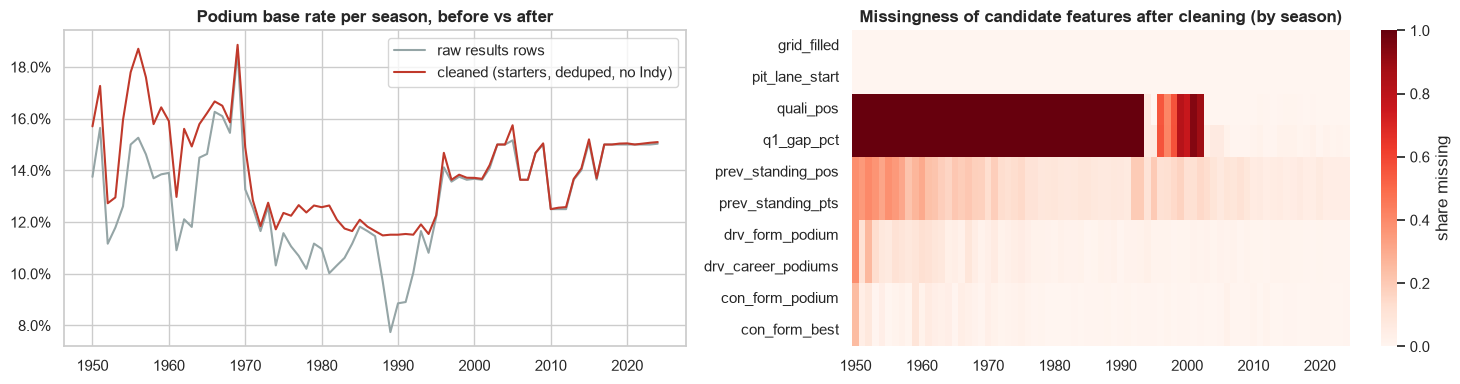

In [302]:
clean = H.copy()
before_after = pd.DataFrame({
    "raw results": {
        "rows": len(raw["results"]),
        "'\\N' cells": int((raw["results"] == "\\N").sum().sum()),
        "dup (raceId, driverId)": int(raw["results"].duplicated(["raceId", "driverId"]).sum()),
        "rows that never started": int((mt.status_cat == "non_start").sum()),
        "Indy 500 rows": int(is_indy.sum()),
        "grid == 0 rows": int((raw["results"].grid == "0").sum()),
        "races with ≠3 podium rows": int((res[res.positionOrder <= 3].groupby("raceId").size() != 3).sum()),
        "podium base rate": (pd.to_numeric(raw["results"].positionOrder) <= 3).mean(),
    },
    "cleaned modeling base": {
        "rows": len(clean),
        "'\\N' cells": 0,
        "dup (raceId, driverId)": int(clean.duplicated(["raceId", "driverId"]).sum()),
        "rows that never started": int((clean.status_cat == "non_start").sum()),
        "Indy 500 rows": int(clean.race.str.contains("Indianapolis 500", case=False, na=False).sum()),
        "grid == 0 rows": int((clean.grid == 0).sum()),
        "races with ≠3 podium rows": int((clean.groupby("raceId").podium.sum() != 3).sum()),
        "podium base rate": clean.podium.mean(),
    }})
display(before_after.style.format(lambda v: f"{v:.1%}" if isinstance(v, float) and v < 1 else f"{v:,.0f}"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
rr = res.assign(podium=res.positionOrder <= 3).groupby("year").podium.mean()
cc = clean.groupby("year").podium.mean()
rr.plot(ax=axes[0], label="raw results rows", color="#95a5a6"); cc.plot(ax=axes[0], label="cleaned (starters, deduped, no Indy)", color="#c0392b")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].set_title("Podium base rate per season, before vs after"); axes[0].legend(); axes[0].set_xlabel("")
model_cols = ["grid_filled", "pit_lane_start", "quali_pos", "q1_gap_pct", "prev_standing_pos", "prev_standing_pts",
              "drv_form_podium", "drv_career_podiums", "con_form_podium", "con_form_best"]
miss = clean.groupby("year")[model_cols].apply(lambda d: d.isna().mean()).T
sns.heatmap(miss, cmap="Reds", vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "share missing"})
xt = [i for i, y in enumerate(miss.columns) if y % 10 == 0]
axes[1].set_xticks([i + .5 for i in xt]); axes[1].set_xticklabels([miss.columns[i] for i in xt], rotation=0)
axes[1].set_title("Missingness of candidate features after cleaning (by season)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

The right-hand heatmap is the single most useful picture for the modeling phase: it shows which feature groups are *structurally* missing (qualifying before the 1990s), which are missing *by design* (round-1 standings, debut form) and which are complete (grid).

---
---
# Part II — Data cleaning: from evidence to a pipeline

The EDA *found* the problems; this part *fixes* them in one deterministic function, `build_base()`, that starts from the typed copies of the raw tables (raw CSVs stay untouched). Every step writes a line to a **cleaning ledger** — rows in, rows out, and the clue that justifies it — so the report can show exactly what changed and why.

| Step | Fix | Evidence |
|---|---|---|
| 0 | `\N` → NaN, numeric/date/duration typing | Clue 1 |
| 1 | Collapse shared drives to one row per (raceId, driverId) | Clue 3 |
| 2 | Drop the Indianapolis 500 (1950–60) | Clue 4 |
| 3 | Drop non-starters (DNQ, DNPQ, withdrew…) | Clue 5 |
| 4 | Encode pit-lane starts: `grid=0` → back of the field + flag | Clue 5 |

In [303]:
LEDGER = []
def log_step(step, before, after, why):
    LEDGER.append({"step": step, "rows in": len(before), "rows out": len(after), "removed": len(before) - len(after), "why": why})

def build_base(df):
    # One leakage-safe row per driver per race, starters only. Uses only typed copies of the raw tables.
    LEDGER.clear()
    races_ = df["races"][["raceId", "year", "round", "circuitId", "name", "date"]].rename(columns={"name": "race"})
    r = (df["results"]
         .merge(races_, on="raceId", how="left", validate="m:1")
         .merge(df["status"], on="statusId", how="left", validate="m:1"))
    r["status_cat"] = r.status.map(classify_status)
    log_step("0 · typed copy of results", r, r, "sentinels → NaN; numbers, dates, m:ss durations typed (Clue 1)")

    b1 = collapse_shared_drives(r)
    log_step("1 · collapse shared drives", r, b1, "grain must be (raceId, driverId); started car's row, podium in any car (Clue 3)")

    b2 = b1[~b1.race.str.contains("Indianapolis 500", case=False, na=False)]
    log_step("2 · drop Indianapolis 500", b1, b2, "separate field of one-off entrants, 1950–60 (Clue 4)")

    b3 = b2[b2.status_cat != "non_start"].copy()
    log_step("3 · drop non-starters", b2, b3, "DNQ/DNPQ/withdrew can never podium; known before the race (Clue 5)")

    b3["field_size"] = b3.groupby("raceId").driverId.transform("size")
    b3["pit_lane_start"] = (b3.grid.fillna(0) == 0).astype(int)
    b3["grid_filled"] = b3.grid.where(b3.grid > 0, b3.field_size).astype(float)
    log_step("4 · encode pit-lane starts", b3, b3, "grid=0 would rank ahead of pole; set to back of field + pit_lane_start flag (Clue 5)")
    return b3.sort_values(["date", "raceId", "grid_filled"]).reset_index(drop=True)

base = build_base(df)
ledger = pd.DataFrame(LEDGER)
display(ledger.style.format({"rows in": "{:,}", "rows out": "{:,}", "removed": "{:,}"}).hide(axis="index"))

step,rows in,rows out,removed,why
0 · typed copy of results,"26,759","26,759",0,"sentinels → NaN; numbers, dates, m:ss durations typed (Clue 1)"
1 · collapse shared drives,"26,759","26,668",91,"grain must be (raceId, driverId); started car's row, podium in any car (Clue 3)"
2 · drop Indianapolis 500,"26,668","26,287",381,"separate field of one-off entrants, 1950–60 (Clue 4)"
3 · drop non-starters,"26,287","24,666","1,621",DNQ/DNPQ/withdrew can never podium; known before the race (Clue 5)
4 · encode pit-lane starts,"24,666","24,666",0,grid=0 would rank ahead of pole; set to back of field + pit_lane_start flag (Clue 5)


In [304]:
# Validation: the cleaned table must satisfy every rule the brief and the EDA set.
checks = {
    "(raceId, driverId) unique": not base.duplicated(["raceId", "driverId"]).any(),
    "no non-starters left": (base.status_cat != "non_start").all(),
    "no Indianapolis 500": not base.race.str.contains("Indianapolis 500", case=False, na=False).any(),
    "grid_filled ≥ 1 everywhere": (base.grid_filled >= 1).all(),
    "target is 0/1, no NaN": base.podium.isin([0, 1]).all(),
    "every race has a date": base.date.notna().all(),
    "every row joins to drivers/constructors": base.driverId.isin(df["drivers"].driverId).all() and base.constructorId.isin(df["constructors"].constructorId).all(),
}
display(pd.Series(checks, name="passed").map({True: "✅", False: "❌"}).to_frame())
assert all(checks.values()), "a cleaning invariant failed — see table"
pods = base.groupby("raceId").podium.sum()
print(f"Podium drivers per race: {pods.value_counts().sort_index().to_dict()}  (4 = a shared car credited to two drivers)")
print(f"Consistency with the EDA table: build_base() rows = {len(base):,}, EDA rows = {len(hist):,}")

,passed
"(raceId, driverId) unique",✅
no non-starters left,✅
no Indianapolis 500,✅
grid_filled ≥ 1 everywhere,✅
"target is 0/1, no NaN",✅
every race has a date,✅
every row joins to drivers/constructors,✅


Podium drivers per race: {3: 1099, 4: 13, 5: 2}  (4 = a shared car credited to two drivers)
Consistency with the EDA table: build_base() rows = 24,666, EDA rows = 24,666


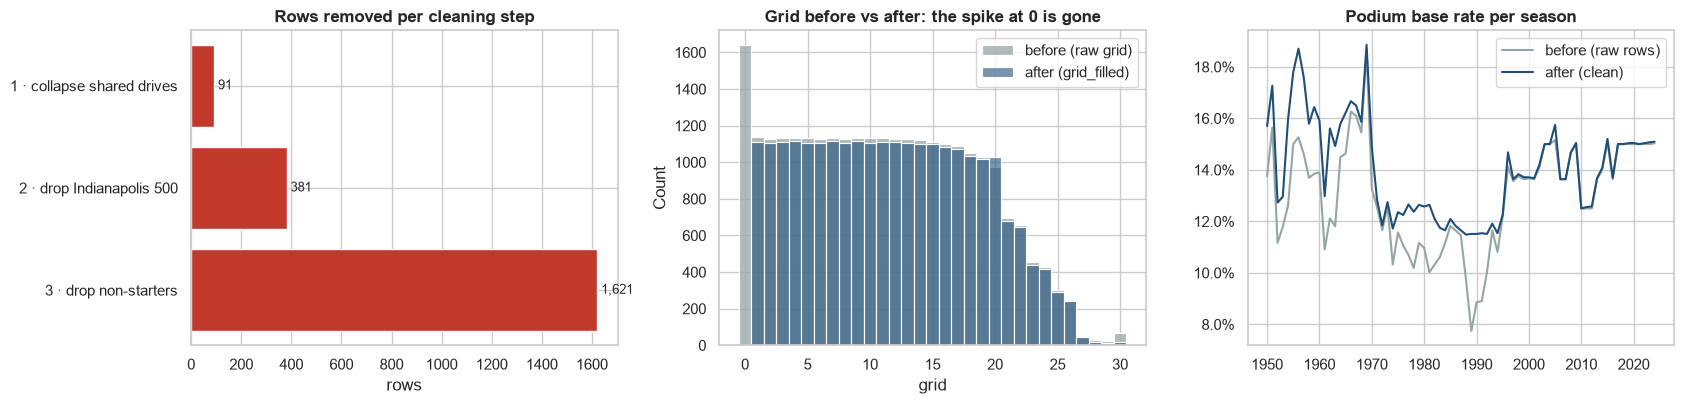

> 📝 **Logged (II · Cleaning)** — build_base(): 26,759 results rows → 24,666 driver-race starter rows; all 7 invariants pass.  
> ➜ *This table is the single backbone for the DE questions and features; raw CSVs untouched.*

In [305]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
steps = ledger[ledger.removed > 0]
axes[0].barh(steps.step, steps.removed, color="#c0392b"); axes[0].invert_yaxis()
for y, v in enumerate(steps.removed): axes[0].text(v, y, f" {v:,}", va="center", fontsize=9)
axes[0].set_title("Rows removed per cleaning step"); axes[0].set_xlabel("rows")

raw_res = df["results"].merge(df["races"][["raceId", "year"]], on="raceId")
sns.histplot(raw_res.grid.clip(upper=30), bins=31, discrete=True, ax=axes[1], color="#95a5a6", label="before (raw grid)")
sns.histplot(base.grid_filled.clip(upper=30), bins=31, discrete=True, ax=axes[1], color="#1f4e79", alpha=.6, label="after (grid_filled)")
axes[1].set_title("Grid before vs after: the spike at 0 is gone"); axes[1].legend(); axes[1].set_xlabel("grid")

(raw_res.assign(p=raw_res.positionOrder <= 3).groupby("year").p.mean()).plot(ax=axes[2], color="#95a5a6", label="before (raw rows)")
base.groupby("year").podium.mean().plot(ax=axes[2], color="#1f4e79", label="after (clean)")
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[2].set_title("Podium base rate per season"); axes[2].legend(); axes[2].set_xlabel("")
plt.tight_layout(); plt.show()
note("II · Cleaning",
     f"build_base(): {ledger['rows in'].iloc[0]:,} results rows → {len(base):,} driver-race starter rows; all {len(checks)} invariants pass.",
     "This table is the single backbone for the DE questions and features; raw CSVs untouched.")

---
---
# Part III — The three data-engineering questions

Each answer states its **grain** (what one row is), the **joins** (all multi-hop), how **missingness** was handled, and — where relevant — why it respects the **pre-race cutoff**.

## DE-Q1 · Which circuits convert a front-row start into a podium most often — and did the ranking change after 2014?

**Joins:** `results → races → circuits` (+ `qualifying` for the qualifying view). **Grain:** one row = one driver starting from the front row (grid 1–2) at one race. **Two definitions, kept apart as the brief asks:**
* **front-row *start*** = actual `grid` ∈ {1, 2} (after penalties) — available for all history;
* **front-row *qualifier*** = qualifying `position` ∈ {1, 2} — only where qualifying data exist (≈1994+), so that view is restricted to those seasons.

Periods: **pre-2014** vs **2014+** (hybrid era onward). Circuits need ≥ `MIN_FR` front-row starts in a period to be ranked — a circuit with 4 front-row starts and 4 podiums is not "100%", it's 4 races.

In [306]:
MIN_FR = 10
q1base = (base.merge(df["qualifying"][["raceId", "driverId", "position"]].drop_duplicates(["raceId", "driverId"]).rename(columns={"position": "quali_pos"}),
                     on=["raceId", "driverId"], how="left")
              .merge(circuits[["circuitId", "circuit", "circuit_country"]], on="circuitId", how="left"))
q1base["period"] = np.where(q1base.year >= 2014, "2014+", "pre-2014")

def conversion(rows, label):
    t = rows.groupby(["circuit", "period"]).agg(n=("podium", "size"), podiums=("podium", "sum")).reset_index()
    t["rate"] = t.podiums / t.n
    t["definition"] = label
    return t

fr_start = conversion(q1base[(q1base.grid.between(1, 2))], "front-row START (grid 1–2)")
fr_quali = conversion(q1base[(q1base.quali_pos.between(1, 2))], "front-row QUALIFIER (quali 1–2)")
wide = fr_start.pivot(index="circuit", columns="period", values=["rate", "n"])
both_periods = wide[(wide[("n", "pre-2014")] >= MIN_FR) & (wide[("n", "2014+")] >= MIN_FR)]
rho, rho_p = stats.spearmanr(both_periods[("rate", "pre-2014")], both_periods[("rate", "2014+")]) if len(both_periods) > 2 else (np.nan, np.nan)

print(f"Circuits ranked in both periods: {len(both_periods)} | Spearman rank correlation pre-2014 vs 2014+: {rho:.2f} (p = {rho_p:.3f})")

Circuits ranked in both periods: 16 | Spearman rank correlation pre-2014 vs 2014+: -0.03 (p = 0.909)


C:\Users\ahmed\AppData\Local\Temp\ipykernel_19316\474413438.py:31: UserWarning: Glyph 9670 (\N{BLACK DIAMOND}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
c:\Users\ahmed\OneDrive\Desktop\Uni\Semester 9\ACL\project\AI-Tools-Lab-F1-Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9670 (\N{BLACK DIAMOND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


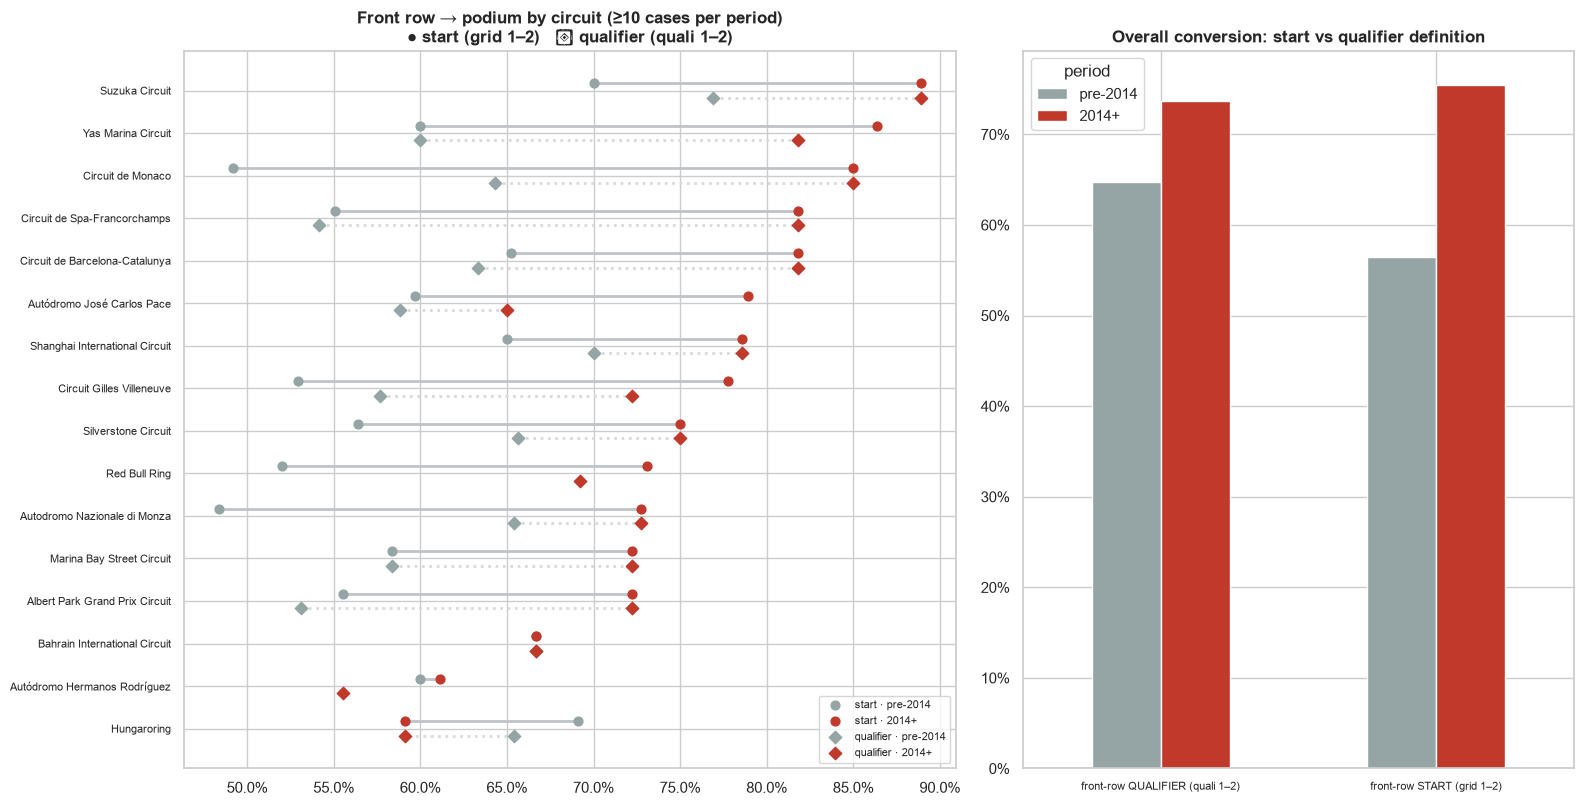

Front-row qualifiers who did NOT start from the front row (penalties etc.): 38 → their podium rate 28.9%


In [307]:
# Original dumbbell chart, plus a second line per circuit for the QUALIFIER definition
wq = fr_quali.pivot(index="circuit", columns="period", values=["rate", "n"])
bp = both_periods.copy()
bp.columns = [f"{a}_{b}" for a, b in bp.columns]
wq.columns = [f"q_{a}_{b}" for a, b in wq.columns]
bp = bp.join(wq).sort_values("rate_2014+")
y = np.arange(len(bp))
fig, axes = plt.subplots(1, 2, figsize=(16, max(4, .42 * len(bp) + 1.5)), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
# front-row START (grid 1–2): circles, upper line
ys = y + .17
ax.hlines(ys, bp["rate_pre-2014"], bp["rate_2014+"], color="#bdc3c7", lw=2)
ax.scatter(bp["rate_pre-2014"], ys, color="#95a5a6", s=40, marker="o", zorder=3, label="start · pre-2014")
ax.scatter(bp["rate_2014+"], ys, color="#c0392b", s=40, marker="o", zorder=3, label="start · 2014+")
# front-row QUALIFIER (quali 1–2): diamonds, lower line (only where ≥ MIN_FR cases)
yq = y - .17
qpre = bp["q_rate_pre-2014"].where(bp["q_n_pre-2014"] >= MIN_FR)
qpost = bp["q_rate_2014+"].where(bp["q_n_2014+"] >= MIN_FR)
ax.hlines(yq, qpre, qpost, color="#d6dbdf", lw=2, linestyles="dotted")
ax.scatter(qpre, yq, color="#95a5a6", s=40, marker="D", zorder=3, label="qualifier · pre-2014")
ax.scatter(qpost, yq, color="#c0392b", s=40, marker="D", zorder=3, label="qualifier · 2014+")
ax.set_yticks(y); ax.set_yticklabels(bp.index, fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"Front row → podium by circuit (≥{MIN_FR} cases per period)\n● start (grid 1–2)   ◆ qualifier (quali 1–2)")

comp = pd.concat([fr_start, fr_quali]).query("n >= @MIN_FR")
agg = comp.groupby(["definition", "period"]).apply(lambda d: d.podiums.sum() / d.n.sum()).unstack()
agg[["pre-2014", "2014+"]].plot.bar(ax=axes[1], color=["#95a5a6", "#c0392b"], rot=0)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].set_title("Overall conversion: start vs qualifier definition")
axes[1].set_xlabel(""); axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

lost = q1base[q1base.quali_pos.between(1, 2) & ~q1base.grid.between(1, 2)]
print(f"Front-row qualifiers who did NOT start from the front row (penalties etc.): {len(lost)} "
      f"→ their podium rate {pct(lost.podium.mean()) if len(lost) else 'n/a'}")

In [308]:
# The written answer, generated from the numbers above
def top(per, defn_df, k=5):
    t = defn_df[(defn_df.period == per) & (defn_df.n >= MIN_FR)].sort_values(["rate", "n"], ascending=False)
    return t.head(k)
t_pre, t_post = top("pre-2014", fr_start), top("2014+", fr_start)
overlap = len(set(t_pre.circuit) & set(t_post.circuit))
# Compare circuits WITHIN each period. Pooling all seasons would favour circuits that mostly raced after 2014,
# when front-row conversion was higher everywhere (era confounding / Simpson's paradox).
per_rate = both_periods["rate"][["pre-2014", "2014+"]]
period_avg = per_rate.mean(axis=1)          # each period weighted equally
best_all = period_avg.idxmax()
best_pre, best_post = per_rate["pre-2014"].idxmax(), per_rate["2014+"].idxmax()
stable = (rho >= .5) and (rho_p < .05)
fmt = lambda t: ", ".join(f"{c} ({r:.0%}, n={n})" for c, r, n in zip(t.circuit, t.rate, t.n))
display(Markdown(f'''
### ✅ Answer to DE-Q1
* **Best converter:** **{best_all}**: {per_rate.loc[best_all, "pre-2014"]:.0%} before 2014 and {per_rate.loc[best_all, "2014+"]:.0%} from 2014 (average of the two periods {period_avg[best_all]:.0%}). {"It is #1 in **both** periods." if best_pre == best_post == best_all else f"#1 before 2014: {best_pre}; #1 from 2014: {best_post}."}
* *Why not pool all seasons?* Front-row conversion rose for everyone after 2014 ({pct(fr_start[fr_start.period=="pre-2014"].podiums.sum()/fr_start[fr_start.period=="pre-2014"].n.sum())} → {pct(fr_start[fr_start.period=="2014+"].podiums.sum()/fr_start[fr_start.period=="2014+"].n.sum())}), so a pooled rate rewards circuits that mostly raced after 2014 (e.g. newer circuits) rather than circuits that convert better. Comparing within each period avoids that.
* **Top 5 before 2014:** {fmt(t_pre)}.
* **Top 5 from 2014:** {fmt(t_post)}.
* **Did the ranking change after 2014?** {overlap} of the 5 circuits are in both top-5 lists, and the rank correlation between the two periods over all {len(both_periods)} circuits is ρ = {rho:.2f} (p = {rho_p:.3f}).
  **{"The ranking was largely preserved: circuits that converted well before 2014 still do." if stable else "There is no strong evidence the order carried over. With only 10–40 front-row starts per circuit and period, a single podium moves a rate by several points, so the per-circuit ranking is noisy."}**
* **Start vs qualifier:** {len(lost)} drivers qualified on the front row but started further back (grid penalties). That is why the brief keeps the two definitions apart. The overall conversion is {pct(fr_start.podiums.sum() / fr_start.n.sum())} for front-row *starters* vs {pct(fr_quali.podiums.sum() / fr_quali.n.sum())} for front-row *qualifiers*.
'''))
note("III · DE-Q1",
     f"Best (within-period comparison): {best_all}; #1 pre-2014 {best_pre}, #1 2014+ {best_post}. Top-5 overlap pre/post 2014 = {overlap}/5; ρ = {rho:.2f} (p = {rho_p:.3f}) → {'ranking preserved' if stable else 'no strong evidence the ranking carried over'}.",
     "Answer DE-Q1 with the dumbbell chart (start + qualifier lines) and the written answer cell.")


### ✅ Answer to DE-Q1
* **Best converter:** **Suzuka Circuit**: 70% before 2014 and 89% from 2014 (average of the two periods 79%). It is #1 in **both** periods.
* *Why not pool all seasons?* Front-row conversion rose for everyone after 2014 (56.4% → 76.0%), so a pooled rate rewards circuits that mostly raced after 2014 (e.g. newer circuits) rather than circuits that convert better. Comparing within each period avoids that.
* **Top 5 before 2014:** Circuit de Nevers Magny-Cours (81%, n=36), Indianapolis Motor Speedway (79%, n=14), Istanbul Park (79%, n=14), Dijon-Prenois (75%, n=12), Suzuka Circuit (70%, n=50).
* **Top 5 from 2014:** Suzuka Circuit (89%, n=18), Yas Marina Circuit (86%, n=22), Circuit de Monaco (85%, n=20), Circuit de Barcelona-Catalunya (82%, n=22), Circuit de Spa-Francorchamps (82%, n=22).
* **Did the ranking change after 2014?** 1 of the 5 circuits are in both top-5 lists, and the rank correlation between the two periods over all 16 circuits is ρ = -0.03 (p = 0.909).
  **There is no strong evidence the order carried over. With only 10–40 front-row starts per circuit and period, a single podium moves a rate by several points, so the per-circuit ranking is noisy.**
* **Start vs qualifier:** 38 drivers qualified on the front row but started further back (grid penalties). That is why the brief keeps the two definitions apart. The overall conversion is 60.4% for front-row *starters* vs 69.0% for front-row *qualifiers*.


> 📝 **Logged (III · DE-Q1)** — Best (within-period comparison): Suzuka Circuit; #1 pre-2014 Suzuka Circuit, #1 2014+ Suzuka Circuit. Top-5 overlap pre/post 2014 = 1/5; ρ = -0.03 (p = 0.909) → no strong evidence the ranking carried over.  
> ➜ *Answer DE-Q1 with the dumbbell chart (start + qualifier lines) and the written answer cell.*

**Missingness & cutoff for Q1.** The grid-based view uses every season (grid is always recorded for starters); the qualifying view silently covers only seasons with qualifying data, so it is shown separately rather than mixed. Both grid and qualifying position are known before lights out; the podium is the outcome being described, which is fine here because this is an analytical question, not a feature.

## DE-Q2 · Do drivers podium more often at home, after controlling for starting position?

**Joins:** `results → drivers` (nationality) and `results → races → circuits` (country), linked by the hand-built `NAT2COUNTRY` map (Clue 11). **Grain:** one row = one starter at one race.

### Why a test is needed at all
Comparing "home podium rate" with "away podium rate" is unfair. If home drivers happen to drive better cars, they start further forward and podium more **because of the grid, not because of home**. So we compare like with like: home vs away drivers **who started from the same part of the grid**. That is what "controlling for starting position" means.

### The vocabulary, in plain words
* **Odds** = P(podium) ÷ P(no podium). A 20% podium chance is odds of 0.20/0.80 = **0.25** ("1 to 4").
* **Odds ratio (OR)** = odds for home drivers ÷ odds for away drivers.
  **OR = 1** → no difference. **OR = 1.5** → home drivers' odds are 50% higher. **OR = 0.8** → 20% lower.
* **95% confidence interval (CI)**: the range of OR values compatible with the data. **If it contains 1, we cannot rule out "no home effect".**
* **p-value**: if there were truly *no* home effect, the probability of seeing a difference at least this large just by chance. **p < 0.05** is the usual threshold for calling it "significant".

### The two tests
1. **Cochran–Mantel–Haenszel (CMH).** Split the starters into grid bands (P1, P2–3, P4–6, …). Inside each band, build a small 2×2 table: home/away × podium/no podium. Each band gives its own odds ratio, and CMH **averages them into one OR, weighting bands by how much data they have**. Because every comparison happens inside a band, grid position can't create a fake home effect.
2. **Logistic regression.** A model of `podium ~ home + grid band + era`. The coefficient on `home`, turned into an odds ratio, is the home effect **holding grid band and era fixed**. Same idea as CMH, but it can control for era too. Its standard errors are **clustered by driver**: the same driver appears in hundreds of races, so rows aren't independent and ordinary errors would be too optimistic.

If both tests agree, the answer is robust to how we control for grid.

grid band,home starts,home podium rate,away starts,away podium rate,OR,lo,hi
P1,81,60.5%,"1,031",64.8%,0.83,0.52,1.32
P2–3,148,55.4%,"2,069",51.1%,1.19,0.85,1.66
P4–6,224,27.2%,"3,102",26.2%,1.06,0.78,1.43
P7–10,335,7.5%,"4,102",9.4%,0.78,0.51,1.19
P11–15,415,2.7%,"5,114",3.0%,0.88,0.47,1.63
P16+,736,0.3%,"7,309",0.7%,0.37,0.09,1.53


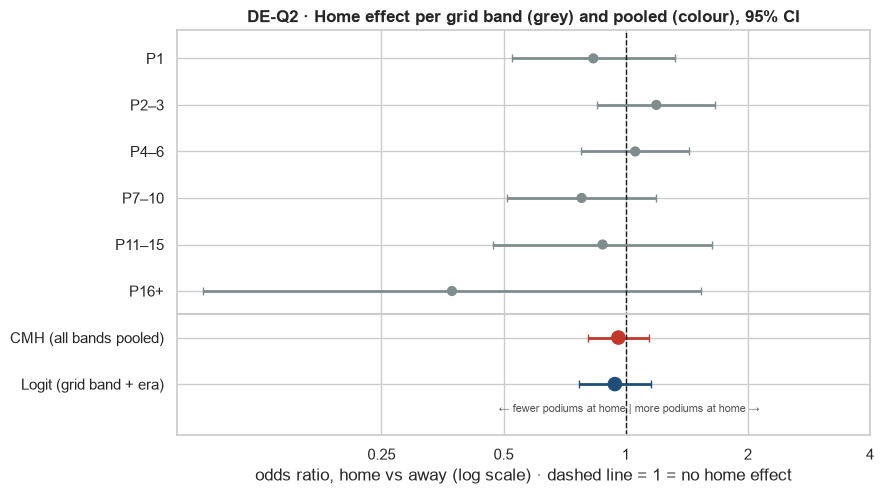

In [309]:
q2 = base.merge(drivers[["driverId", "nationality"]], on="driverId").merge(circuits[["circuitId", "circuit_country"]], on="circuitId")
q2["home"] = (q2.nationality.map(NAT2COUNTRY) == q2.circuit_country.replace(COUNTRY_ALIASES)).astype(int)
BANDS = ["P1", "P2–3", "P4–6", "P7–10", "P11–15", "P16+"]
q2["grid_band"] = pd.cut(q2.grid_filled, [0, 1, 3, 6, 10, 15, 100], labels=BANDS).astype(str)
q2["era"] = q2.year.map(era_of)

# Step 1: the comparison per grid band (what CMH pools)
rows, tabs = [], []
for b in BANDS:
    d = q2[q2.grid_band == b]
    t = pd.crosstab(d.home, d.podium).reindex(index=[1, 0], columns=[1, 0], fill_value=0)
    if t.values.sum(axis=1).min() == 0: continue
    tabs.append(t.values)
    tt = Table2x2(t.values, shift_zeros=True)
    rows.append({"grid band": b, "home starts": int(t.loc[1].sum()), "home podium rate": t.loc[1, 1] / t.loc[1].sum(),
                 "away starts": int(t.loc[0].sum()), "away podium rate": t.loc[0, 1] / t.loc[0].sum(),
                 "OR": tt.oddsratio, "lo": tt.oddsratio_confint()[0], "hi": tt.oddsratio_confint()[1]})
per_band = pd.DataFrame(rows)
display(per_band.style.format({"home podium rate": "{:.1%}", "away podium rate": "{:.1%}", "OR": "{:.2f}", "lo": "{:.2f}", "hi": "{:.2f}",
                               "home starts": "{:,}", "away starts": "{:,}"}).hide(axis="index"))

# Step 2: the two tests
st2 = StratifiedTable(tabs, shift_zeros=True)
cmh_p = st2.test_null_odds(correction=True).pvalue
cmh_lo, cmh_hi = st2.oddsratio_pooled_confint()
homog_p = st2.test_equal_odds().pvalue
m2 = smf.logit("podium ~ home + C(grid_band) + C(era)", data=q2).fit(disp=0, cov_type="cluster", cov_kwds={"groups": q2.driverId})
or2, (lo2, hi2) = np.exp(m2.params["home"]), np.exp(m2.conf_int().loc["home"])

# Forest plot: each band's OR, then the two pooled answers
fp = pd.concat([per_band[["grid band", "OR", "lo", "hi"]].rename(columns={"grid band": "label"}),
                pd.DataFrame({"label": ["CMH (all bands pooled)", "Logit (grid band + era)"], "OR": [st2.oddsratio_pooled, or2],
                              "lo": [cmh_lo, lo2], "hi": [cmh_hi, hi2]})], ignore_index=True)
fig, ax = plt.subplots(figsize=(9, .45 * len(fp) + 1.5))
y = np.arange(len(fp))[::-1]
colors = ["#7f8c8d"] * len(per_band) + ["#c0392b", "#1f4e79"]
for yi, (o, l, h, col) in enumerate(zip(fp.OR, fp.lo, fp.hi, colors)):
    ax.errorbar(o, y[yi], xerr=[[o - l], [h - o]], fmt="none", ecolor=col, elinewidth=2, capsize=3)
ax.scatter(fp.OR, y, c=colors, s=[40] * len(per_band) + [90, 90], zorder=3)
ax.axvline(1, color="k", ls="--", lw=1); ax.text(1.02, -.6, "← fewer podiums at home | more podiums at home →", ha="center", fontsize=8, color="#555")
ax.axhline(len(fp) - len(per_band) - .5, color="#ccc")
ax.set_yticks(y); ax.set_yticklabels(fp.label); ax.set_xscale("log")
ax.set_xticks([.25, .5, 1, 2, 4]); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(mtick.NullFormatter()); ax.set_ylim(-1.1, len(fp) - .4)
ax.set_xlabel("odds ratio, home vs away (log scale) · dashed line = 1 = no home effect")
ax.set_title("DE-Q2 · Home effect per grid band (grey) and pooled (colour), 95% CI")
plt.tight_layout(); plt.show()

In [310]:
sig = lo2 > 1 or hi2 < 1
verdict2 = "home advantage" if lo2 > 1 else "home disadvantage" if hi2 < 1 else "no significant home effect"
display(Markdown(f'''
### ✅ Answer to DE-Q2
* **Raw rates (unfair comparison):** home {pct(q2[q2.home == 1].podium.mean())} vs away {pct(q2[q2.home == 0].podium.mean())} podium rate, from {q2.home.sum():,} home starts.
* **CMH, controlling for grid band:** OR = **{st2.oddsratio_pooled:.2f}** (95% CI {cmh_lo:.2f}–{cmh_hi:.2f}, p = {cmh_p:.3f}).
* **Logistic regression, controlling for grid band and era:** OR = **{or2:.2f}** (95% CI {lo2:.2f}–{hi2:.2f}, p = {m2.pvalues["home"]:.3f}).
* **In words:** from the same part of the grid, a driver racing at home has **{or2:.2f}×** the odds of a podium of a driver racing away.
  {"The interval excludes 1 and p < 0.05, so this difference is statistically significant." if sig else "The interval includes 1 and p > 0.05, so the data are compatible with no home effect at all: **we find no evidence of a home advantage** once grid position is accounted for."}
* **Is the effect the same in every band?** Homogeneity test p = {homog_p:.3f}: {"no evidence it differs between bands, so one pooled number is fair." if homog_p > .05 else "the effect differs between bands; look at the per-band rows above."}
* **Caveat:** this is an association, not causation. Nationality is also a rough proxy for "home": a Monegasque driver in Monaco is home, but so is a British driver at Silverstone with a very different crowd effect.
'''))
note("III · DE-Q2", f"Adjusted OR = {or2:.2f} (95% CI {lo2:.2f}–{hi2:.2f}, p = {m2.pvalues['home']:.3f}); CMH OR = {st2.oddsratio_pooled:.2f} → {verdict2}.",
     "Report the adjusted odds ratio with its CI; association, not causation.")


### ✅ Answer to DE-Q2
* **Raw rates (unfair comparison):** home 11.9% vs away 13.8% podium rate, from 1,939 home starts.
* **CMH, controlling for grid band:** OR = **0.96** (95% CI 0.81–1.14, p = 0.670).
* **Logistic regression, controlling for grid band and era:** OR = **0.94** (95% CI 0.77–1.15, p = 0.552).
* **In words:** from the same part of the grid, a driver racing at home has **0.94×** the odds of a podium of a driver racing away.
  The interval includes 1 and p > 0.05, so the data are compatible with no home effect at all: **we find no evidence of a home advantage** once grid position is accounted for.
* **Is the effect the same in every band?** Homogeneity test p = 0.392: no evidence it differs between bands, so one pooled number is fair.
* **Caveat:** this is an association, not causation. Nationality is also a rough proxy for "home": a Monegasque driver in Monaco is home, but so is a British driver at Silverstone with a very different crowd effect.


> 📝 **Logged (III · DE-Q2)** — Adjusted OR = 0.94 (95% CI 0.77–1.15, p = 0.552); CMH OR = 0.96 → no significant home effect.  
> ➜ *Report the adjusted odds ratio with its CI; association, not causation.*

## DE-Q3 · Which constructors have the highest mechanical-retirement rate, 2014–21 vs 2022–24?

**Joins:** `results → status` (mapped to categories in Clue 5) `→ constructors`, `→ races` for the year. **Grain:** one row = one car starting one race (a *start*). **Rate** = mechanical retirements ÷ starts. Non-starters are already excluded by cleaning (a car that never started can't break down in the race). Crashes, driver errors, disqualifications are *not* mechanical, per the brief's definition.

Two refinements make the answer defensible: **Wilson 95% intervals** (a rate from 40 starts is less certain than one from 300) and a **sensitivity check** where the ambiguous statuses (tyre, "Retired", damage…) are counted as mechanical — if the top of the ranking doesn't move, the answer doesn't hinge on our mapping.

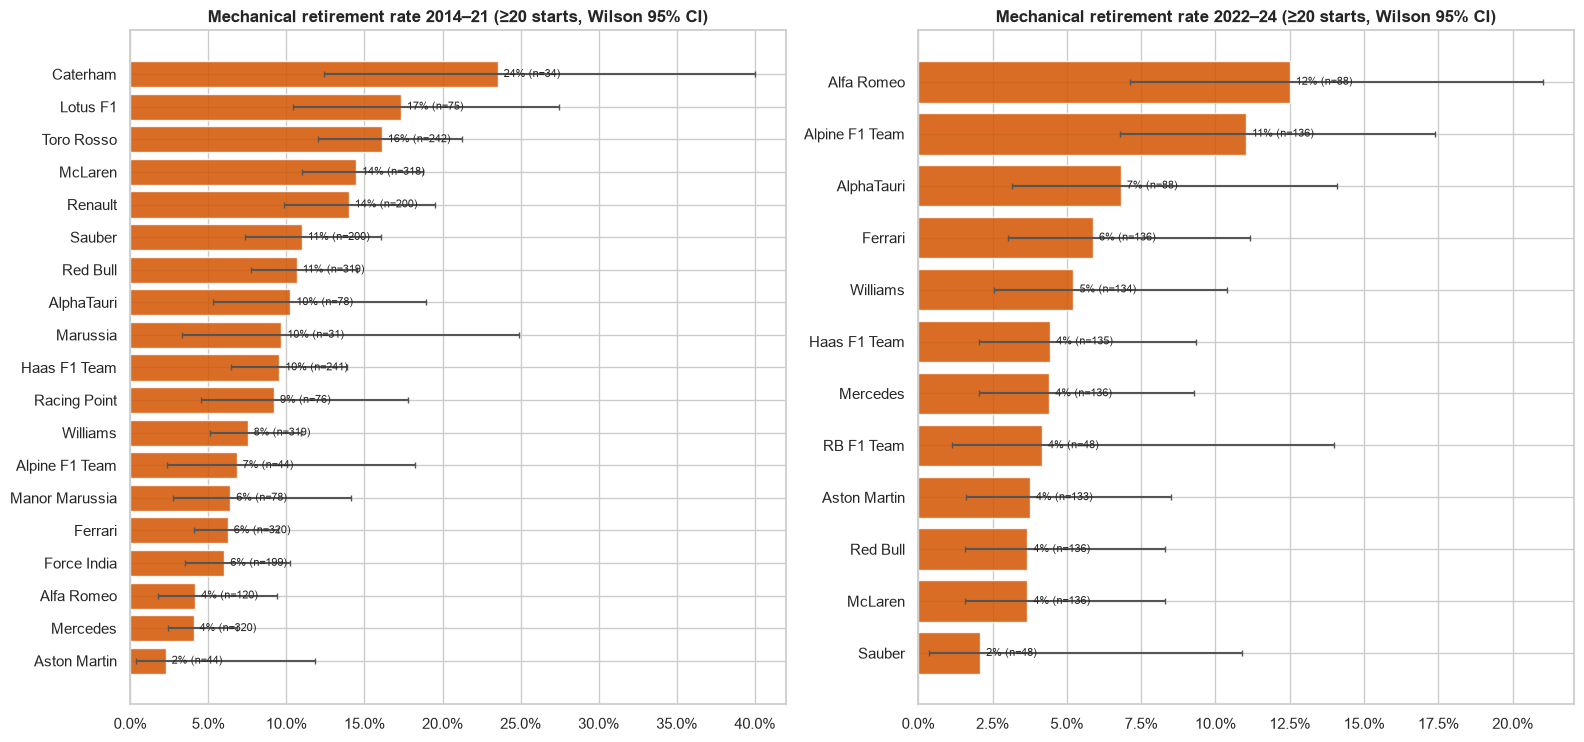

,top-3 (strict mapping),top-3 (ambiguous counted as mechanical),Spearman of the two rankings
2014–21,"Caterham, Lotus F1, Toro Rosso","Caterham, Lotus F1, Toro Rosso",0.97193
2022–24,"Alfa Romeo, Alpine F1 Team, AlphaTauri","Alfa Romeo, Alpine F1 Team, RB F1 Team",0.7


Constructors present in both periods: 11; overall mechanical rate 9.6% (2014–21) vs 5.7% (2022–24)


In [311]:
from statsmodels.stats.proportion import proportion_confint
q3 = base.merge(constructors[["constructorId", "constructor"]], on="constructorId")
MIN_STARTS = 20

def mech_table(lo, hi, include_ambiguous=False):
    d = q3[q3.year.between(lo, hi)]
    mech = d.status_cat.eq("mechanical") | (include_ambiguous & d.status_cat.eq("ambiguous"))
    t = d.assign(mech=mech).groupby("constructor").agg(starts=("mech", "size"), mech=("mech", "sum"))
    t = t[t.starts >= MIN_STARTS].copy()
    t["rate"] = t.mech / t.starts
    t["lo"], t["hi"] = proportion_confint(t.mech, t.starts, method="wilson")
    return t.sort_values("rate", ascending=False)

periods = {"2014–21": (2014, 2021), "2022–24": (2022, 2024)}
T = {p: mech_table(*r) for p, r in periods.items()}
T_amb = {p: mech_table(*r, include_ambiguous=True) for p, r in periods.items()}

fig, axes = plt.subplots(1, 2, figsize=(16, max(5, .32 * max(len(t) for t in T.values()) + 1.5)))
for ax, (p, t) in zip(axes, T.items()):
    if len(t) == 0: ax.set_title(f"{p}: no constructor with ≥{MIN_STARTS} starts"); continue
    t = t.sort_values("rate")
    ax.barh(t.index, t.rate, xerr=[t.rate - t.lo, t.hi - t.rate], color="#d35400", alpha=.85, ecolor="#555", capsize=2)
    for y, (r, n) in enumerate(zip(t.rate, t.starts)): ax.text(r, y, f"  {r:.0%} (n={n})", va="center", fontsize=8)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title(f"Mechanical retirement rate {p} (≥{MIN_STARTS} starts, Wilson 95% CI)")
plt.tight_layout(); plt.show()

sens = pd.DataFrame({p: {"top-3 (strict mapping)": ", ".join(T[p].index[:3]), "top-3 (ambiguous counted as mechanical)": ", ".join(T_amb[p].index[:3]),
                         "Spearman of the two rankings": stats.spearmanr(T[p].rate, T_amb[p].reindex(T[p].index).rate)[0] if len(T[p]) > 2 else np.nan}
                     for p in periods}).T
display(sens)
common = T["2014–21"].index.intersection(T["2022–24"].index)
print(f"Constructors present in both periods: {len(common)}; overall mechanical rate "
      f"{pct(q3[q3.year.between(2014, 2021)].status_cat.eq('mechanical').mean())} (2014–21) vs {pct(q3[q3.year.between(2022, 2024)].status_cat.eq('mechanical').mean())} (2022–24)")

In [312]:
note("III · DE-Q3",
     "Top mechanical-retirement rates: 2014–21 → " + ", ".join(f"{c} {r:.0%}" for c, r in T["2014–21"].rate.head(3).items())
     + "; 2022–24 → " + ", ".join(f"{c} {r:.0%}" for c, r in T["2022–24"].rate.head(3).items()) + ".",
     "Report with Wilson CIs and the sensitivity table; renamed teams (e.g. Renault→Alpine) appear as separate constructors by design.")

> 📝 **Logged (III · DE-Q3)** — Top mechanical-retirement rates: 2014–21 → Caterham 24%, Lotus F1 17%, Toro Rosso 16%; 2022–24 → Alfa Romeo 12%, Alpine F1 Team 11%, AlphaTauri 7%.  
> ➜ *Report with Wilson CIs and the sensitivity table; renamed teams (e.g. Renault→Alpine) appear as separate constructors by design.*

---
---
# Part IV — Feature engineering, selection and the split

**Rule for every feature:** it must be computable **after qualifying, before lights out**. Allowed sources: the current race's grid and qualifying; anything from *earlier* races; static facts about drivers, teams and circuits. Features come in six groups — the same groups the ablation will remove later.

| Group | Features | Why it should matter (hypothesis from EDA) |
|---|---|---|
| **grid** | `grid_filled`, `pit_lane_start`, `field_size` | strongest single signal (Clue 7) |
| **qualifying** | `quali_pos`, `has_quali`, `session_reached`, `q1_gap_pct`, `grid_minus_quali` | pace and penalties; partly redundant with grid (Clue 6) |
| **standings** | before-race standing position, points *share* of leader, wins — driver and constructor; `is_first_round` | season-long strength without leakage (Clue 8) |
| **driver form** | last-5 podium rate & finish percentile, career podium rate, `drv_starts_before` | recent and long-run driver ability (Clue 9) |
| **constructor form** | last-5 podium rate & best finish percentile, last-10 mechanical-failure rate | car performance + reliability (Clues 9–10) |
| **time & experience** | `driver_age`, `years_in_f1`, `races_with_team`, `days_since_last_race`, `season_progress` | features *derived from dates* (see below) |
| **context** | `home` | home effect (Clue 11, DE-Q2) |

### Why derive features from dates, and why the raw date itself is not a feature
Dates are one of the richest sources of pre-race information, as long as we turn them into **quantities that mean the same thing in every era**:
* `driver_age`: age on race day (from `dob`).
* `years_in_f1`: years since the driver's first championship race (experience).
* `races_with_team`: starts with the current constructor so far (how settled the driver is in this car).
* `days_since_last_race`: gap since the driver's previous start (rust after injury, a sabbatical, or a mid-season replacement).
* `season_progress`: `round ÷ rounds in the season` (0 = opener, 1 = finale). Early-season races are less predictable before the pecking order settles. The calendar is published before the season, so this is known pre-race. 2020's calendar was rebuilt mid-season, which is a small caveat.

The raw `date` or `year` is **deliberately left out**. Our split is by time, so every test year (2022+) lies *outside* the range the model trained on (≤2019). A tree model treats any year > 2019 like 2019, and a linear model extrapolates a trend that may not exist. Era effects are better captured through comparable features like field size, points share and form. Month and day-of-week are also left out: in F1 they mostly encode *which circuit* it is, not anything about the driver.

Two design choices worth defending:
* **Points share, not raw points.** The points system changed many times (a win was worth 8 → 9 → 10 → 25 points), so 50 points means different things in 1980 and 2020. *Share of the leader's points* is comparable across eras.
* **Finish percentile, not finish position.** 10th of 30 and 10th of 20 are different results; `rank / field size` fixes that.

**One qualifying feature changes meaning in 2006.** `session_reached` (1 = out in Q1, 2 = out in Q2, 3 = reached Q3) only exists since knockout qualifying started in 2006. Before that everyone, the pole sitter included, would get a 1. On training data a "1" means a 13.6% podium rate before 2006 and 1.1% after. The feature is therefore set to **missing before 2006**, and `F1Prep` adds a `session_reached_missing` indicator. That indicator acts as the "pre-knockout era" flag: the model learns a separate effect for those rows instead of reading them as Q1 eliminations. (2005's two aggregate sessions also leave `q2` filled for 28% of rows; the same rule covers it.)

In [313]:
W = 5
KNOCKOUT_START = 2006   # first season of Q1/Q2/Q3 knockout qualifying
def build_features(base, df, history=None, W=W):
    # base: rows to featurize. history: rows used to compute past-race form (default: base itself).
    Hh = (history if history is not None else base).copy()
    Hh["finish_pct"] = Hh.groupby("raceId").positionOrder.rank(pct=True)
    Hh["is_mech"] = Hh.status_cat.eq("mechanical").astype(float)
    Hh = Hh.sort_values(["date", "raceId"])
    g = Hh.groupby("driverId")
    roll = lambda s, w=W: s.shift(1).rolling(w, min_periods=1).mean()   # shift FIRST: current race never included
    Hh["drv_form_podium"] = g.podium.transform(roll)
    Hh["drv_form_finish_pct"] = g.finish_pct.transform(roll)
    Hh["drv_career_podium_rate"] = g.podium.transform(lambda s: s.shift(1).expanding().mean())
    Hh["drv_starts_before"] = g.cumcount()
    # date-derived (only past dates used)
    Hh["days_since_last_race"] = (Hh.date - g.date.shift(1)).dt.days
    Hh["years_in_f1"] = (Hh.date - g.date.transform("min")).dt.days / 365.25
    Hh["races_with_team"] = Hh.groupby(["driverId", "constructorId"]).cumcount()
    # constructor features at constructor-race grain, so a teammate's result in the SAME race can't leak in
    cr = (Hh.groupby(["constructorId", "raceId"], as_index=False)
            .agg(date=("date", "first"), c_podium=("podium", "max"), c_finish=("finish_pct", "min"), c_mech=("is_mech", "mean"))
            .sort_values(["date", "raceId"]))
    gc = cr.groupby("constructorId")
    cr["con_form_podium"] = gc.c_podium.transform(roll)
    cr["con_form_finish_pct"] = gc.c_finish.transform(roll)
    cr["con_mech_rate_prev"] = gc.c_mech.transform(lambda s: roll(s, 2 * W))

    X = (base.merge(Hh[["raceId", "driverId", "drv_form_podium", "drv_form_finish_pct", "drv_career_podium_rate", "drv_starts_before",
                        "days_since_last_race", "years_in_f1", "races_with_team"]],
                    on=["raceId", "driverId"], how="left")
             .merge(cr[["constructorId", "raceId", "con_form_podium", "con_form_finish_pct", "con_mech_rate_prev"]],
                    on=["constructorId", "raceId"], how="left"))

    # qualifying (current race, known at the cutoff)
    q = df["qualifying"][["raceId", "driverId", "position", "q1", "q2", "q3"]].drop_duplicates(["raceId", "driverId"]).rename(columns={"position": "quali_pos"})
    X = X.merge(q, on=["raceId", "driverId"], how="left")
    X["has_quali"] = X.quali_pos.notna().astype(int)
    X["session_reached"] = np.select([X.q3.notna(), X.q2.notna(), X.quali_pos.notna()], [3, 2, 1], 0)
    X["session_reached"] = X.session_reached.where(X.year >= KNOCKOUT_START)   # Q2/Q3 did not exist before 2006: not applicable, not "out in Q1"
    X["q1_gap_pct"] = (100 * (X.q1 / X.groupby("raceId").q1.transform("min") - 1)).clip(upper=20)
    X["grid_minus_quali"] = X.grid_filled - X.quali_pos

    # standings BEFORE this race (merge_asof on round, strictly earlier)
    def before_race(tab, ent, prefix):
        t = tab.merge(df["races"][["raceId", "year", "round"]], on="raceId")
        t["leader_pts"] = t.groupby("raceId").points.transform("max")
        t = t[["year", "round", ent, "position", "points", "wins", "leader_pts"]].sort_values("round")
        t.columns = ["year", "round", ent] + [f"{prefix}_{c}" for c in ["pos", "pts", "wins", "leader"]]
        out = pd.merge_asof(X[["raceId", ent, "year", "round"]].drop_duplicates().sort_values("round"), t, on="round", by=["year", ent],
                            allow_exact_matches=False, direction="backward")
        out[f"{prefix}_pts_share"] = np.where(out[f"{prefix}_leader"] > 0, out[f"{prefix}_pts"] / out[f"{prefix}_leader"], 0.0)
        return out.drop(columns=["year", "round", f"{prefix}_pts", f"{prefix}_leader"])
    X = X.merge(before_race(df["driver_standings"], "driverId", "prev_standing"), on=["raceId", "driverId"], how="left")
    X = X.merge(before_race(df["constructor_standings"], "constructorId", "con_prev_standing"), on=["raceId", "constructorId"], how="left")
    X = X.drop(columns=["con_prev_standing_wins"])
    # Old standings tables (mostly pre-2010) list only drivers/teams that have scored, so a missing entry after round 1 means
    # "0 points so far": place them behind every listed entry in this race. Round 1 stays missing (no table yet; is_first_round flags it).
    for c in ["prev_standing_pos", "con_prev_standing_pos"]:
        X[c] = X[c].where(X[c].notna() | (X["round"] == 1), X.groupby("raceId")[c].transform("max") + 1)
    X["is_first_round"] = (X["round"] == 1).astype(int)

    # context
    dv = df["drivers"][["driverId", "nationality", "dob"]]
    ci = df["circuits"][["circuitId", "country"]]
    X = X.merge(dv, on="driverId", how="left").merge(ci, on="circuitId", how="left")
    X["home"] = (X.nationality.map(NAT2COUNTRY) == X.country.replace(COUNTRY_ALIASES)).astype(int)
    X["driver_age"] = (X.date - X.dob).dt.days / 365.25
    rounds = df["races"].groupby("year")["round"].max().rename("rounds_in_season")
    X = X.merge(rounds, left_on="year", right_index=True, how="left")
    X["season_progress"] = X["round"] / X.rounds_in_season
    return X

FX = build_features(base, df)
assert len(FX) == len(base) and not FX.duplicated(["raceId", "driverId"]).any(), "feature joins changed the grain"

GROUPS = {
    "grid": ["grid_filled", "pit_lane_start", "field_size"],
    "qualifying": ["quali_pos", "has_quali", "session_reached", "q1_gap_pct", "grid_minus_quali"],
    "standings": ["prev_standing_pos", "prev_standing_pts_share", "prev_standing_wins", "con_prev_standing_pos", "con_prev_standing_pts_share", "is_first_round"],
    "driver_form": ["drv_form_podium", "drv_form_finish_pct", "drv_career_podium_rate", "drv_starts_before"],
    "constructor_form": ["con_form_podium", "con_form_finish_pct", "con_mech_rate_prev"],
    "time_experience": ["driver_age", "years_in_f1", "races_with_team", "days_since_last_race", "season_progress"],
    "context": ["home"],
}
ALL_FEATS = [f for g in GROUPS.values() for f in g]
BANNED = {"points", "laps", "time", "milliseconds", "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status",
          "status_cat", "position", "positionText", "positionOrder", "best_positionOrder", "total_points", "podium"}
assert not set(ALL_FEATS) & BANNED, "a post-race column slipped into the feature list"
print(f"{len(ALL_FEATS)} candidate features in {len(GROUPS)} groups for {len(FX):,} rows; banned-column check ✅")

27 candidate features in 7 groups for 24,666 rows; banned-column check ✅


**Alibi tests for the new features.** Two automated checks that no feature peeks at the current race: (1) recompute constructor form by hand from the team's *earlier* races; (2) confirm that before-race standings never equal the post-race standings of the same race for the round leader (they'd only match if we'd leaked the current race).

In [314]:
rng_rows = FX[FX.drv_starts_before >= 2 * W].sample(min(150, (FX.drv_starts_before >= 2 * W).sum()), random_state=7)
cr_hand = base.assign(finish_pct=base.groupby("raceId").positionOrder.rank(pct=True)).groupby(["constructorId", "raceId"]).agg(date=("date", "first"), c_podium=("podium", "max"))
mism_c = 0
for _, row in rng_rows.iterrows():
    past = cr_hand.loc[row.constructorId]
    past = past[past.date < row.date].sort_values("date").tail(W)
    if len(past) and not np.isclose(past.c_podium.mean(), row.con_form_podium): mism_c += 1
print(f"Constructor-form alibi: {mism_c} mismatches in {len(rng_rows)} rows", "✅" if mism_c == 0 else "❌")
# Standings alibi: for round r, the feature must equal the standings published after round r-1 (not after round r).
ds_r = (df["driver_standings"].merge(df["races"][["raceId", "year", "round"]], on="raceId")[["year", "round", "driverId", "position"]]
        .rename(columns={"position": "pos_after_prev_round"}).assign(round=lambda d: d["round"] + 1))
chk = FX[FX["round"] > 1].merge(ds_r, on=["year", "round", "driverId"], how="inner")
print(f"Standings alibi: before-race position equals the table after the PREVIOUS round in {pct((chk.prev_standing_pos == chk.pos_after_prev_round).mean())} "
      f"of {len(chk):,} checkable rows", "✅" if (chk.prev_standing_pos == chk.pos_after_prev_round).all() else "❌")

Constructor-form alibi: 0 mismatches in 150 rows ✅
Standings alibi: before-race position equals the table after the PREVIOUS round in 100.0% of 21,754 checkable rows ✅


## The split
Chronological, as the brief proposes: **train ≤ 2019 · validation 2020–21 · test ≥ 2022**. Why not random? A random split would put 2023 races in training and 2010 races in test, letting the model learn from the future (e.g. a driver's later dominance) — exactly the leakage the cutoff forbids, just at season level. Chronological splitting is also the honest deployment scenario: train on the past, predict the next season.

Form features for a 2022 race use 2021 and earlier results. That is legitimate: those races happened before the prediction, the model never sees 2022 *labels* in training.

In [315]:
FX["split"] = np.select([FX.year <= 2019, FX.year <= 2021], ["train", "val"], "test")
split_tab = FX.groupby("split").agg(seasons=("year", lambda s: f"{s.min()}–{s.max()}"), races=("raceId", "nunique"), rows=("podium", "size"),
                                    podiums=("podium", "sum"), podium_rate=("podium", "mean")).reindex(["train", "val", "test"])
display(split_tab.style.format({"rows": "{:,}", "podiums": "{:,}", "podium_rate": "{:.1%}"}))
assert FX.groupby("raceId").split.nunique().max() == 1, "a race spans two splits"
TR, VA, TE = (FX[FX.split == s] for s in ["train", "val", "test"])

,seasons,races,rows,podiums,podium_rate
split,,,,,
train,1950–2019,1007,"22,533","3,038",13.5%
val,2020–2021,39,779,117,15.0%
test,2022–2024,68,"1,354",204,15.1%


## Feature selection — evidence on the **training split only**
Selection uses training data alone, so the validation and test sets stay untouched for honest scoring. Three kinds of evidence per feature: **signal** (univariate ROC-AUC, sign-adjusted), **coverage** (share non-missing), **redundancy** (Spearman with the other features).

feature,group,train AUC,direction,coverage (train),"redundant with (|ρ|>0.9, stronger)",decision
quali_pos,qualifying,0.906,−,37%,,keep — signal
grid_filled,grid,0.883,−,100%,quali_pos,"keep, flag redundancy — ablation decides"
prev_standing_pos,standings,0.837,−,88%,,keep — signal
q1_gap_pct,qualifying,0.831,−,36%,,keep — signal
con_prev_standing_pos,standings,0.829,−,88%,,keep — signal
con_form_podium,constructor_form,0.818,+,99%,,keep — signal
con_form_finish_pct,constructor_form,0.818,−,99%,,keep — signal
drv_form_podium,driver_form,0.812,+,97%,,keep — signal
drv_career_podium_rate,driver_form,0.808,+,97%,,keep — signal
prev_standing_pts_share,standings,0.794,+,100%,prev_standing_pos,"keep, flag redundancy — ablation decides"


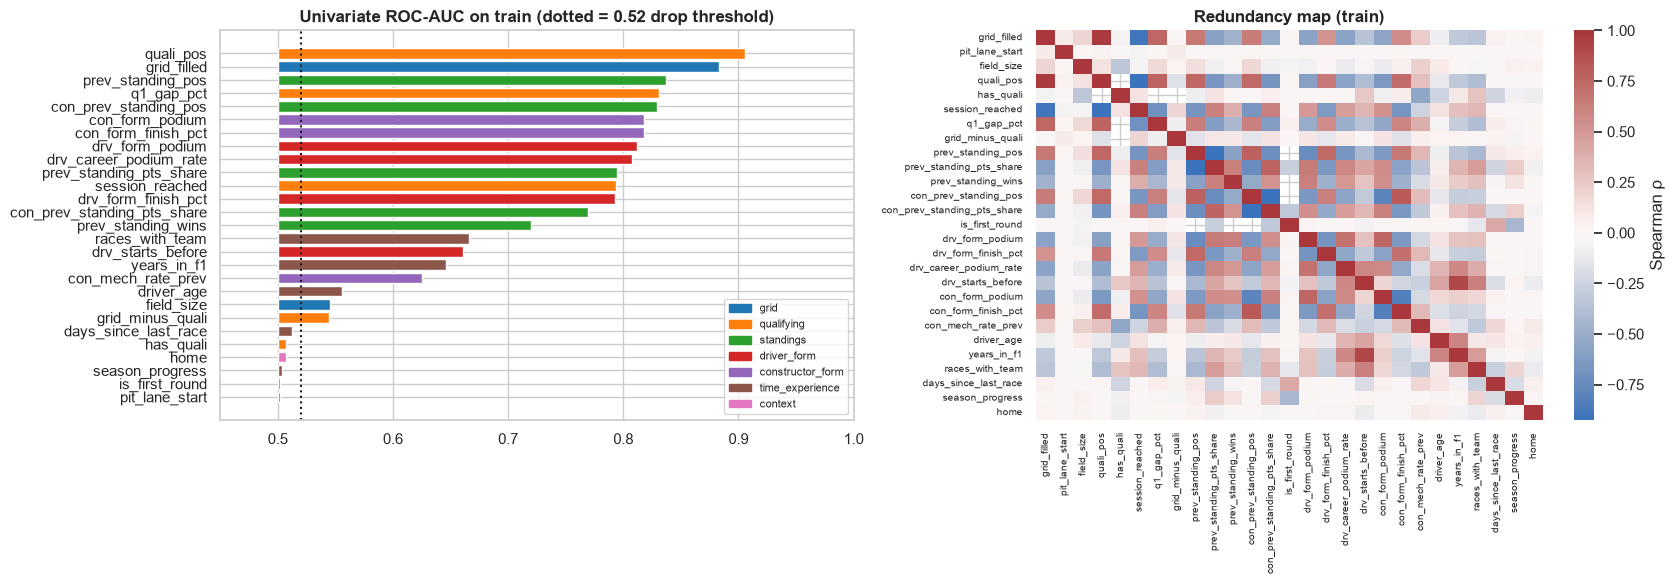

In [316]:
def signed_auc(y, x):
    a = auc_safe(y, x)
    return (a, "+") if a >= .5 else (1 - a, "−")

ev_rows = []
for gname, feats in GROUPS.items():
    for f in feats:
        a, sign = signed_auc(TR.podium, TR[f])
        ev_rows.append({"feature": f, "group": gname, "train AUC": a, "direction": sign, "coverage (train)": TR[f].notna().mean()})
evid = pd.DataFrame(ev_rows)
rho_m = TR[ALL_FEATS].corr(method="spearman").abs()

def redundant_with(f):
    others = rho_m[f].drop(f)
    strong = [o for o in others[others > .9].index if evid.set_index("feature").loc[o, "train AUC"] > evid.set_index("feature").loc[f, "train AUC"]]
    return ", ".join(strong)
evid["redundant with (|ρ|>0.9, stronger)"] = evid.feature.map(redundant_with)

SUPPORT = {"pit_lane_start", "has_quali", "is_first_round", "drv_starts_before", "field_size", "session_reached"}
def decide(r):
    if r.feature in SUPPORT: return "keep — support feature (tells the model how to read others)"
    if r["train AUC"] < .52: return "drop — no univariate signal"
    if r["redundant with (|ρ|>0.9, stronger)"]: return "keep, flag redundancy — ablation decides"
    return "keep — signal"
evid["decision"] = evid.apply(decide, axis=1)
display(evid.sort_values("train AUC", ascending=False).style.format({"train AUC": "{:.3f}", "coverage (train)": "{:.0%}"})
        .bar(subset=["train AUC"], vmin=.5, vmax=1, color="#7fb3d5").hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
e = evid.sort_values("train AUC")
pal = dict(zip(GROUPS, sns.color_palette("tab10", len(GROUPS))))
axes[0].barh(e.feature, e["train AUC"] - .5, left=.5, color=[pal[g] for g in e.group])
axes[0].axvline(.52, ls=":", c="k"); axes[0].set_xlim(.45, 1)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in pal.values()], labels=list(pal), loc="lower right", fontsize=8)
axes[0].set_title("Univariate ROC-AUC on train (dotted = 0.52 drop threshold)")
sns.heatmap(TR[ALL_FEATS].corr(method="spearman"), cmap="vlag", center=0, ax=axes[1], cbar_kws={"label": "Spearman ρ"})
axes[1].set_title("Redundancy map (train)"); axes[1].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

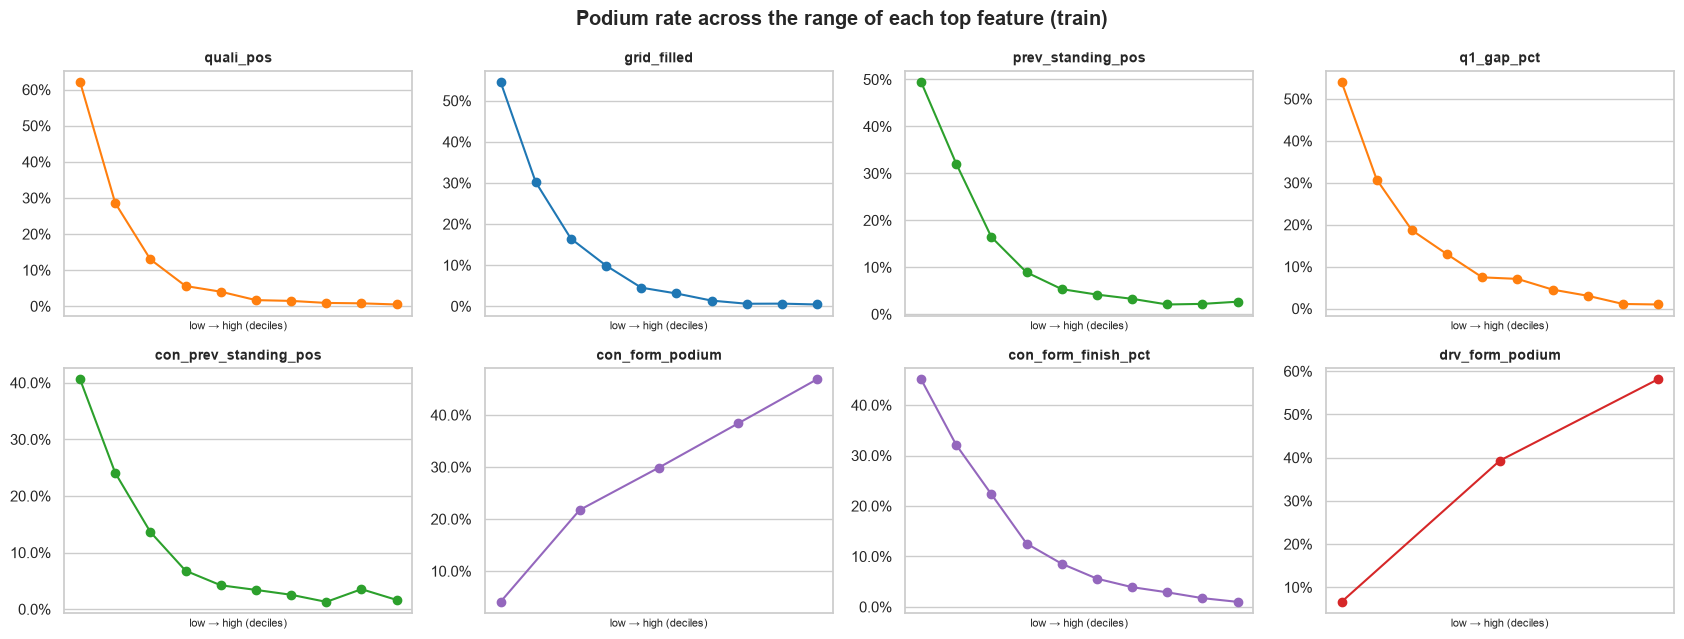

In [317]:
# How each of the top features relates to podium probability (train), binned into deciles
top8 = evid.sort_values("train AUC", ascending=False).feature.head(8).tolist()
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for ax, f in zip(axes.ravel(), top8):
    d = TR[[f, "podium"]].dropna()
    try:
        bins = pd.qcut(d[f], 10, duplicates="drop")
    except ValueError:
        bins = d[f]
    r = d.groupby(bins, observed=True).podium.mean()
    ax.plot(range(len(r)), r.values, marker="o", color=pal[evid.set_index("feature").loc[f, "group"]])
    ax.set_title(f, fontsize=10); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xticks([])
    ax.set_xlabel("low → high (deciles)", fontsize=8)
fig.suptitle("Podium rate across the range of each top feature (train)", fontweight="bold")
plt.tight_layout(); plt.show()

### Empirical check: does each group add anything on top of the previous ones?
Univariate evidence can't see interactions or redundancy, so we also add groups **one at a time** to a simple logistic regression (fit on train, scored on validation). This is the "trial" half of the justification — it complements the ablation the modeling stage will run (ablation *removes* one group at a time from the full model).

model,added group,n features,ROC-AUC,PR-AUC,F1,Δ PR-AUC
grid only,grid,3,0.909,0.640,0.674,
+ qualifying,qualifying,8,0.924,0.689,0.689,+0.049
+ standings,standings,14,0.931,0.735,0.680,+0.046
+ driver_form,driver_form,18,0.932,0.732,0.700,-0.003
+ constructor_form,constructor_form,21,0.932,0.733,0.694,+0.001
+ time_experience,time_experience,26,0.933,0.736,0.691,+0.003
+ context,context,27,0.933,0.736,0.691,-0.000


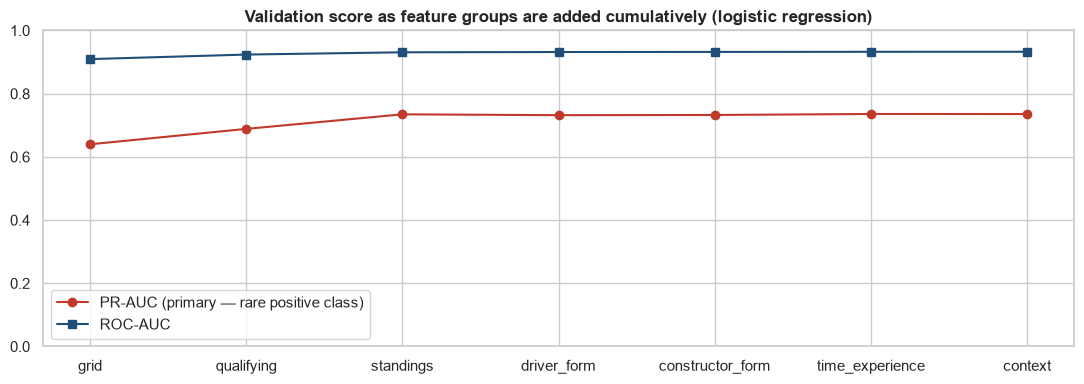

In [318]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score

INDICATOR_COLS = ["q1_gap_pct", "session_reached", "drv_form_podium", "con_form_podium", "con_mech_rate_prev", "days_since_last_race"]
# Not here: standings positions (missing only in round 1 now, which is_first_round already says) and driver_age (never missing).

class F1Prep(BaseEstimator, TransformerMixin):
    # Domain fills -> missing indicators -> median imputation -> standard scaling. All statistics learned in fit().
    def __init__(self, feats, scale=True):
        self.feats, self.scale = feats, scale
    def _domain(self, X):
        Z = X[self.feats].copy()
        if "quali_pos" in Z: Z["quali_pos"] = Z.quali_pos.fillna(X.grid_filled)      # no qualifying -> grid is the best pre-race proxy
        if "grid_minus_quali" in Z: Z["grid_minus_quali"] = Z.grid_minus_quali.fillna(0)
        for c in INDICATOR_COLS:
            if c in Z: Z[c + "_missing"] = X[c].isna().astype(float)
        return Z.astype(float)
    def fit(self, X, y=None):
        Z = self._domain(X)
        self.medians_ = Z.median()
        Z = Z.fillna(self.medians_)
        self.mu_, self.sd_ = Z.mean(), Z.std().replace(0, 1)
        self.columns_ = Z.columns
        return self
    def transform(self, X):
        Z = self._domain(X).fillna(self.medians_)
        return ((Z - self.mu_) / self.sd_ if self.scale else Z)[self.columns_]

def best_threshold(y, p):
    qs = np.unique(np.quantile(p, np.linspace(.5, .99, 60)))
    return qs[np.argmax([f1_score(y, p >= t) for t in qs])]

def fit_predict(feats, train, d, prep_fit_on=None):
    prep = F1Prep(feats).fit(prep_fit_on if prep_fit_on is not None else train)
    lr = LogisticRegression(max_iter=3000, class_weight="balanced").fit(prep.transform(train), train.podium)
    return lr.predict_proba(prep.transform(d))[:, 1]

def paired_bootstrap(d, p_a, p_b, B=1000, seed=0):
    # Resample whole RACES of the evaluation set (rows in one race are dependent); returns Δ PR-AUC (b − a) with 95% CI.
    rng = np.random.default_rng(seed)
    ids = d.raceId.values
    races_u = np.unique(ids)
    idx_by_race = {r: np.where(ids == r)[0] for r in races_u}
    y = d.podium.values
    deltas = []
    for _ in range(B):
        idx = np.concatenate([idx_by_race[r] for r in rng.choice(races_u, len(races_u), replace=True)])
        if y[idx].sum() == 0: continue
        deltas.append(average_precision_score(y[idx], p_b[idx]) - average_precision_score(y[idx], p_a[idx]))
    deltas = np.array(deltas)
    return average_precision_score(y, p_b) - average_precision_score(y, p_a), np.percentile(deltas, 2.5), np.percentile(deltas, 97.5)

def fit_eval(feats, train, evals, prep_fit_on=None):
    prep = F1Prep(feats).fit(prep_fit_on if prep_fit_on is not None else train)
    lr = LogisticRegression(max_iter=3000, class_weight="balanced").fit(prep.transform(train), train.podium)
    p_tr = lr.predict_proba(prep.transform(train))[:, 1]
    thr = best_threshold(train.podium, p_tr)            # threshold chosen on TRAIN only
    out = {}
    for name, d in evals.items():
        p = lr.predict_proba(prep.transform(d))[:, 1]
        out[name] = {"ROC-AUC": roc_auc_score(d.podium, p), "PR-AUC": average_precision_score(d.podium, p), "F1": f1_score(d.podium, p >= thr)}
    return out

inc_rows, used = [], []
for gname, feats in GROUPS.items():
    used = used + feats
    r = fit_eval(used, TR, {"val": VA})["val"]
    inc_rows.append({"model": "grid only" if gname == "grid" else f"+ {gname}", "added group": gname, "n features": len(used), **r})
inc = pd.DataFrame(inc_rows)
inc["Δ PR-AUC"] = inc["PR-AUC"].diff()
display(inc.style.format({"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}", "F1": "{:.3f}", "Δ PR-AUC": "{:+.3f}"}, na_rep="").hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(inc["added group"], inc["PR-AUC"], marker="o", label="PR-AUC (primary — rare positive class)", color="#c0392b")
ax.plot(inc["added group"], inc["ROC-AUC"], marker="s", label="ROC-AUC", color="#1f4e79")
ax.set_title("Validation score as feature groups are added cumulatively (logistic regression)"); ax.legend(); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

In [319]:
dropped = evid[evid.decision.str.startswith("drop")].feature.tolist()
FEATURES = [f for f in ALL_FEATS if f not in dropped]
FEATURE_GROUPS = {g: [f for f in fs if f in FEATURES] for g, fs in GROUPS.items()}
note("IV · Selection",
     f"{len(FEATURES)} of {len(ALL_FEATS)} candidate features kept (dropped: {', '.join(dropped) or 'none'}). "
     f"Cumulative groups on validation: grid-only PR-AUC {inc['PR-AUC'].iloc[0]:.3f} → all groups {inc['PR-AUC'].iloc[-1]:.3f}.",
     "Keep redundant-but-informative features flagged; let the modeling-stage ablation (remove one group at a time) confirm each group.")

> 📝 **Logged (IV · Selection)** — 24 of 27 candidate features kept (dropped: days_since_last_race, season_progress, home). Cumulative groups on validation: grid-only PR-AUC 0.640 → all groups 0.736.  
> ➜ *Keep redundant-but-informative features flagged; let the modeling-stage ablation (remove one group at a time) confirm each group.*

## Preprocessing — and what it does to the data
The pipeline (`F1Prep`), fitted on training data only:
1. **Domain fills** first, because they carry meaning: missing `quali_pos` → the driver's grid slot (the best pre-race proxy); missing `grid_minus_quali` → 0.
2. **Missing indicators** for features whose absence is informative (no qualifying data, debut driver, round 1).
3. **Median imputation** (medians from train).
4. **Standard scaling** (mean/sd from train) — needed for logistic regression and the neural net, harmless for trees.

feature,missing before,filled with,indicator column added,NaN after,mean after,sd after
grid_filled,0%,nothing missing,,0,0.00,1.00
pit_lane_start,0%,nothing missing,,0,-0.00,1.00
field_size,0%,nothing missing,,0,0.00,1.00
quali_pos,63%,domain fill: grid position,,0,-0.00,1.00
has_quali,0%,nothing missing,,0,0.00,1.00
session_reached,74%,median of train = 2,yes,0,-0.00,1.00
q1_gap_pct,64%,median of train = 1.5,yes,0,-0.00,1.00
grid_minus_quali,63%,domain fill: 0 (no penalty known),,0,0.00,1.00
prev_standing_pos,12%,median of train = 12,yes,0,0.00,1.00
prev_standing_pts_share,0%,nothing missing,,0,-0.00,1.00


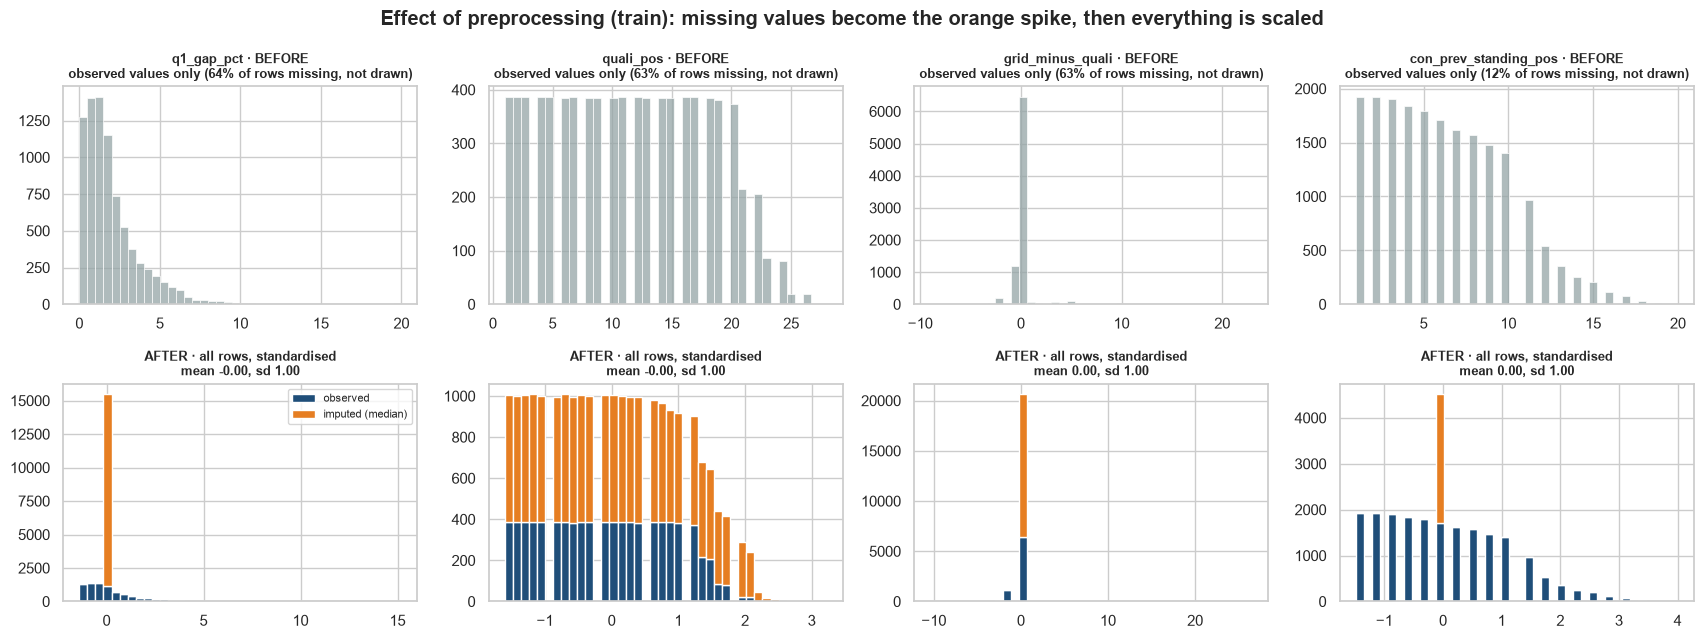

Columns after prep: 32 (24 features + 8 missing indicators); NaN after prep: 0


In [320]:
prep_demo = F1Prep(FEATURES).fit(TR)
Ztr = prep_demo.transform(TR)

# What happened to every feature, in one table
how = []
for c in FEATURES:
    miss = TR[c].isna().mean()
    if c == "quali_pos": method = "domain fill: grid position"
    elif c == "grid_minus_quali": method = "domain fill: 0 (no penalty known)"
    elif c in ("prev_standing_pos", "con_prev_standing_pos"): method = f"round 2+: behind last listed (in build_features); round 1: median = {prep_demo.medians_[c]:.3g}"
    elif miss > 0: method = f"median of train = {prep_demo.medians_[c]:.3g}"
    else: method = "nothing missing"
    how.append({"feature": c, "missing before": miss, "filled with": method,
                "indicator column added": "yes" if c + "_missing" in Ztr.columns else "", "NaN after": int(Ztr[c].isna().sum()),
                "mean after": Ztr[c].mean(), "sd after": Ztr[c].std()})
display(pd.DataFrame(how).style.format({"missing before": "{:.0%}", "mean after": "{:.2f}", "sd after": "{:.2f}"}).hide(axis="index"))

# Before/after for the features with most missing values: imputed rows coloured separately
show = [c for c in sorted(FEATURES, key=lambda c: -TR[c].isna().mean()) if TR[c].nunique() > 5][:4]
fig, axes = plt.subplots(2, len(show), figsize=(4.3 * len(show), 6.5))
axes = np.atleast_2d(axes).reshape(2, -1)
for i, c in enumerate(show):
    was_na = TR[c].isna().values
    sns.histplot(TR[c].dropna(), bins=40, ax=axes[0, i], color="#95a5a6")
    axes[0, i].set_title(f"{c} · BEFORE\nobserved values only ({was_na.mean():.0%} of rows missing, not drawn)", fontsize=9)
    edges = np.histogram_bin_edges(Ztr[c], bins=40)
    fill = {"quali_pos": "filled: grid position", "grid_minus_quali": "filled: 0"}.get(c, "filled: train median")
    axes[1, i].hist([Ztr[c][~was_na], Ztr[c][was_na]], bins=edges, stacked=True, color=["#1f4e79", "#e67e22"],
                    label=["observed", fill])
    axes[1, i].set_title(f"AFTER · all rows, standardised\nmean {Ztr[c].mean():.2f}, sd {Ztr[c].std():.2f}", fontsize=9)
    axes[1, i].legend(fontsize=8)
for ax in axes.ravel(): ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Effect of preprocessing (train): filled-in values in orange (a median fill piles them on one value), then everything is scaled", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"Columns after prep: {Ztr.shape[1]} ({len(FEATURES)} features + {Ztr.shape[1] - len(FEATURES)} missing indicators); NaN after prep: {int(Ztr.isna().sum().sum())}")

**How to read this.** The top row only *can* draw observed values, because a missing value has no position on the x-axis, so a feature that is 63% missing shows just the other 37%. In the bottom row, every row is present:
1. **Imputation came first.** How it looks depends on the fill. A **median** fill puts every missing row on **one value**: the orange spike (e.g. `q1_gap_pct`). A **domain** fill spreads them out: `quali_pos` copies each driver's grid slot, so the orange rows cover the whole range; `grid_minus_quali` is filled with 0, which is where most real values already are.
2. **Then standardisation** (subtract the train mean, divide by the train sd) was applied to *all* rows, imputed ones included. That's why mean ≈ 0 and sd ≈ 1 is computed over 100% of rows, not just the observed 37%.

**Why impute at all?** Logistic regression and neural networks can't take `NaN`; a single model-ready table also keeps every model comparable.
**Why the median?** It's robust to outliers, and it's learned on train only.
**Why is the spike not a problem?** For median-filled features, the `<feature>_missing` indicator column tells the model "this value was filled in". It can then learn a separate effect for those rows instead of mistaking them for typical drivers.

**But 63% imputed is a lot.** For qualifying-based features, most of those rows are pre-1994 seasons with no qualifying table. That is exactly the question E3 tests: is it better to train only on seasons where the feature is actually observed?

## Preprocessing-order experiments
The brief asks for at least two. Each one changes **only the order or scope of a step** and keeps everything else fixed (same rows, features, model = balanced logistic regression, threshold chosen on train). Each is shown in its own cell so the before/after is visible.

### E1 · Where are imputation/scaling statistics learned: train only vs all data?

In [321]:
ALLD = pd.concat([TR, VA, TE])
e1 = pd.DataFrame({
    "fit on train only (correct)": {f"{s} {m}": v for s, r in fit_eval(FEATURES, TR, {"val": VA, "test": TE}).items() for m, v in r.items()},
    "fit on train+val+test (leaky)": {f"{s} {m}": v for s, r in fit_eval(FEATURES, TR, {"val": VA, "test": TE}, prep_fit_on=ALLD).items() for m, v in r.items()},
}).T
display(e1.style.format("{:.4f}"))

,val ROC-AUC,val PR-AUC,val F1,test ROC-AUC,test PR-AUC,test F1
fit on train only (correct),0.9325,0.7339,0.6971,0.9370,0.7047,0.6681
fit on train+val+test (leaky),0.9326,0.7343,0.6971,0.9370,0.7048,0.6681


Expect a **small** difference: medians and means move little when 3 extra seasons are added to 70. The point is not the size of the gain — it's that the leaky version *uses information from the evaluation seasons*, so any gain it shows is fake. We keep "fit on train only" regardless.

### E2 · Feature engineering before vs after the population filter
Do we compute form features on the full results history (including non-starters and the Indy 500), *then* filter rows — or filter first and compute form only from real starts? The order changes the features: a DNQ counts as a "non-podium race" in the first version.

In [322]:
full_hist = collapse_shared_drives(df["results"].merge(df["races"][["raceId", "year", "round", "circuitId", "name", "date"]].rename(columns={"name": "race"}), on="raceId")
                                   .merge(df["status"], on="statusId"))
full_hist["status_cat"] = full_hist.status.map(classify_status)
FX_e2 = build_features(base, df, history=full_hist)
FX_e2["split"] = np.select([FX_e2.year <= 2019, FX_e2.year <= 2021], ["train", "val"], "test")
e2 = pd.DataFrame({
    "filter → features (our pipeline)": {f"{s} {m}": v for s, r in fit_eval(FEATURES, TR, {"val": VA, "test": TE}).items() for m, v in r.items()},
    "features → filter": {f"{s} {m}": v for s, r in fit_eval(FEATURES, FX_e2[FX_e2.split == "train"],
                                                              {"val": FX_e2[FX_e2.split == "val"], "test": FX_e2[FX_e2.split == "test"]}).items() for m, v in r.items()},
}).T
display(e2.style.format("{:.4f}"))
cmp_e2 = FX[["raceId", "driverId", "drv_form_podium"]].merge(FX_e2[["raceId", "driverId", "drv_form_podium"]], on=["raceId", "driverId"], suffixes=("", "_e2"))
diff_rows = (cmp_e2.drv_form_podium.fillna(-1) != cmp_e2.drv_form_podium_e2.fillna(-1)).mean()
print(f"Rows whose driver-form value changes with the order: {pct(diff_rows)} (concentrated in eras with many non-qualifiers)")

,val ROC-AUC,val PR-AUC,val F1,test ROC-AUC,test PR-AUC,test F1
filter → features (our pipeline),0.9325,0.7339,0.6971,0.9370,0.7047,0.6681
features → filter,0.9323,0.7329,0.6996,0.9370,0.7058,0.6694


Rows whose driver-form value changes with the order: 0.8% (concentrated in eras with many non-qualifiers)


### E3 (bonus) · Training window: full history vs seasons with qualifying data vs knockout-format seasons
Not an ordering question, but the decision Clue 14 left open: does 70 years of a different sport help or hurt when predicting 2022+? A third option trains only on seasons with the same qualifying format as the test years (knockout, 2006+): fewer rows, but every feature means the same thing as in 2022+.

In [323]:
first_q_season = int(FX.groupby("year").has_quali.mean().pipe(lambda s: s[s > .5].index.min()))
TR_mod = TR[TR.year >= first_q_season]
TR_ko = TR[TR.year >= KNOCKOUT_START]
e3 = pd.DataFrame({
    f"full history (≤2019, {len(TR):,} rows)": {f"{s} {m}": v for s, r in fit_eval(FEATURES, TR, {"val": VA, "test": TE}).items() for m, v in r.items()},
    f"modern window ({first_q_season}–2019, {len(TR_mod):,} rows)": {f"{s} {m}": v for s, r in fit_eval(FEATURES, TR_mod, {"val": VA, "test": TE}).items() for m, v in r.items()},
    f"knockout window ({KNOCKOUT_START}–2019, {len(TR_ko):,} rows)": {f"{s} {m}": v for s, r in fit_eval(FEATURES, TR_ko, {"val": VA, "test": TE}).items() for m, v in r.items()},
}).T
display(e3.style.format("{:.4f}"))
print("Decide E3 on VALIDATION PR-AUC only; the test column is shown for transparency, not for choosing.")

,val ROC-AUC,val PR-AUC,val F1,test ROC-AUC,test PR-AUC,test F1
"full history (≤2019, 22,533 rows)",0.9325,0.7339,0.6971,0.9370,0.7047,0.6681
"modern window (1994–2019, 10,136 rows)",0.9342,0.7359,0.6831,0.9370,0.7129,0.6590
"knockout window (2006–2019, 5,760 rows)",0.9346,0.7356,0.6885,0.9372,0.7171,0.6591


Decide E3 on VALIDATION PR-AUC only; the test column is shown for transparency, not for choosing.


### Making the decision when the numbers look the same
Similar scores in a table don't tell you whether a difference is **real or noise**. Validation is only ~40 races, so a different set of 40 races could flip a difference of 0.005. We therefore measure the noise directly:

* **Paired bootstrap over races.** Resample the validation races with replacement 1,000 times. Each time, score *both* options on the same resampled races and record the difference in PR-AUC. The middle 95% of those differences is a **confidence interval for "how much better is option B than A"**.
* **Decision rule (fixed before looking at the result):**
  * if the interval is entirely above or below 0 → the difference is real → **pick the better option**;
  * if it contains 0 → the options are **tied** → choose by the stated *tie-breaker*, a principled reason that doesn't depend on the score.

| Experiment | Option A | Option B | Tie-breaker |
|---|---|---|---|
| E1 | prep fit on train | prep fit on all data | always A: B uses evaluation data, so even a "win" would be fake |
| E2 | filter → features | features → filter | A: form computed from real starts matches what the features mean |
| E3 | full history | modern window | B: features are *observed* instead of mostly imputed, and the training population looks like the 2022+ test population |
| E3b | modern window | knockout window (2006+) | A: ~30% more races to learn from, and the format change is already handled by the `session_reached` indicator |

So "no change" is a legitimate result. It means the decision is made by the tie-breaker, and the report says exactly that.

experiment,Δ val PR-AUC (B − A),95% CI low,95% CI high,decision,why
E1 · prep fit: train only (A) vs all data (B),+0.0004,-0.0001,+0.0016,A,tie (CI contains 0) → tie-breaker picks A; E1 is always A (B leaks)
E2 · filter→features (A) vs features→filter (B),-0.0010,-0.0047,+0.0023,A,tie (CI contains 0) → tie-breaker picks A
E3 · full history (A) vs modern window (B),+0.0020,-0.0189,+0.0190,B,tie (CI contains 0) → tie-breaker picks B
E3b · modern window (A) vs knockout window (B),-0.0002,-0.0156,+0.0121,A,tie (CI contains 0) → tie-breaker picks A


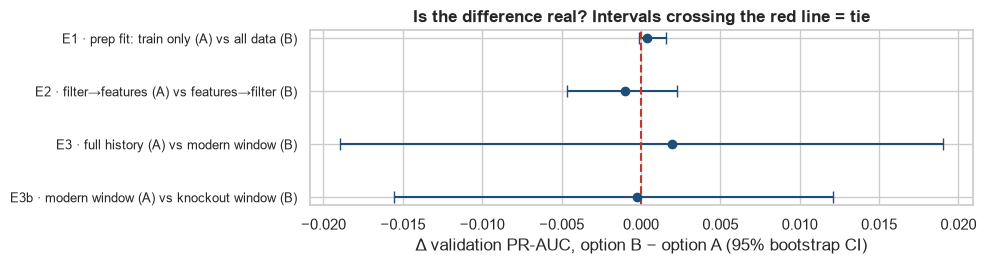

Training window chosen: modern


In [324]:
pairs = {
    "E1 · prep fit: train only (A) vs all data (B)": (fit_predict(FEATURES, TR, VA), fit_predict(FEATURES, TR, VA, prep_fit_on=ALLD), "A"),
    "E2 · filter→features (A) vs features→filter (B)": (fit_predict(FEATURES, TR, VA),
                                                        fit_predict(FEATURES, FX_e2[FX_e2.split == "train"], FX_e2[FX_e2.split == "val"].set_index(["raceId", "driverId"]).loc[
                                                            pd.MultiIndex.from_frame(VA[["raceId", "driverId"]])].reset_index()), "A"),
    "E3 · full history (A) vs modern window (B)": (fit_predict(FEATURES, TR, VA), fit_predict(FEATURES, TR_mod, VA), "B"),
    "E3b · modern window (A) vs knockout window (B)": (fit_predict(FEATURES, TR_mod, VA), fit_predict(FEATURES, TR_ko, VA), "A"),
}
dec = []
for name, (pa, pb, tie) in pairs.items():
    dlt, lo, hi = paired_bootstrap(VA, pa, pb)
    if lo > 0: choice, why = "B", "B is better (CI above 0)"
    elif hi < 0: choice, why = "A", "A is better (CI below 0)"
    else: choice, why = tie, f"tie (CI contains 0) → tie-breaker picks {tie}"
    if name.startswith("E1"): choice, why = "A", why + "; E1 is always A (B leaks)"
    dec.append({"experiment": name, "Δ val PR-AUC (B − A)": dlt, "95% CI low": lo, "95% CI high": hi, "decision": choice, "why": why})
dec = pd.DataFrame(dec)
display(dec.style.format({"Δ val PR-AUC (B − A)": "{:+.4f}", "95% CI low": "{:+.4f}", "95% CI high": "{:+.4f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(10, 2.8))
yy = np.arange(len(dec))[::-1]
ax.errorbar(dec["Δ val PR-AUC (B − A)"], yy, xerr=[dec["Δ val PR-AUC (B − A)"] - dec["95% CI low"], dec["95% CI high"] - dec["Δ val PR-AUC (B − A)"]],
            fmt="o", color="#1f4e79", ecolor="#1f4e79", capsize=4)
ax.axvline(0, color="#c0392b", ls="--"); ax.set_yticks(yy); ax.set_yticklabels(dec.experiment, fontsize=9)
ax.set_xlabel("Δ validation PR-AUC, option B − option A (95% bootstrap CI)")
ax.set_title("Is the difference real? Intervals crossing the red line = tie")
plt.tight_layout(); plt.show()
decision_of = lambda e: dec.loc[dec.experiment.str.startswith(e + " "), "decision"].iat[0]
best_window = "knockout" if decision_of("E3b") == "B" else "modern" if decision_of("E3") == "B" else "full"
print("Training window chosen:", best_window)

In [325]:
note("IV · Preprocessing",
     f"E1: train-only vs leaky fit Δ val PR-AUC = {e1['val PR-AUC'].iloc[1] - e1['val PR-AUC'].iloc[0]:+.4f}; "
     f"E2: filter→features vs features→filter Δ = {e2['val PR-AUC'].iloc[1] - e2['val PR-AUC'].iloc[0]:+.4f} ({pct(diff_rows)} of form values change); "
     f"E3 → {best_window} training window (E3: {dec.loc[dec.experiment.str.startswith('E3 '), 'why'].iat[0]}; E3b: {dec.loc[dec.experiment.str.startswith('E3b'), 'why'].iat[0]}).",
     "Pipeline order: clean & filter → features → split → fit prep on train only. Training window decided by paired bootstrap + pre-stated tie-breaker.")

> 📝 **Logged (IV · Preprocessing)** — E1: train-only vs leaky fit Δ val PR-AUC = +0.0004; E2: filter→features vs features→filter Δ = -0.0010 (0.8% of form values change); E3 → modern training window (E3: tie (CI contains 0) → tie-breaker picks B; E3b: tie (CI contains 0) → tie-breaker picks A).  
> ➜ *Pipeline order: clean & filter → features → split → fit prep on train only. Training window decided by paired bootstrap + pre-stated tie-breaker.*

In [326]:
# Hand-off to the modeling stage
import json
keep_cols = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "race", "split", "podium"] + FEATURES
FX[keep_cols].to_csv(OUT / "modeling_table.csv", index=False)
json.dump({"features": FEATURES, "groups": FEATURE_GROUPS, "train_window_start": {"full": int(FX.year.min()), "modern": first_q_season, "knockout": KNOCKOUT_START}[best_window],
           "split": {"train": "<=2019", "val": "2020-2021", "test": ">=2022"}, "target": "podium (credited, min positionOrder <= 3)"},
          open(OUT / "feature_spec.json", "w"), indent=2)
print(f"Saved modeling_table.csv ({len(FX):,} rows × {len(keep_cols)} cols) and feature_spec.json")

Saved modeling_table.csv (24,666 rows × 34 cols) and feature_spec.json


---
## 🗂 Case closed — findings → decisions

Every `note(...)` from the investigation, in order. This table goes straight into the report's data-cleaning and feature-justification sections.

In [327]:
case = pd.DataFrame(CASE_LOG)
with pd.option_context("display.max_colwidth", None):
    display(case.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))
case.to_csv(OUT / "eda_case_log.csv", index=False)

keep = ["raceId", "driverId", "constructorId", "year", "round", "date", "circuitId", "era", "n_result_rows",
        "grid", "grid_clean", "grid_filled", "pit_lane_start", "quali_pos", "q1", "q2", "q3", "q1_gap_pct",
        "prev_standing_pos", "prev_standing_pts", "prev_wins", "drv_form_podium", "drv_form_finish",
        "drv_career_podiums", "drv_starts_before", "con_form_podium", "con_form_best", "status_cat", "podium"]
clean[[c for c in keep if c in clean.columns]].to_csv(OUT / "modeling_base_eda.csv", index=False)
print("Saved:", *sorted(p.name for p in OUT.iterdir()))

clue,finding,decision
0 · Scene,"Tables start at different seasons: qualifying from 1994, lap_times from 1996, pit_stops from 2011; 0 calendar races have no results.",Features from late-starting tables will be structurally missing for early seasons; races without results are dropped (no label).
1 · Sentinels,"160,076 '\N' cells across 30 columns; grid uses 0 as a second, disguised code; long pit stops are written as m:ss.sss strings.",Replace '\N'/'' with NaN on copies; parse dates and m:ss durations to seconds; treat grid==0 separately (Clue 5).
2 · Keys,Primary-key problems: 0; FK orphans: 0. Natural-key duplicates in: results (91).,"Surrogate keys are trustworthy; the natural grain (raceId, driverId) is NOT unique and must be fixed explicitly (Clue 3)."
3 · Grain,"176 results rows sit in 85 duplicated (raceId, driverId) groups, 158 of the rows fall in 1950–57 (shared drives), 18 later (inspect individually).","Collapse to one row per pair: features from the started car (grid>0; tie → most laps, then lowest resultId), target = podium in any car; keep n_result_rows."
4 · Target,Podium base rate is 12.7% of driver-race rows overall but moves with field size (≈3/entrants); 18 races don't have exactly 3 podium rows/drivers; the Indy 500 (1950–60) is a separate field (96.3% of its drivers never raced elsewhere).,Target = credited podium (deduped). Exclude Indianapolis 500 races by name. Report base rate per split; prefer PR-AUC as a rare-class metric.
5 · Population,"1,621 rows never started (concentrated in the pre-qualifying era); grid=0 also contains 72 genuine pit-lane/late starters.","Modeling rows = starters only (status not in non_start) and not Indy 500. Encode grid=0 for starters as pit_lane_start=1 with grid set to back of field, not 0."
6 · Qualifying,Qualifying rows exist for >50% of starters only from 1994; q1/q2/q3 structure only from the knockout era. Grid differs from qualifying for 23.9% of starters with both.,"Use grid as the always-available start feature; add qualifying features (position, gap-to-fastest %) with a has_quali indicator, or restrict training to seasons with coverage — compare both in the preprocessing experiments."
7 · Grid,"Grid alone reaches ROC-AUC ≈ 0.886; pole converts to podium 64.5% of the time, with clear era variation (reliability, DRS, field size).",Grid is the baseline feature and the 'simplest reasonable model' to beat; add era/season context or restrict the training window.
8 · Leakage,"points, laps, milliseconds, fastest-lap fields, status, position(Order) are post-race (AUC near 1 or explained by the outcome). Same-race standings AUC 0.924 vs before-race 0.841 — the gap is pure leakage.",Ban all post-race columns. Standings features use merge_asof on round with allow_exact_matches=False (standings before this race); round-1 values are missing by design → indicator + fill.
9 · Form,"Backward-looking form passes the alibi test (0 mismatches). Best leak-safe signals after grid: quali_pos (0.91), grid_filled (0.89), prev_standing_pos (0.84), q1_gap_pct (0.83).",Use shift(1)-then-roll form features on driver and constructor; ablation groups = grid / qualifying / standings / driver form / constructor form.


Saved: column_timing_audit.csv eda_case_log.csv feature_spec.json modeling_base_eda.csv modeling_table.csv status_mapping.csv


### What this notebook hands to the modeling stage
`outputs/modeling_table.csv` (one row per driver-race, split column, target, selected features) and `outputs/feature_spec.json` (feature list, ablation groups, training window).

* **Grain:** one row per `(raceId, driverId)`; started-car features, credited-podium label; `n_result_rows` kept for audit.
* **Population:** starters only, Indianapolis 500 excluded, pit-lane starters kept with a flag.
* **Allowed feature families (all known before lights out):** grid · qualifying (position, gap-to-fastest, availability flag) · standings *before* the race · driver form · constructor form · home flag · era/season context.
* **Banned:** points, laps, time/milliseconds, fastest-lap fields, status, position/positionText/positionOrder, same-race standings, pit stops and lap times of the current race.
* **Limitations to write up:** qualifying-coverage drift; era sensitivity of grid→podium; cold-start form for one-off entrants; manual status and nationality mappings; sprint data absent from training.

> Reminder for XAI later: a feature being important to the model means the model *relies* on it, not that it *causes* podiums.